# 딥러닝기초 파일별 3 · 02_pytorch (Day02)

**한 줄 요약** · Day02 강의 97셀을 원본 순서대로 정리 · 모델 · XOR · MLP → 분류 계약 → optimizer → DataLoader → 평가 · 진단

- **원본** · `7. 딥러닝/00_딥러닝_기초/실습/02_pytorch.ipynb` (원본 파일은 그대로 둠)
- **종합 정리본** · `00_최소선/06_딥러닝기초·PyTorch` 딥러닝기초-1 (텐서 · autograd는 그쪽에서 1회) · 딥러닝기초-2는 아직 없음

## 🎯 학습 목표

이 노트북을 끝내면 **자료를 보지 않고** 다음을 할 수 있어야 함

1. `nn.Module` · `nn.Parameter` · `nn.Linear`가 관리하는 것과 관리하지 않는 것을 구분한다
2. XOR이 Linear 하나로 안 되고 Linear → ReLU → Linear로 되는 이유를 숫자로 설명한다
3. 분류에서 raw logits와 정수 정답을 `CrossEntropyLoss`에 넣고, Softmax를 앞에 넣으면 안 되는 이유를 말한다
4. zero_grad → forward → loss → backward → step 순서로 optimizer 학습 loop를 짠다
5. Dataset · DataLoader · device · eval · no_grad로 학습과 평가 pipeline을 연결하고 오류를 진단한다

## 어디에 쓰나

<table width="100%" style="width:100%; table-layout:auto">
<thead>
<tr>
<th style="text-align: left;">실제 상황</th>
<th style="text-align: left;">이 권에서 배우는 것</th>
</tr>
</thead>
<tbody>
<tr>
<td style="text-align: left;">PyTorch 모델 class를 직접 만들 때</td>
<td style="text-align: left;">Module · Parameter · Linear (2장)</td>
</tr>
<tr>
<td style="text-align: left;">분류 모델의 마지막 층 · 손실을 정할 때</td>
<td style="text-align: left;">logits · CrossEntropyLoss (4장)</td>
</tr>
<tr>
<td style="text-align: left;">학습 loop를 처음부터 짤 때</td>
<td style="text-align: left;">optimizer 다섯 줄 · DataLoader (5 · 6 · 8장)</td>
</tr>
<tr>
<td style="text-align: left;">검증 정확도가 이상할 때</td>
<td style="text-align: left;">eval · no_grad · correct/total (7 · 8장)</td>
</tr>
<tr>
<td style="text-align: left;">dtype · device · shape 에러를 만났을 때</td>
<td style="text-align: left;">진단 순서 (7장)</td>
</tr>
</tbody>
</table>

## 학습 지도

<img src="images/pdl3_map.png" alt="02_pytorch 학습 지도" width="837">

**예상 학습 시간** · 개념 2시간 + 실습 1시간 (GPU 없이 모든 셀이 몇 초)

## 목차

<table width="100%" style="width:100%; table-layout:auto">
<thead>
<tr>
<th style="text-align: left;">장</th>
<th style="text-align: left;">제목</th>
<th style="text-align: left;">이 장의 질문</th>
</tr>
</thead>
<tbody>
<tr>
<td style="text-align: left;">0</td>
<td style="text-align: left;">준비</td>
<td style="text-align: left;">실행 환경 · 원본 구성</td>
</tr>
<tr>
<td style="text-align: left;">1</td>
<td style="text-align: left;">Day1 회수</td>
<td style="text-align: left;">Day1 연산과 학습 책임을 새 변수 이름에서 다시 찾을 수 있는가?</td>
</tr>
<tr>
<td style="text-align: left;">2</td>
<td style="text-align: left;">직접 관리에서 모델 관리로</td>
<td style="text-align: left;">학습할 값을 모아 찾고, 계산을 한 모델 안에 묶으려면?</td>
</tr>
<tr>
<td style="text-align: left;">3</td>
<td style="text-align: left;">하나의 경계와 층 쌓기</td>
<td style="text-align: left;">직선 하나로 안 되는 XOR을 어떤 구조로 풀 수 있는가?</td>
</tr>
<tr>
<td style="text-align: left;">4</td>
<td style="text-align: left;">분류 모델의 출력과 loss 계약</td>
<td style="text-align: left;">분류 모델은 무엇을 출력하고, 어떤 정답과 함께 loss에 넣는가?</td>
</tr>
<tr>
<td style="text-align: left;">5</td>
<td style="text-align: left;">optimizer가 맡는 책임</td>
<td style="text-align: left;">parameter가 82개면 update · reset을 누가 맡고, 학습률 · optimizer는 어떻게 고르는가?</td>
</tr>
<tr>
<td style="text-align: left;">6</td>
<td style="text-align: left;">Dataset에서 현재 batch까지</td>
<td style="text-align: left;">500개를 어떤 묶음 · 순서로 주고, 계산 장소는 어떻게 맞추는가?</td>
</tr>
<tr>
<td style="text-align: left;">7</td>
<td style="text-align: left;">평가와 진단</td>
<td style="text-align: left;">평가 모드와 기록 끄기를 구분하고, 에러가 있거나 없는 잘못된 연결을 어떻게 찾는가?</td>
</tr>
<tr>
<td style="text-align: left;">8</td>
<td style="text-align: left;">종합 실습</td>
<td style="text-align: left;">Dataset → DataLoader → device → model → loss → backward → optimizer → 평가를 한 흐름으로 연결하면?</td>
</tr>
<tr>
<td style="text-align: left;">—</td>
<td style="text-align: left;">마무리 · 부록</td>
<td style="text-align: left;">오늘 배운 것 · 기억 확인 · 오답 노트 · 면접 · 요약표 · 복습일 · 원본 대응표 · 전체 코드</td>
</tr>
</tbody>
</table>

---
## 0. 준비

원본 셀 2와 같은 import에 OpenMP 설정 한 줄만 더함. **셀은 위에서부터 차례로 실행** (앞 섹션의 모델 class · 데이터 · loader를 이어서 씀).

<table width="100%" style="width:100%; table-layout:auto">
<thead>
<tr>
<th style="text-align: left;">항목</th>
<th style="text-align: left;">설정</th>
</tr>
</thead>
<tbody>
<tr>
<td style="text-align: left;">스레드</td>
<td style="text-align: left;"><code>torch.set_num_threads(1)</code> · 작은 텐서라 1개가 더 빠름 (CPU가 바쁠 때 수십 배 차이)</td>
</tr>
<tr>
<td style="text-align: left;">라이브러리</td>
<td style="text-align: left;"><code>torch</code> · <code>copy</code> · <code>warnings</code> (8장 그래프는 <code>matplotlib</code>)</td>
</tr>
<tr>
<td style="text-align: left;">seed</td>
<td style="text-align: left;">섹션마다 원본과 같은 값 (7 · 11 · 42 · 20260903 · 27182 …)</td>
</tr>
<tr>
<td style="text-align: left;">장치</td>
<td style="text-align: left;">6장부터 cuda → mps → cpu 순서로 고름 (원본과 같음)</td>
</tr>
<tr>
<td style="text-align: left;">원본 셀 수</td>
<td style="text-align: left;">97개 (Practice 안내 셀 9개 · 그림 셀 15개 · 빈 셀 1개 포함)</td>
</tr>
</tbody>
</table>

In [1]:
# 원본 셀 2: import · 출력 형식
import copy      # state_dict 깊은 복사 (5-4)
import os        # 환경 변수 (아래 OpenMP 설정)
import warnings  # 경고 잡기 (7-2)

import torch                                            # 텐서 · 자동 미분
from torch import nn                                    # 층 · 손실 함수
from torch.utils.data import DataLoader, TensorDataset  # 데이터 묶음 (6장)

torch.set_printoptions(precision=6, sci_mode=False)      # 소수 6자리 · 지수 표기 끔
torch.set_num_threads(1)  # 작은 텐서는 스레드 1개가 빠름 (다른 프로그램과 CPU 경쟁 방지)
# 8장 그래프와 torch를 한 커널에서 써도 안 죽게
os.environ.setdefault("KMP_DUPLICATE_LIB_OK", "TRUE")
print("PyTorch 버전:", torch.__version__.split("+")[0])  # 설치된 버전

PyTorch 버전: 2.11.0


### 원본 구성

- **Day1 회수** · 핵심 연산 · 짧은 API 확인 · 역할 찾기 · `b`까지 움직이기 (Practice PC-01)
- **모델로 묶기** · `nn.Parameter` · `nn.Module` · `nn.Linear` (PC-02)
- **하나의 Linear 경계** · AND · OR · XOR · 층 쌓기 · ReLU · XOR MLP (PC-03 · PC-04)
- **분류 계약** · logits · CrossEntropyLoss · Softmax 함정 · 82 parameter (PC-05)
- **optimizer** · step과 gradient · two moons · 학습률 · SGD vs Adam (PC-06 · PC-07)
- **Dataset → batch → device** (PC-08) · **평가와 pipeline** (PC-09) · **진단 · 다음 구조** (PC-10 · PC-11)

**원본 힌트**

- Practice PC-01 ~ PC-11 안내 셀은 별도 문제 파일(DAY02_PRACTICE_Q)로 가라는 안내라 여기서는 대응표에만 적음
- 원본 셀 23은 실제 오류(`AttributeError`)가 남 → 2-3에서 고침

---
## 1. Day1 회수

> **이 장의 흐름**
>
> - Day1을 다시 길게 배우지 않고 질문에 맞는 연산 · 역할만 회수
> - parameter가 둘만 돼도 관리 비용이 커지는 것을 확인

<img src="images/pdl3_roles.png" alt="Day1 학습 책임 여섯 가지" width="837">

**파이프라인 위치** · ⑤ 학습 — 예측 · 손실 · 기울기 · 업데이트 · reset

### 1-1. `A` 핵심 연산 고르기 · `reshape` · `squeeze` · `cat` · `stack` · `@` <sub>원본 셀 3 ~ 5</sub>

> 🎯 **질문을 먼저 정하면 어떤 연산을 고르고, 결과 shape를 어떻게 먼저 말하는가?**

💡 **쉽게 말하면**

- 연산 이름부터 외우지 않고 **무엇을 하려는지**(질문)를 먼저 고름.
- 모양 바꾸기 · 고르기 · 축 넣고 빼기 · 잇기 · 곱하기 중 하나.

**실행 흐름**

1. 만들기 · 모양
2. 행 · 구간 고르기
3. 축 빼고 넣기
4. 잇기 · 쌓기
5. 같은 위치 곱 · 행렬 곱

**먼저 예측** · `(2, 2)` 두 개를 `stack(dim=1)`하면? — 답은 코드 실행 결과 아래에

In [2]:
# 원본 셀 4: 질문에 맞는 연산을 고르고 결과 shape를 먼저 예측
retrieval_grid = torch.arange(15, dtype=torch.float32).reshape(3, 5)         # 만들기 · 모양
retrieval_row = retrieval_grid[1]                                            # 행 하나
retrieval_slice = retrieval_grid[:2, 1:4]                                    # 구간
retrieval_with_axis = torch.arange(6, dtype=torch.float32).reshape(3, 1, 2)  # 가운데 길이 1
retrieval_squeezed = retrieval_with_axis.squeeze(1)                          # 길이 1 축 제거
retrieval_column = retrieval_squeezed.unsqueeze(-1)                          # 맨 끝에 축 추가

retrieval_left = torch.tensor([[1., 2.], [3., 4.]])                      # (2, 2)
retrieval_right = torch.tensor([[10., 20.], [30., 40.]])                 # (2, 2)
retrieval_cat = torch.cat([retrieval_left, retrieval_right], dim=0)      # 기존 축 잇기
retrieval_stack = torch.stack([retrieval_left, retrieval_right], dim=1)  # 새 축 (가운데)
retrieval_elementwise = retrieval_left * retrieval_right                 # 같은 위치 곱
retrieval_matmul = retrieval_left @ retrieval_right                      # 행렬 곱

print("create / reshape:", tuple(retrieval_grid.shape))                            # (3, 5)
print("index / slice:", tuple(retrieval_row.shape), tuple(retrieval_slice.shape))  # (5,) · (2, 3)
# (3, 2) · (3, 2, 1)
print("shape:", tuple(retrieval_squeezed.shape), tuple(retrieval_column.shape))
# (4, 2) · (2, 2, 2)
print("cat / stack:", tuple(retrieval_cat.shape), tuple(retrieval_stack.shape))
print("* / matmul:", retrieval_elementwise.tolist(), retrieval_matmul.tolist())    # 값이 다름

create / reshape: (3, 5)
index / slice: (5,) (2, 3)
shape: (3, 2) (3, 2, 1)
cat / stack: (4, 2) (2, 2, 2)
* / matmul: [[10.0, 40.0], [90.0, 160.0]] [[70.0, 100.0], [150.0, 220.0]]


**결과** · 예측 정답은 `(2, 2, 2)` — 가운데에 새 축

- `index / slice: (5,) (2, 3)` — 행 하나 · 2행 3열 구간
- `shape: (3, 2) (3, 2, 1)` — squeeze(1) → unsqueeze(-1)
- `cat / stack: (4, 2) (2, 2, 2)` — 기존 축 잇기 · 새 축
- `* / matmul: [[10.0, 40.0], [90.0, 160.0]] [[70.0, 100.0], [150.0, 220.0]]` — 같은 위치 곱 vs 1×10 + 2×30 = 70

**차이 · 언제 쓰나**

<table width="100%" style="width:100%; table-layout:auto">
<thead>
<tr>
<th style="text-align: left;">방법</th>
<th style="text-align: left;">차이</th>
<th style="text-align: left;">언제 쓰나</th>
</tr>
</thead>
<tbody>
<tr>
<td style="text-align: left;"><code>reshape</code> · indexing</td>
<td style="text-align: left;">모양 바꾸기 · 일부 고르기</td>
<td style="text-align: left;">값은 그대로 · 보는 법만</td>
</tr>
<tr>
<td style="text-align: left;"><code>squeeze</code> · <code>unsqueeze</code></td>
<td style="text-align: left;">길이 1 축 빼기 · 넣기</td>
<td style="text-align: left;">정답 · 배치 모양 맞추기</td>
</tr>
<tr>
<td style="text-align: left;"><code>cat</code> · <code>stack</code></td>
<td style="text-align: left;">기존 축 잇기 · 새 축 쌓기</td>
<td style="text-align: left;">이어 붙이기 · 묶음 구분</td>
</tr>
<tr>
<td style="text-align: left;"><code>*</code> · <code>@</code></td>
<td style="text-align: left;">같은 위치 곱 · 행렬 곱</td>
<td style="text-align: left;">원소별 계산 · 층 계산</td>
</tr>
</tbody>
</table>

> ⚠️ **주의**
>
> - 연산을 고르기 전에 결과 shape를 먼저 말해 보고 실행으로 확인

> ✅ **한 줄 정리** · 질문(모양 · 선택 · 축 · 합치기 · 곱)을 먼저 정하고, 결과 shape를 예측한 뒤 연산을 고른다.

**딥러닝 코드에서는**

- Day01 전체 정리는 파일별 2 · 딥러닝기초-1 참조 (같은 내용 1회)

### 1-2. `B` 짧은 API 확인 · `long()` · `float()` · `torch.sigmoid()` · `nn.MSELoss()` <sub>원본 셀 6 ~ 8</sub>

> 🎯 **`.long()` 뒤 `.float()`을 하면 소수가 돌아오고, `nn.MSELoss()`는 직접 계산과 같은가?**

💡 **쉽게 말하면**

- `.long()`은 **소수부를 잘라 버림** · 다시 실수로 바꿔도 안 돌아옴.
- `sigmoid(0) = 0.5`, `nn.MSELoss()`는 직접 쓴 MSE와 같은 계산.

**실행 흐름**

1. 실수 → 정수 → 실수
2. sigmoid 세 값
3. MSE 직접 vs nn.MSELoss

**먼저 예측** · `-2.4`를 `.long()`하면? — 답은 코드 실행 결과 아래에

In [3]:
# 원본 셀 7: long · float · sigmoid · MSE
retrieval_decimal = torch.tensor([3.7, -2.4, 0.9])         # 실수
retrieval_long = retrieval_decimal.long()                  # 정수로 → 소수부 버림
retrieval_float = retrieval_long.float()                   # 다시 실수로 (버린 소수는 안 돌아옴)
shown = [round(v, 1) for v in retrieval_decimal.tolist()]  # 보기 좋게
# 세 단계
print("cast values:", shown, "->", retrieval_long.tolist(), "->", retrieval_float.tolist())

retrieval_sigmoid = torch.sigmoid(torch.tensor([-2.0, 0.0, 2.0]))     # 0 ~ 1 사이로
print("sigmoid:", [round(v, 4) for v in retrieval_sigmoid.tolist()])  # 입력 0 → 0.5

retrieval_prediction = torch.tensor([1.0, 3.0, 5.0])                            # 예측
retrieval_target = torch.tensor([2.0, 1.0, 5.0])                                # 정답
retrieval_mse_manual = ((retrieval_prediction - retrieval_target) ** 2).mean()  # 직접 계산
# 기본 reduction = mean
retrieval_mse_builtin = nn.MSELoss()(retrieval_prediction, retrieval_target)
print("MSE manual / nn.MSELoss:", round(retrieval_mse_manual.item(), 6),        # 같음
      round(retrieval_mse_builtin.item(), 6))

cast values: [3.7, -2.4, 0.9] -> [3, -2, 0] -> [3.0, -2.0, 0.0]
sigmoid: [0.1192, 0.5, 0.8808]
MSE manual / nn.MSELoss: 1.666667 1.666667


**결과** · 예측 정답은 `-2` — 반올림이 아니라 0 쪽으로 버림

- `cast values: [3.7, -2.4, 0.9] -> [3, -2, 0] -> [3.0, -2.0, 0.0]` — 버린 소수는 돌아오지 않음
- `sigmoid: [0.1192, 0.5, 0.8808]` — 입력 0 → 0.5 · 0 ~ 1 사이
- `MSE manual / nn.MSELoss: 1.666667 1.666667` — 1 + 4 + 0 = 5, 5 ÷ 3 = 1.666667

**차이 · 언제 쓰나**

<table width="100%" style="width:100%; table-layout:auto">
<thead>
<tr>
<th style="text-align: left;">방법</th>
<th style="text-align: left;">차이</th>
<th style="text-align: left;">언제 쓰나</th>
</tr>
</thead>
<tbody>
<tr>
<td style="text-align: left;"><code>.long()</code></td>
<td style="text-align: left;">정수로 · 소수부 버림</td>
<td style="text-align: left;">class 번호 정답</td>
</tr>
<tr>
<td style="text-align: left;"><code>.float()</code></td>
<td style="text-align: left;">실수로</td>
<td style="text-align: left;">입력 · MSE 정답</td>
</tr>
<tr>
<td style="text-align: left;"><code>torch.sigmoid</code></td>
<td style="text-align: left;">0 ~ 1로 눌러 줌</td>
<td style="text-align: left;">이진 분류 확률 읽기</td>
</tr>
<tr>
<td style="text-align: left;"><code>nn.MSELoss()</code></td>
<td style="text-align: left;">MSE를 층처럼 (기본 mean)</td>
<td style="text-align: left;">회귀 손실</td>
</tr>
</tbody>
</table>

> ⚠️ **주의**
>
> - `.long()`은 반올림이 아님 · 3.7 → 3

> ✅ **한 줄 정리** · `.long()`은 소수부를 버리고, `nn.MSELoss()`는 직접 계산한 오차 제곱 평균과 같다.

**딥러닝 코드에서는**

- 분류 정답 `y.long()` · 회귀 정답 `y.float()`

### 1-3. `A` Day1 역할 찾기 · `requires_grad` · `backward()` · `no_grad` <sub>원본 셀 9 · 10</sub>

> 🎯 **이름이 `scale` · `offset` · `distance`로 바뀐 코드에서 여섯 역할은 어디인가?**

💡 **쉽게 말하면**

- 이름이 아니라 **하는 일**로 찾기.
- `requires_grad`가 parameter, `.backward()`를 부르는 값이 loss.

**실행 흐름**

1. input · target
2. parameter
3. prediction · loss
4. gradient
5. update
6. reset

**먼저 예측** · 업데이트 뒤 scale은? — 답은 코드 실행 결과 아래에

In [4]:
# 원본 셀 10: 이름이 바뀐 Day1 코드에서 여섯 역할 찾기
feature = torch.tensor([2.0])                     # 1. input
answer = torch.tensor([5.0])                      # 1. target
scale = torch.tensor([1.0], requires_grad=True)   # 2. parameter (w)
offset = torch.tensor([0.0], requires_grad=True)  # 2. parameter (b)

estimate = scale * feature + offset                      # 3. prediction
distance = ((estimate - answer) ** 2).mean()             # 3. loss
distance.backward()                                      # 4. gradient 계산
before = (scale.item(), offset.item(), distance.item())  # 바꾸기 전 기록

with torch.no_grad():             # 5. parameter update
    scale -= 0.05 * scale.grad    # 1 - 0.05 × (-12)
    offset -= 0.05 * offset.grad  # 0 - 0.05 × (-6)
scale.grad.zero_()                # 6. gradient reset
offset.grad.zero_()               # 6. gradient reset

fresh_distance = ((scale * feature + offset - answer) ** 2).mean()  # 바뀐 값으로 새 손실
print("before (scale, offset, loss):", before)                      # (1.0, 0.0, 9.0)
# 줄어든 손실
print("after  (scale, offset, loss):", (round(scale.item(), 4), round(offset.item(), 4),
                                        round(fresh_distance.item(), 4)))
print("reset grads:", scale.grad.item(), offset.grad.item())        # 0 · 0

before (scale, offset, loss): (1.0, 0.0, 9.0)
after  (scale, offset, loss): (1.6, 0.3, 2.25)
reset grads: 0.0 0.0


**결과** · 예측 정답은 `1.6` — 1 - 0.05 × (-12)

- `before (scale, offset, loss): (1.0, 0.0, 9.0)` — 예측 2 · 정답 5 → (2 - 5)² = 9
- `after  (scale, offset, loss): (1.6, 0.3, 2.25)` — 새 예측 3.5 → (3.5 - 5)² = 2.25
- `reset grads: 0.0 0.0` — 다음 단계 준비

**차이 · 언제 쓰나**

<table width="100%" style="width:100%; table-layout:auto">
<thead>
<tr>
<th style="text-align: left;">방법</th>
<th style="text-align: left;">차이</th>
<th style="text-align: left;">언제 쓰나</th>
</tr>
</thead>
<tbody>
<tr>
<td style="text-align: left;"><code>feature</code> · <code>answer</code></td>
<td style="text-align: left;">input · target</td>
<td style="text-align: left;">주어지는 값</td>
</tr>
<tr>
<td style="text-align: left;"><code>scale</code> · <code>offset</code></td>
<td style="text-align: left;">parameter (<code>requires_grad=True</code>)</td>
<td style="text-align: left;">학습으로 바뀜</td>
</tr>
<tr>
<td style="text-align: left;"><code>distance.backward()</code></td>
<td style="text-align: left;">gradient 계산</td>
<td style="text-align: left;">값은 그대로</td>
</tr>
<tr>
<td style="text-align: left;"><code>no_grad</code> 안 <code>-=</code> · <code>zero_()</code></td>
<td style="text-align: left;">update · reset</td>
<td style="text-align: left;">값 변경 · 정리</td>
</tr>
</tbody>
</table>

> ⚠️ **주의**
>
> - 원본 셀 10의 주석 `# w -= ...`는 실제로 없는 변수 이름 → 실행되지 않는 주석이라 지움

> ✅ **한 줄 정리** · 이름이 달라도 input · parameter · prediction · loss · gradient · update · reset 순서로 역할을 찾는다.

**딥러닝 코드에서는**

- `criterion` · `objective` · `cost`는 모두 loss · 위치(`.backward()`)로 찾기

### 1-4. `A` w와 b를 모두 움직이기 · `두 parameter` <sub>원본 셀 11 ~ 14</sub>

> 🎯 **학습할 값이 두 개가 되면 무엇이 두 배가 되고, 업데이트는 gradient를 지우는가?**

💡 **쉽게 말하면**

- parameter가 늘면 **확인 · 업데이트 · reset을 parameter마다 따로** 적어야 함.
- 업데이트(`-=`)는 gradient를 지우지 않음 · reset은 따로.

**실행 흐름**

1. w · b 둘 다 추적
2. gradient 확인 × 2
3. update × 2
4. reset × 2

**먼저 예측** · 업데이트 직후 `bias_w.grad`는? — 답은 코드 실행 결과 아래에

In [5]:
# 원본 셀 12: w와 b를 모두 학습 대상으로
bias_w = torch.tensor([1.0], requires_grad=True)                # 학습할 w
bias_b = torch.tensor([0.0], requires_grad=True)                # 학습할 b
bias_x, bias_target = torch.tensor([2.0]), torch.tensor([5.0])  # 입력 · 정답

bias_loss = ((bias_w * bias_x + bias_b - bias_target) ** 2).mean()  # 예측 → 손실
bias_loss.backward()                                                # 기울기 둘
print("grad 확인 × 2:", bias_w.grad.item(), bias_b.grad.item())     # 따로 확인

with torch.no_grad():                                                   # 업데이트도 둘
    bias_w -= 0.05 * bias_w.grad                                        # w 따로
    bias_b -= 0.05 * bias_b.grad                                        # b 따로
print("update × 2:", round(bias_w.item(), 4), round(bias_b.item(), 4))  # 1.6 · 0.3
# 업데이트가 grad를 지우지 않음
print("update 뒤에도 grad 유지:", bias_w.grad.item(), bias_b.grad.item())

bias_w.grad.zero_()                                          # reset도 따로
bias_b.grad.zero_()                                          # reset도 따로
print("reset × 2:", bias_w.grad.item(), bias_b.grad.item())  # 0 · 0

grad 확인 × 2: -12.0 -6.0
update × 2: 1.6 0.3
update 뒤에도 grad 유지: -12.0 -6.0
reset × 2: 0.0 0.0


**결과** · 예측 정답은 `-12.0` 그대로 — 업데이트는 gradient를 지우지 않음

- `grad 확인 × 2: -12.0 -6.0` — 2 × (2 - 5) × 2 = -12 · 2 × (2 - 5) = -6
- `update × 2: 1.6 0.3` — 1 + 0.05 × 12 = 1.6 · 0.05 × 6 = 0.3
- `update 뒤에도 grad 유지: -12.0 -6.0` — reset은 따로 해야 함
- `reset × 2: 0.0 0.0` — 둘 다 비움

**차이 · 언제 쓰나**

<table width="100%" style="width:100%; table-layout:auto">
<thead>
<tr>
<th style="text-align: left;">방법</th>
<th style="text-align: left;">차이</th>
<th style="text-align: left;">언제 쓰나</th>
</tr>
</thead>
<tbody>
<tr>
<td style="text-align: left;">직접 관리 (2개)</td>
<td style="text-align: left;">parameter마다 세 줄씩</td>
<td style="text-align: left;">원리 확인</td>
</tr>
<tr>
<td style="text-align: left;">직접 관리 (수백만 개)</td>
<td style="text-align: left;">불가능</td>
<td style="text-align: left;">→ 모델이 모아 관리 (2장)</td>
</tr>
<tr>
<td style="text-align: left;">업데이트</td>
<td style="text-align: left;">값만 바꿈</td>
<td style="text-align: left;">gradient는 그대로</td>
</tr>
<tr>
<td style="text-align: left;">reset</td>
<td style="text-align: left;">gradient만 0</td>
<td style="text-align: left;">다음 단계 전</td>
</tr>
</tbody>
</table>

> ⚠️ **주의**
>
> - 업데이트 뒤 gradient가 자동으로 사라졌다고 가정하면 다음 단계에 누적됨

> ✅ **한 줄 정리** · parameter가 늘면 같은 책임이 parameter마다 반복되므로, 이것을 모아 다룰 구조(모델 · optimizer)가 필요하다.

**딥러닝 코드에서는**

- `model.parameters()` · `optimizer.zero_grad()` · `optimizer.step()`이 같은 반복을 대신함

---
## 2. 직접 관리에서 모델 관리로

> **이 장의 흐름**
>
> - 1장의 관리 비용에서 출발
> - Parameter 등록 → Module로 상태 · 계산 묶기 → Linear로 곱하고 더하기 재사용

<img src="images/pdl3_module.png" alt="Module = parameter 장부 + forward" width="795">

**파이프라인 위치** · ④ 모델 — 모델 class · 층

### 2-1. `A` parameter 등록과 forward · `nn.Module` · `nn.Parameter` · `named_parameters()` <sub>원본 셀 16 ~ 18</sub>

> 🎯 **`nn.Parameter`로 등록하면 무엇이 자동이 되고, 무엇은 여전히 자동이 아닌가?**

💡 **쉽게 말하면**

- `nn.Module`은 **parameter 장부 + 계산 순서(forward)를 담는 그릇**.
- 등록되면 목록으로 찾을 수 있을 뿐 · 자동으로 학습되는 것은 아님.

**실행 흐름**

1. Module 상속 · `super().__init__()`
2. Parameter 두 개 · 일반 텐서 하나
3. named_parameters
4. forward 호출

**먼저 예측** · 일반 텐서 `self.note`도 parameter 목록에 들어갈까? — 답은 코드 실행 결과 아래에

In [6]:
# 원본 셀 17: parameter를 등록하고 forward로 계산을 묶음
class ManagedAffine(nn.Module):                         # nn.Module을 물려받은 모델
    def __init__(self, start_w=1.6, start_b=0.3):       # 시작값
        super().__init__()                              # 부모 준비 (등록 장부 만들기)
        self.w = nn.Parameter(torch.tensor([start_w]))  # 속성에 두면 학습 대상으로 등록
        self.b = nn.Parameter(torch.tensor([start_b]))  # 등록
        self.note = torch.tensor([9.0])                 # 일반 텐서는 등록 안 됨 (비교용)

    def forward(self, value):           # 현재 input · parameter로 output 계산
        return self.w * value + self.b  # update가 아님


managed_affine = ManagedAffine()                                                # 모델 만들기
for name, parameter in managed_affine.named_parameters():                       # 등록된 것만
    # 이름 · 종류
    print(name, type(parameter).__name__, tuple(parameter.shape), round(parameter.item(), 4))
print("forward result:", round(managed_affine(torch.tensor([2.0])).item(), 4))  # 1.6 × 2 + 0.3
print("등록된 개수:", len(list(managed_affine.parameters())), "| note 등록?",   # note는 빠짐
      "note" in dict(managed_affine.named_parameters()))
print("requires_grad:", managed_affine.w.requires_grad)  # Parameter는 자동으로 True

w Parameter (1,) 1.6
b Parameter (1,) 0.3
forward result: 3.5
등록된 개수: 2 | note 등록? False
requires_grad: True


**결과** · 예측 정답은 안 들어감 — `nn.Parameter`만 등록

- `w Parameter (1,) 1.6` — 이름 · 종류 · 모양 · 값
- `forward result: 3.5` — 1.6 × 2 + 0.3 = 3.5
- `등록된 개수: 2 | note 등록? False` — 일반 텐서는 빠짐
- `requires_grad: True` — Parameter는 기록이 자동으로 켜짐

**차이 · 언제 쓰나**

<table width="100%" style="width:100%; table-layout:auto">
<thead>
<tr>
<th style="text-align: left;">방법</th>
<th style="text-align: left;">차이</th>
<th style="text-align: left;">언제 쓰나</th>
</tr>
</thead>
<tbody>
<tr>
<td style="text-align: left;"><code>nn.Parameter</code> 속성</td>
<td style="text-align: left;">학습 대상으로 등록</td>
<td style="text-align: left;">w · b</td>
</tr>
<tr>
<td style="text-align: left;">일반 텐서 속성</td>
<td style="text-align: left;">등록 안 됨</td>
<td style="text-align: left;">상수 · 보조 값</td>
</tr>
<tr>
<td style="text-align: left;"><code>forward</code></td>
<td style="text-align: left;">현재 input · parameter로 output</td>
<td style="text-align: left;">예측 계산 (update 아님)</td>
</tr>
<tr>
<td style="text-align: left;"><code>named_parameters()</code></td>
<td style="text-align: left;">이름 · 값 목록</td>
<td style="text-align: left;">확인 · optimizer에 넘기기</td>
</tr>
</tbody>
</table>

> ⚠️ **주의**
>
> - 등록됨 ≠ 자동 업데이트됨 · 바꾸는 일은 여전히 update 코드(또는 optimizer)

> ✅ **한 줄 정리** · `nn.Module`은 `nn.Parameter`를 등록해 목록으로 관리하고 `forward`로 계산을 묶을 뿐, 업데이트는 따로 한다.

**딥러닝 코드에서는**

- `super().__init__()`이 등록 장부를 만듦 → 빼먹으면 parameter 등록 에러 (Python 클래스 4장)

### 2-2. `A` nn.Linear와 행렬 곱 · `nn.Linear` · `weight.T` <sub>원본 셀 19 ~ 21</sub>

> 🎯 **`nn.Linear`는 Day1의 `X @ W + b`와 같은 계산인가, weight는 어떤 모양으로 저장되는가?**

💡 **쉽게 말하면**

- `nn.Linear`는 **곱하고 더하는 계산을 묶어 둔 부품**.
- weight를 `[out, in]`으로 저장하므로 계산은 `X @ weight.T + bias`.

**실행 흐름**

1. X (2, 2)
2. Linear(2, 2)에 값 지정
3. 층 결과 vs 직접 계산
4. Linear(3, 5) weight 모양

**먼저 예측** · `nn.Linear(3, 5).weight`의 shape는? — 답은 코드 실행 결과 아래에

In [7]:
# 원본 셀 21: nn.Linear = X @ weight.T + bias
orientation_x = torch.tensor([[1.0, 2.0], [3.0, 4.0]])        # [batch=2, in=2]
orientation_linear = nn.Linear(2, 2)                          # in 2 → out 2
with torch.no_grad():                                         # 값을 정해 넣기 (기록 안 함)
    orientation_linear.weight.copy_(torch.tensor([[0.5, -1.0], [1.5, 0.25]]))  # [out, in]
    orientation_linear.bias.copy_(torch.tensor([0.1, -0.2]))  # [out]

orientation_from_linear = orientation_linear(orientation_x)                         # 층으로 계산
# 직접 계산
orientation_manual = orientation_x @ orientation_linear.weight.T + orientation_linear.bias
print("stored weight shape [out,in]:", tuple(orientation_linear.weight.shape))      # (2, 2)
# 층 결과
print("nn.Linear output:", [[round(v, 4) for v in row] for row in orientation_from_linear.tolist()])
print("same output:", torch.allclose(orientation_from_linear, orientation_manual))  # 같음


# weight 모양이 [out, in]인지 다른 크기로 확인
print("Linear(3, 5).weight:", tuple(nn.Linear(3, 5).weight.shape))  # (5, 3)

stored weight shape [out,in]: (2, 2)
nn.Linear output: [[-1.4, 1.8], [-2.4, 5.3]]
same output: True
Linear(3, 5).weight: (5, 3)


**결과** · 예측 정답은 `(5, 3)` — `[out, in]`

- `stored weight shape [out,in]: (2, 2)` — out 2 × in 2
- `nn.Linear output: [[-1.4, 1.8], [-2.4, 5.3]]` — 1×0.5 + 2×(-1) + 0.1 = -1.4
- `same output: True` — `X @ weight.T + bias`와 같음
- `Linear(3, 5).weight: (5, 3)` — in 3 → out 5

**차이 · 언제 쓰나**

<table width="100%" style="width:100%; table-layout:auto">
<thead>
<tr>
<th style="text-align: left;">방법</th>
<th style="text-align: left;">차이</th>
<th style="text-align: left;">언제 쓰나</th>
</tr>
</thead>
<tbody>
<tr>
<td style="text-align: left;">Day1 <code>X @ W + b</code></td>
<td style="text-align: left;">W를 <code>[in, out]</code>으로 직접</td>
<td style="text-align: left;">원리</td>
</tr>
<tr>
<td style="text-align: left;"><code>nn.Linear(in, out)</code></td>
<td style="text-align: left;">weight <code>[out, in]</code> · bias <code>[out]</code> 자동 생성 · 등록</td>
<td style="text-align: left;">실제 모델</td>
</tr>
<tr>
<td style="text-align: left;"><code>layer(X)</code></td>
<td style="text-align: left;"><code>X @ weight.T + bias</code></td>
<td style="text-align: left;">forward 안에서</td>
</tr>
</tbody>
</table>

> ⚠️ **주의**
>
> - weight 모양을 `[in, out]`으로 착각하면 직접 계산이 shape 에러

> ✅ **한 줄 정리** · `nn.Linear(in, out)`은 `[out, in]` weight를 등록하고 `X @ weight.T + bias`를 계산한다.

**딥러닝 코드에서는**

- 에러 `mat1 and mat2 shapes cannot be multiplied`는 입력 특성 수 ≠ `in_features`

### 2-3. `A` Linear를 모델 안에 넣기 · `self.linear` · `parameters()` <sub>원본 셀 22 ~ 25</sub>

> 🎯 **모델 안에 Linear를 두면 parameter 이름은 어떻게 되고, update · reset은 어떻게 하는가?**

💡 **쉽게 말하면**

- 모델 속성에 Linear를 두면 **안의 weight · bias가 이름 앞에 `linear.`를 붙여 등록**.
- update · reset은 `parameters()`를 돌며 같은 규칙으로.

**실행 흐름**

1. OneLinearModel
2. 시작값 1.6 · 0.3
3. 예측 · 손실 · backward
4. parameters()로 update · reset
5. 새 예측

**먼저 예측** · 한 단계 뒤 예측은 3.5에서 얼마가 될까? — 답은 코드 실행 결과 아래에

In [8]:
# 원본 셀 23: Linear를 모델 안에 넣고 한 단계 학습
class OneLinearModel(nn.Module):       # Linear 하나짜리 모델
    def __init__(self):                # 층 만들기
        super().__init__()             # 부모 준비
        self.linear = nn.Linear(1, 1)  # 속성에 두면 안의 weight · bias가 등록됨

    def forward(self, value):      # 계산
        return self.linear(value)  # Linear 그대로


one_linear_model = OneLinearModel()                                         # 모델
with torch.no_grad():                                                       # 시작값 지정
    one_linear_model.linear.weight.copy_(torch.tensor([[1.6]]))             # w = 1.6
    one_linear_model.linear.bias.copy_(torch.tensor([0.3]))                 # b = 0.3
linear_input, linear_target = torch.tensor([[2.0]]), torch.tensor([[5.0]])  # (1, 1) 두 개

linear_before = one_linear_model(linear_input)               # 예측
linear_loss = ((linear_before - linear_target) ** 2).mean()  # 손실
linear_loss.backward()                                       # 기울기
with torch.no_grad():                                        # 업데이트 · reset을 parameter 목록으로
    for parameter in one_linear_model.parameters():          # weight · bias 차례로
        parameter -= 0.05 * parameter.grad                   # 업데이트
        parameter.grad.zero_()                               # reset
linear_fresh = one_linear_model(linear_input)                # 바뀐 값으로 새 예측
linear_fresh_loss = ((linear_fresh - linear_target) ** 2).mean()  # 새 손실

names = [name for name, _ in one_linear_model.named_parameters()]  # 등록된 이름
print("registered names:", names)                                  # linear. 이 붙음
# 3.5 · 2.25
print("before prediction / loss:", round(linear_before.item(), 4), round(linear_loss.item(), 4))
# 줄어듦
print("fresh prediction / loss:", round(linear_fresh.item(), 4), round(linear_fresh_loss.item(), 4))
# 같은 모델의 grad
print("reset grads:", [parameter.grad.item() for parameter in one_linear_model.parameters()])

registered names: ['linear.weight', 'linear.bias']
before prediction / loss: 3.5 2.25
fresh prediction / loss: 4.25 0.5625
reset grads: [0.0, 0.0]


**결과** · 예측 정답은 `4.25` — loss 2.25 → 0.5625

- `registered names: ['linear.weight', 'linear.bias']` — 속성 이름 + 점 + parameter 이름
- `before prediction / loss: 3.5 2.25` — 1.6 × 2 + 0.3 = 3.5
- `fresh prediction / loss: 4.25 0.5625` — w 1.9 · b 0.45 → 1.9 × 2 + 0.45 = 4.25
- `reset grads: [0.0, 0.0]` — 같은 모델의 grad가 0

**차이 · 언제 쓰나**

<table width="100%" style="width:100%; table-layout:auto">
<thead>
<tr>
<th style="text-align: left;">방법</th>
<th style="text-align: left;">차이</th>
<th style="text-align: left;">언제 쓰나</th>
</tr>
</thead>
<tbody>
<tr>
<td style="text-align: left;">직접 텐서 관리</td>
<td style="text-align: left;">변수마다 따로</td>
<td style="text-align: left;">parameter 몇 개</td>
</tr>
<tr>
<td style="text-align: left;">Parameter 등록 + Module</td>
<td style="text-align: left;">목록으로 관리</td>
<td style="text-align: left;">모델 직접 만들 때</td>
</tr>
<tr>
<td style="text-align: left;">Module 안 Linear</td>
<td style="text-align: left;">곱하고 더하기 재사용 · 자동 등록</td>
<td style="text-align: left;">실제 층</td>
</tr>
<tr>
<td style="text-align: left;"><code>for p in model.parameters()</code></td>
<td style="text-align: left;">같은 update · reset을 모두에</td>
<td style="text-align: left;">optimizer가 하는 일</td>
</tr>
</tbody>
</table>

> ⚠️ **주의**
>
> - 원본 셀 23은 학습 뒤 모델을 **다시 만든 다음** grad를 읽어 `AttributeError` (None.item()) → 다시 만드는 줄을 지워 같은 모델의 grad를 확인

> ✅ **한 줄 정리** · Module 안의 Linear는 `이름.weight` · `이름.bias`로 등록되고, `parameters()`로 모든 값에 같은 update · reset을 한다.

**딥러닝 코드에서는**

- `for p in model.parameters(): p -= lr * p.grad` = `optimizer.step()`의 원리

---
## 3. 하나의 경계와 층 쌓기

> **이 장의 흐름**
>
> - 2장의 Linear 하나가 만드는 직선 경계로 AND · OR · XOR를 시험
> - Linear만 쌓으면 그대로 · ReLU를 넣으면 XOR 해결

<img src="images/pdl3_boundary.png" alt="AND · OR는 직선 하나로 나뉘고 XOR는 안 됨" width="872">

**파이프라인 위치** · ④ 모델 — 층 · 활성화 함수

### 3-1. `A` Linear 경계 하나 · AND · OR · `x1*w1 + x2*w2 + b` · `score >= 0` <sub>원본 셀 27 · 28</sub>

> 🎯 **두 입력에 weight · bias를 곱해 더한 score로 AND · OR 판정을 만들 수 있는가?**

💡 **쉽게 말하면**

- linear unit은 **점수를 매겨 기준선(0)을 넘으면 1**.
- 2차원에서는 직선 하나로 두 무리를 나누는 것과 같음.

<img src="images/pdl3_boundary.png" alt="AND · OR는 직선 하나로 나뉘고 XOR는 안 됨" width="872">

**실행 흐름**

1. 입력 4개 (4, 2)
2. AND: w = [1, 1] · b = -1.5
3. OR: b = -0.5
4. score ≠ label

**먼저 예측** · OR의 decisions는? — 답은 코드 실행 결과 아래에

In [9]:
# 원본 셀 28: 두 입력 하나의 Linear 경계 (score >= 0 → 1)
logic_x = torch.tensor([[0., 0.], [0., 1.], [1., 0.], [1., 1.]])  # 예제 4 × feature 2


def fixed_boundary(weight, bias):                                 # weight · bias가 정해진 경계 하나
    scores = logic_x @ torch.tensor(weight).reshape(2, 1) + bias  # (4, 2) @ (2, 1) → score
    decisions = (scores >= 0).to(torch.int64).squeeze(1)          # 기준 적용 → 0 / 1
    return scores.squeeze(1), decisions                           # score · 결정


and_scores, and_decisions = fixed_boundary([1., 1.], -1.5)                     # AND
or_scores, or_decisions = fixed_boundary([1., 1.], -0.5)                       # OR
print("AND scores / decisions:", and_scores.tolist(), and_decisions.tolist())  # 둘 다 1일 때만
print("OR  scores / decisions:", or_scores.tolist(), or_decisions.tolist())    # 하나라도 1
print("score ≠ label:", and_scores[3].item(), "→", and_decisions[3].item())    # 숫자 0.5 → 결정 1

AND scores / decisions: [-1.5, -0.5, -0.5, 0.5] [0, 0, 0, 1]
OR  scores / decisions: [-0.5, 0.5, 0.5, 1.5] [0, 1, 1, 1]
score ≠ label: 0.5 → 1


**결과** · 예측 정답은 `[0, 1, 1, 1]`

- `AND scores / decisions: [-1.5, -0.5, -0.5, 0.5] [0, 0, 0, 1]` — 둘 다 1일 때만 score ≥ 0
- `OR  scores / decisions: [-0.5, 0.5, 0.5, 1.5] [0, 1, 1, 1]` — b만 바꿈
- `score ≠ label: 0.5 → 1` — 숫자 점수에 기준을 적용해 읽은 결정

**차이 · 언제 쓰나**

<table width="100%" style="width:100%; table-layout:auto">
<thead>
<tr>
<th style="text-align: left;">방법</th>
<th style="text-align: left;">차이</th>
<th style="text-align: left;">언제 쓰나</th>
</tr>
</thead>
<tbody>
<tr>
<td style="text-align: left;">score</td>
<td style="text-align: left;">곱하고 더한 숫자</td>
<td style="text-align: left;">모델 출력</td>
</tr>
<tr>
<td style="text-align: left;">label (0 / 1)</td>
<td style="text-align: left;">기준을 적용한 결정</td>
<td style="text-align: left;">최종 판정</td>
</tr>
<tr>
<td style="text-align: left;"><code>Linear(2, 1)</code></td>
<td style="text-align: left;">feature 2 → score 1</td>
<td style="text-align: left;">linear unit 하나</td>
</tr>
<tr>
<td style="text-align: left;"><code>out_features</code></td>
<td style="text-align: left;">출력 score 개수</td>
<td style="text-align: left;">항상 neuron 하나라는 뜻은 아님</td>
</tr>
</tbody>
</table>

> ⚠️ **주의**
>
> - score와 class label을 섞어 부르면 loss · 평가에서 계약이 헷갈림

> ✅ **한 줄 정리** · linear unit은 `x1*w1 + x2*w2 + b` score에 기준을 적용해 결정을 만들며, 2차원에서는 직선 경계 하나다.

**딥러닝 코드에서는**

- 개론 PDF의 퍼셉트론과 같은 식 (파일별 1의 1장)

### 3-2. `A` XOR와 직선 하나의 한계 · `xor_target` <sub>원본 셀 29 ~ 34</sub>

> 🎯 **XOR도 weight · bias만 잘 고르면 되지 않을까? 학습시키면?**

💡 **쉽게 말하면**

- XOR의 1 두 점은 대각선, 0 두 점은 반대 대각선 → **어떤 직선 하나로도 못 가름**.
- 학습이 멈춘 것과 구조상 불가능한 것을 구분해야 함.

**실행 흐름**

1. 후보 A · B · C
2. 정확도
3. Linear(2, 1)을 500번 학습
4. 출력 · 결정 · MSE

**먼저 예측** · 학습된 한 Linear의 MSE는 0에 가까워질까? — 답은 코드 실행 결과 아래에

In [10]:
# 원본 셀 30: XOR도 weight · bias만 잘 고르면?
xor_target = torch.tensor([0, 1, 1, 0])                                    # 정확히 하나만 1일 때 1
for label, weight, bias in [("후보 A", [1., 1.], -0.5), ("후보 B", [1., 1.], -1.5),  # 세 후보
                            ("후보 C", [1., -1.], -0.5)]:
    _, decisions = fixed_boundary(weight, bias)                            # 경계 적용
    accuracy = (decisions == xor_target).float().mean().item()             # 맞힌 비율
    print(label, "decisions=", decisions.tolist(), "accuracy=", accuracy)  # 모두 한 점 이상 틀림


# 원본 셀 33: 학습해 봐도 (Linear(2, 1) · MSE · 500 step)
torch.manual_seed(7)                                                         # 원본과 같은 시작값
single_linear = nn.Linear(2, 1)                                              # 경계 하나
xor_float_target = xor_target.to(torch.float32).reshape(4, 1)                # MSE용 실수 (4, 1)
for step in range(500):                                                      # 500번
    single_loss = ((single_linear(logic_x) - xor_float_target) ** 2).mean()  # 손실
    single_loss.backward()                                                   # 기울기
    with torch.no_grad():                                                    # 업데이트 · reset
        for parameter in single_linear.parameters():                         # weight · bias
            parameter -= 0.1 * parameter.grad                                # 업데이트
            parameter.grad.zero_()                                           # reset
with torch.no_grad():                                                        # 평가는 기록 없이
    single_output = single_linear(logic_x)                                   # 마지막 출력
print("final outputs:", [round(v, 4) for v in single_output.squeeze(1).tolist()])  # 모두 0.5 근처
# 0.5 기준 결정
print("final decisions:", (single_output >= 0.5).to(torch.int64).squeeze(1).tolist())
# 0.25에서 멈춤
print("final MSE:", round(((single_output - xor_float_target) ** 2).mean().item(), 4))

후보 A decisions= [0, 1, 1, 1] accuracy= 0.75
후보 B decisions= [0, 0, 0, 1] accuracy= 0.25
후보 C decisions= [0, 0, 1, 0] accuracy= 0.75


final outputs: [0.5, 0.5, 0.5, 0.5]
final decisions: [1, 1, 1, 0]
final MSE: 0.25


**결과** · 예측 정답은 아님 — 0.25에서 멈춤 (출력이 모두 0.5)

- `후보 A decisions= [0, 1, 1, 1] accuracy= 0.75` — OR → (1, 1) 하나 틀림
- `후보 B decisions= [0, 0, 0, 1] accuracy= 0.25` — AND → 세 개 틀림
- `final outputs: [0.5, 0.5, 0.5, 0.5]` — 학습해도 모두 0.5
- `final MSE: 0.25` — 0.5² = 0.25 · 더 내려가지 못함

**차이 · 언제 쓰나**

<table width="100%" style="width:100%; table-layout:auto">
<thead>
<tr>
<th style="text-align: left;">방법</th>
<th style="text-align: left;">차이</th>
<th style="text-align: left;">언제 쓰나</th>
</tr>
</thead>
<tbody>
<tr>
<td style="text-align: left;">후보 직접 고르기</td>
<td style="text-align: left;">직선 몇 개 시험</td>
<td style="text-align: left;">몇 개 시험으로는 증명 안 됨</td>
</tr>
<tr>
<td style="text-align: left;">학습시키기</td>
<td style="text-align: left;">loss 0.25에서 멈춤</td>
<td style="text-align: left;">학습 실패의 근거</td>
</tr>
<tr>
<td style="text-align: left;">기하학 (대각선 배치)</td>
<td style="text-align: left;">어떤 직선도 불가</td>
<td style="text-align: left;">구조적 한계의 증명</td>
</tr>
</tbody>
</table>

> ⚠️ **주의**
>
> - plateau(멈춤)만으로 '표현 불가능'을 증명하지 않음 · 증명은 기하학(대각선 배치)

> ✅ **한 줄 정리** · XOR의 두 class는 대각선으로 놓여 있어 하나의 선형 결정 경계로 표현할 수 없다.

**딥러닝 코드에서는**

- 개론 PDF 8쪽 · 층을 쌓아야 하는 이유 (3-4)

### 3-3. `A` Linear 두 층 = Linear 한 층 · `linear_2(linear_1(x))` <sub>원본 셀 35 ~ 38</sub>

> 🎯 **Linear를 여러 층 쌓기만 하면 XOR가 해결될까?**

💡 **쉽게 말하면**

- 직선 변환을 두 번 해도 **여전히 직선 변환 하나**.
- 두 층의 weight를 곱하면 한 층으로 합쳐짐.

**실행 흐름**

1. Linear(2, 4) → Linear(4, 1)
2. weight · bias를 하나로 합치기
3. 결과 비교

**먼저 예측** · 두 층 결과와 합친 한 층 결과는 같을까? — 답은 코드 실행 결과 아래에

In [11]:
# 원본 셀 38: Linear 두 층을 이으면?
torch.manual_seed(11)                         # 원본과 같은 시작값
linear_1 = nn.Linear(2, 4)                    # 2 → 4
linear_2 = nn.Linear(4, 1)                    # 4 → 1
stacked_output = linear_2(linear_1(logic_x))  # 두 층 통과

combined_weight = linear_2.weight @ linear_1.weight              # (1, 4) @ (4, 2) → (1, 2)
combined_bias = linear_2.weight @ linear_1.bias + linear_2.bias  # 하나로 합친 bias
combined_output = logic_x @ combined_weight.T + combined_bias    # 한 층으로 계산
# 같은 모양
print("stacked / combined shape:", tuple(stacked_output.shape), tuple(combined_output.shape))
print("두 층 = 한 층:", torch.allclose(stacked_output, combined_output, atol=1e-6))  # 같은 값

stacked / combined shape: (4, 1) (4, 1)
두 층 = 한 층: True


**결과** · 예측 정답은 같음 — 층을 쌓기만 해서는 표현력이 안 늘어남

- `stacked / combined shape: (4, 1) (4, 1)` — 같은 모양
- `두 층 = 한 층: True` — `W2 @ W1` · `W2 @ b1 + b2`로 합쳐짐

**차이 · 언제 쓰나**

<table width="100%" style="width:100%; table-layout:auto">
<thead>
<tr>
<th style="text-align: left;">방법</th>
<th style="text-align: left;">차이</th>
<th style="text-align: left;">언제 쓰나</th>
</tr>
</thead>
<tbody>
<tr>
<td style="text-align: left;">Linear만 여러 층</td>
<td style="text-align: left;">하나의 affine으로 합쳐짐</td>
<td style="text-align: left;">표현력 그대로</td>
</tr>
<tr>
<td style="text-align: left;">Linear 사이에 활성화</td>
<td style="text-align: left;">합쳐지지 않음</td>
<td style="text-align: left;">곡선 경계 (3-4)</td>
</tr>
<tr>
<td style="text-align: left;">hidden layer</td>
<td style="text-align: left;">입력과 출력 사이 중간 표현</td>
<td style="text-align: left;">width = hidden unit 수</td>
</tr>
</tbody>
</table>

> ⚠️ **주의**
>
> - hidden은 '비밀'이 아니라 최종 출력처럼 직접 정답과 비교하지 않는 중간이라는 뜻

> ✅ **한 줄 정리** · Linear만 쌓으면 하나의 Linear로 합쳐지므로, 층 사이에 비선형 활성화가 있어야 표현력이 늘어난다.

**딥러닝 코드에서는**

- `nn.Sequential(nn.Linear(...), nn.ReLU(), nn.Linear(...))`에서 ReLU를 빼면 한 층과 같음

### 3-4. `A` ReLU와 XOR MLP · `torch.relu()` · `Linear(2, 16) → ReLU → Linear(16, 1)` <sub>원본 셀 39 ~ 44</sub>

> 🎯 **두 Linear 사이에 ReLU를 넣으면 같은 네 점의 XOR을 맞힐 수 있는가?**

💡 **쉽게 말하면**

- ReLU는 **음수를 0으로 꺾는 접기**.
- 꺾인 중간 표현을 다시 더하면 직선 하나로는 못 만드는 경계가 생김.

<img src="images/pdl3_mlp.png" alt="2 → 16 (ReLU) → 1 구조" width="758">

**실행 흐름**

1. ReLU 다섯 값
2. XORMLP (2 → 16 → 1)
3. MSE로 500번 · 학습률 0.1
4. 출력 · 결정 · MSE

**먼저 예측** · XOR MLP의 decisions는? — 답은 코드 실행 결과 아래에

In [12]:
# 원본 셀 40: ReLU = 음수는 0, 0과 양수는 그대로
relu_demo = torch.tensor([-2.0, -0.5, 0.0, 0.5, 2.0])  # 다섯 값
print("before ReLU:", relu_demo.tolist())              # 원래 값
print("after  ReLU:", torch.relu(relu_demo).tolist())  # 음수만 0


# 원본 셀 42: XOR MLP = Linear(2, 16) → ReLU → Linear(16, 1)
class XORMLP(nn.Module):                # hidden layer 하나
    def __init__(self):                 # 층 두 개
        super().__init__()              # 부모 준비
        self.hidden = nn.Linear(2, 16)  # 입력 2 → hidden 16
        self.output = nn.Linear(16, 1)  # hidden 16 → 출력 1

    def forward(self, value):                               # 계산 순서
        return self.output(torch.relu(self.hidden(value)))  # 두 Linear 사이에 ReLU


torch.manual_seed(42)                                                           # 원본과 같은 시작값
xor_mlp = XORMLP()                                                              # 모델
for step in range(500):                                                         # 500번 · 학습률 0.1
    xor_loss = ((xor_mlp(logic_x) - xor_float_target) ** 2).mean()              # MSE
    xor_loss.backward()                                                         # 기울기
    with torch.no_grad():                                                       # 업데이트 · reset
        for parameter in xor_mlp.parameters():                                  # 네 parameter
            parameter -= 0.1 * parameter.grad                                   # 업데이트
            parameter.grad.zero_()                                              # reset
with torch.no_grad():                                                           # 평가
    xor_output = xor_mlp(logic_x)                                               # 마지막 출력
print("final outputs:", [round(v, 4) for v in xor_output.squeeze(1).tolist()])  # 0 · 1 · 1 · 0 근처
print("final decisions:", (xor_output >= 0.5).to(torch.int64).squeeze(1).tolist())  # 네 점 모두
print("final MSE:", f"{((xor_output - xor_float_target) ** 2).mean().item():.6f}")  # 거의 0

before ReLU: [-2.0, -0.5, 0.0, 0.5, 2.0]
after  ReLU: [0.0, 0.0, 0.0, 0.5, 2.0]


final outputs: [0.0, 1.0, 1.0, 0.0]
final decisions: [0, 1, 1, 0]
final MSE: 0.000000


**결과** · 예측 정답은 `[0, 1, 1, 0]` — 네 점 모두 맞힘

- `after  ReLU: [0.0, 0.0, 0.0, 0.5, 2.0]` — 음수만 0
- `final outputs: [0.0, 1.0, 1.0, 0.0]` — 목표에 거의 일치
- `final decisions: [0, 1, 1, 0]` — XOR 정답
- `final MSE: 0.000000` — 같은 네 점에서 한 Linear(0.25)와 대비

**차이 · 언제 쓰나**

<table width="100%" style="width:100%; table-layout:auto">
<thead>
<tr>
<th style="text-align: left;">방법</th>
<th style="text-align: left;">차이</th>
<th style="text-align: left;">언제 쓰나</th>
</tr>
</thead>
<tbody>
<tr>
<td style="text-align: left;">한 Linear</td>
<td style="text-align: left;">직선 경계 하나 · MSE 0.25</td>
<td style="text-align: left;">선형으로 나뉘는 문제</td>
</tr>
<tr>
<td style="text-align: left;">Linear → ReLU → Linear</td>
<td style="text-align: left;">꺾인 경계 · MSE ≈ 0</td>
<td style="text-align: left;">XOR 같은 비선형 문제</td>
</tr>
<tr>
<td style="text-align: left;">MLP</td>
<td style="text-align: left;">hidden layer + 비선형 활성화 구조의 이름</td>
<td style="text-align: left;">특별한 API 이름이 아님</td>
</tr>
</tbody>
</table>

> ⚠️ **주의**
>
> - 낮은 training MSE는 이 네 점의 성공 근거일 뿐 · 일반화나 모든 초기화의 성공을 뜻하지 않음

> ✅ **한 줄 정리** · hidden layer와 ReLU를 넣은 MLP는 한 Linear가 못 가르는 XOR의 네 점을 구분한다.

**딥러닝 코드에서는**

- 개론 PDF 9쪽 '여러 퍼셉트론을 층으로 연결하면 XOR를 풀 수 있다'의 코드 버전

---
## 4. 분류 모델의 출력과 loss 계약

> **이 장의 흐름**
>
> - 3장 XOR은 MSE로 0 / 1에 맞췄음
> - 일반 분류는 class별 원점수(logits) + 정수 정답 + CrossEntropyLoss

<img src="images/pdl3_logits.png" alt="logits → (CE 안의 log_softmax) → loss" width="837">

**파이프라인 위치** · ④ 모델 출력 · ⑤ 학습 손실

### 4-1. `A` logits와 CrossEntropyLoss · `nn.CrossEntropyLoss()` · `argmax(dim=1)` <sub>원본 셀 46 ~ 49</sub>

> 🎯 **두-class 분류에서 모델 출력과 정답은 어떤 모양 · 종류여야 CrossEntropyLoss에 넣을 수 있는가?**

💡 **쉽게 말하면**

- 샘플마다 **class별 원점수(logits)** 를 내고, 정답은 **class 번호 하나**.
- logits는 확률이 아니라서 합이 1일 필요도, 양수일 필요도 없음.

**실행 흐름**

1. logits [3, 2]
2. 정답 [3] int64
3. CrossEntropyLoss
4. argmax로 예측 class
5. 행 합 확인

**먼저 예측** · logits `[-0.2, 1.4]`의 예측 class는? — 답은 코드 실행 결과 아래에

In [13]:
# 원본 셀 48: 샘플마다 class별 원점수 두 개 + class 번호 정답
example_logits = torch.tensor([[2.0, 0.5], [-0.2, 1.4], [0.1, 0.0]])            # [N=3, class=2]
example_targets = torch.tensor([0, 1, 0], dtype=torch.int64)                    # [N] · 정수 번호
example_loss = nn.CrossEntropyLoss()(example_logits, example_targets)           # 원점수 그대로
print("logits shape:", tuple(example_logits.shape), "| target shape / dtype:",  # [N, 2] · [N]
      tuple(example_targets.shape), example_targets.dtype)
print("CrossEntropyLoss:", round(example_loss.item(), 6))                       # 숫자 하나
print("predicted classes:", example_logits.argmax(dim=1).tolist())              # 큰 점수의 위치


# logits는 확률이 아님: 행 합이 1이 아니고 음수도 있음
# 2.5 · 1.2 · 0.1
print("logits row sums:", [round(v, 4) for v in example_logits.sum(dim=1).tolist()])

logits shape: (3, 2) | target shape / dtype: (3,) torch.int64
CrossEntropyLoss: 0.343237
predicted classes: [0, 1, 0]
logits row sums: [2.5, 1.2, 0.1]


**결과** · 예측 정답은 `1` — 큰 점수의 위치

- `logits shape: (3, 2) | target shape / dtype: (3,) torch.int64` — [N, class] · [N] 정수
- `CrossEntropyLoss: 0.343237` — 숫자 하나
- `predicted classes: [0, 1, 0]` — argmax(dim=1)
- `logits row sums: [2.5, 1.2, 0.1]` — 합이 1이 아님 → 확률이 아님

**차이 · 언제 쓰나**

<table width="100%" style="width:100%; table-layout:auto">
<thead>
<tr>
<th style="text-align: left;">방법</th>
<th style="text-align: left;">차이</th>
<th style="text-align: left;">언제 쓰나</th>
</tr>
</thead>
<tbody>
<tr>
<td style="text-align: left;">logits <code>[N, C]</code></td>
<td style="text-align: left;">class별 원점수</td>
<td style="text-align: left;">모델의 마지막 출력</td>
</tr>
<tr>
<td style="text-align: left;">정답 <code>[N]</code> int64</td>
<td style="text-align: left;">class 번호</td>
<td style="text-align: left;">CrossEntropyLoss의 target</td>
</tr>
<tr>
<td style="text-align: left;"><code>argmax(dim=1)</code></td>
<td style="text-align: left;">가장 큰 점수의 위치</td>
<td style="text-align: left;">예측 class</td>
</tr>
<tr>
<td style="text-align: left;">MSE + <code>[N, 1]</code> 실수 정답</td>
<td style="text-align: left;">0 / 1에 맞추기</td>
<td style="text-align: left;">XOR 예시 (3장)</td>
</tr>
</tbody>
</table>

> ⚠️ **주의**
>
> - 정답을 `[N, 1]`이나 float로 넣으면 이 계약이 아님 → shape · dtype 확인

> ✅ **한 줄 정리** · 분류에서는 logits `[N, C]`와 정수 번호 정답 `[N]`을 `CrossEntropyLoss`에 그대로 넣는다.

**딥러닝 코드에서는**

- `loss = nn.CrossEntropyLoss()(model(x), y)` · `pred = logits.argmax(dim=1)`

### 4-2. `A` Softmax를 CE 앞에 넣으면 · `torch.softmax()` · `log_softmax` <sub>원본 셀 50 ~ 52</sub>

> 🎯 **확률처럼 보이게 Softmax를 먼저 적용한 뒤 CrossEntropyLoss에 넣어도 같은 학습인가?**

💡 **쉽게 말하면**

- CrossEntropyLoss **안에 이미 log_softmax가 들어 있음**.
- 앞에서 Softmax를 한 번 더 하면 실행은 되지만 loss와 gradient가 달라짐.

**실행 흐름**

1. raw logits → CE
2. Softmax → CE
3. loss · gradient 비교
4. CE를 직접 계산

**먼저 예측** · 두 경로의 loss는 같을까? — 답은 코드 실행 결과 아래에

In [14]:
# 원본 셀 51: Softmax를 CE 앞에 넣으면 같은 학습일까?
# [N=3, class=3]
raw_for_compare = torch.tensor([[2.0, 0.5, -1.0], [-0.2, 1.4, 0.3], [0.0, 0.0, 0.0]],
                               requires_grad=True)
target_for_compare = torch.tensor([0, 2, 1])                                  # class 번호
direct_ce = nn.functional.cross_entropy(raw_for_compare, target_for_compare)  # 계약대로 raw logits
direct_grad = torch.autograd.grad(direct_ce, raw_for_compare)[0]              # 그 기울기

raw_for_softmax = raw_for_compare.detach().clone().requires_grad_(True)           # 같은 값의 사본
probabilities = torch.softmax(raw_for_softmax, dim=1)                             # 확률로 먼저 바꿈
softmax_then_ce = nn.functional.cross_entropy(probabilities, target_for_compare)  # 그 뒤 CE
softmax_grad = torch.autograd.grad(softmax_then_ce, raw_for_softmax)[0]           # 그 기울기

print("raw logits → CE:", round(direct_ce.item(), 6))                                 # 계약대로
print("Softmax → CE:", round(softmax_then_ce.item(), 6))                              # 실행은 됨
print("loss가 같음:", torch.allclose(direct_ce, softmax_then_ce),                     # 다름
      "| gradient가 같음:", torch.allclose(direct_grad, softmax_grad))
print("Softmax row sums:", [round(v, 4) for v in probabilities.sum(dim=1).tolist()])  # 합 1 = 확률


# CE 내부 = log_softmax 후 정답 위치 값의 음수 평균
# 직접 계산
manual_ce = -torch.log_softmax(raw_for_compare, dim=1)[range(3), target_for_compare].mean()
print("직접 계산 CE:", round(manual_ce.item(), 6))  # raw logits → CE와 같음

raw logits → CE: 0.956101
Softmax → CE: 1.014123
loss가 같음: False | gradient가 같음: False
Softmax row sums: [1.0, 1.0, 1.0]
직접 계산 CE: 0.956101


**결과** · 예측 정답은 다름 — 0.956101 vs 1.014123

- `raw logits → CE: 0.956101` — 계약대로
- `Softmax → CE: 1.014123` — 실행은 됨 · 값이 다름
- `loss가 같음: False | gradient가 같음: False` — 다른 학습
- `직접 계산 CE: 0.956101` — log_softmax 후 정답 위치의 음수 평균 = 계약대로의 값

**차이 · 언제 쓰나**

<table width="100%" style="width:100%; table-layout:auto">
<thead>
<tr>
<th style="text-align: left;">방법</th>
<th style="text-align: left;">차이</th>
<th style="text-align: left;">언제 쓰나</th>
</tr>
</thead>
<tbody>
<tr>
<td style="text-align: left;">raw logits → CE</td>
<td style="text-align: left;">CE 안에서 log_softmax 한 번</td>
<td style="text-align: left;">학습 (기본)</td>
</tr>
<tr>
<td style="text-align: left;">Softmax → CE</td>
<td style="text-align: left;">Softmax가 두 번 · 값 · gradient 다름</td>
<td style="text-align: left;">하지 않음</td>
</tr>
<tr>
<td style="text-align: left;">학습 뒤 <code>softmax(logits)</code></td>
<td style="text-align: left;">확률처럼 읽기</td>
<td style="text-align: left;">결과 해석 · 보고</td>
</tr>
</tbody>
</table>

> ⚠️ **주의**
>
> - '실행 불가'가 아니라 '채택한 학습 계약과 다름' → 에러가 없어 더 찾기 어려움

> ✅ **한 줄 정리** · CrossEntropyLoss에는 raw logits를 넣고, Softmax는 학습 뒤 확률로 읽을 때만 쓴다.

**딥러닝 코드에서는**

- 모델 `forward` 끝에 Softmax를 넣지 않는 이유 · 추론 때 `probs = logits.softmax(dim=1)`

### 4-3. `A` 2 → 16 → 2 MLP와 parameter 수 · `named_parameters()` · `numel()` · `nn.Sequential` <sub>원본 셀 53 ~ 56</sub>

> 🎯 **class 두 개의 점수를 내는 MLP의 parameter는 몇 개이고, Sequential로 쓰면 무엇이 같은가?**

💡 **쉽게 말하면**

- Linear(in, out)의 parameter = **in × out + out**.
- ReLU에는 학습 parameter가 없음.

**실행 흐름**

1. ClassificationMLP
2. 이름 · 모양 · 개수
3. 합계 assert
4. nn.Sequential로 같은 구조

**먼저 예측** · 전체 parameter 수는? — 답은 코드 실행 결과 아래에

In [15]:
# 원본 셀 54: 2 → 16 → 2 분류 MLP와 parameter 수
class ClassificationMLP(nn.Module):     # 마지막 출력 = class 2개의 raw logits
    def __init__(self):                 # 층 두 개
        super().__init__()              # 부모 준비
        self.hidden = nn.Linear(2, 16)  # 2 → 16
        self.output = nn.Linear(16, 2)  # 16 → 2

    def forward(self, value):                               # 계산 순서
        return self.output(torch.relu(self.hidden(value)))  # raw logits (Softmax 없음)


classification_model = ClassificationMLP()                                    # 모델
for name, parameter in classification_model.named_parameters():               # 이름 · 모양 · 개수
    print(name, tuple(parameter.shape), parameter.numel())                    # 32 · 16 · 32 · 2
total_parameters = sum(p.numel() for p in classification_model.parameters())  # 합계
assert total_parameters == 82                                                 # 원본 검증식
print("total trainable parameters:", total_parameters)                        # 82


# 원본 셀 56: 같은 구조를 nn.Sequential로
sequential_model = nn.Sequential(nn.Linear(2, 16), nn.ReLU(), nn.Linear(16, 2))  # 순서대로 묶기
print("Sequential parameters:", sum(p.numel() for p in sequential_model.parameters()))  # 같은 82

hidden.weight (16, 2) 32
hidden.bias (16,) 16
output.weight (2, 16) 32
output.bias (2,) 2
total trainable parameters: 82
Sequential parameters: 82


**결과** · 예측 정답은 `82` — 2 × 16 + 16 = 48 · 16 × 2 + 2 = 34

- `hidden.weight (16, 2) 32` — [out, in] = 16 × 2
- `output.bias (2,) 2` — class 2개
- `total trainable parameters: 82` — 48 + 34 = 82
- `Sequential parameters: 82` — 같은 층 순서면 같은 개수

**차이 · 언제 쓰나**

<table width="100%" style="width:100%; table-layout:auto">
<thead>
<tr>
<th style="text-align: left;">방법</th>
<th style="text-align: left;">차이</th>
<th style="text-align: left;">언제 쓰나</th>
</tr>
</thead>
<tbody>
<tr>
<td style="text-align: left;">class 상속 Module</td>
<td style="text-align: left;">forward를 직접 작성 · 이름 지정</td>
<td style="text-align: left;">가지치기 · 여러 입력 · 복잡한 흐름</td>
</tr>
<tr>
<td style="text-align: left;"><code>nn.Sequential</code></td>
<td style="text-align: left;">층을 순서대로 나열</td>
<td style="text-align: left;">한 줄로 흐르는 단순 구조</td>
</tr>
<tr>
<td style="text-align: left;"><code>numel()</code> 합계</td>
<td style="text-align: left;">parameter 수 확인</td>
<td style="text-align: left;">모델 크기 · 설계 점검</td>
</tr>
</tbody>
</table>

> ⚠️ **주의**
>
> - 어느 쓰기 방식이든 핵심은 두 Linear 사이의 ReLU와 마지막 raw logits 두 개

> ✅ **한 줄 정리** · `2 → 16 → 2` MLP는 48 + 34 = 82개 parameter를 가지며, class 작성과 Sequential은 같은 계산을 다르게 적은 것이다.

**딥러닝 코드에서는**

- `sum(p.numel() for p in model.parameters())` — 모델 크기 확인 한 줄

---
## 5. optimizer가 맡는 책임

> **이 장의 흐름**
>
> - 4장 모델의 parameter 82개를 하나씩 고치지 않음
> - optimizer가 update를 맡아도 예측 · 손실 · gradient 계산은 그대로

<img src="images/dl1_cycle.png" alt="학습 한 바퀴: 예측 → 손실 → backward → step → 비우기" width="666">

**파이프라인 위치** · ⑤ 학습 — optimizer · 학습률

### 5-1. `A` step()은 gradient를 지우지 않는다 · `optimizer.step()` · `zero_grad(set_to_none=True)` <sub>원본 셀 58 ~ 61</sub>

> 🎯 **`optimizer.step()`으로 값을 바꾸면 gradient도 자동으로 사라질까?**

💡 **쉽게 말하면**

- optimizer는 **등록된 parameter 목록에 update 규칙을 적용하는 담당**.
- step은 값만 바꾸고, gradient 정리는 `zero_grad`의 일.

<img src="images/dl1_cycle.png" alt="학습 한 바퀴: 예측 → 손실 → backward → step → 비우기" width="666">

**실행 흐름**

1. weight 1
2. loss → backward (grad 8)
3. step
4. grad 확인
5. zero_grad(set_to_none=True)

**먼저 예측** · step 뒤 grad는? — 답은 코드 실행 결과 아래에

In [16]:
# 원본 셀 60: optimizer.step()은 gradient를 지울까?
grad_probe = nn.Linear(1, 1, bias=False)                           # weight 하나
with torch.no_grad():                                              # 시작값
    grad_probe.weight.fill_(1.0)                                   # w = 1
grad_optimizer = torch.optim.SGD(grad_probe.parameters(), lr=0.1)  # 등록된 parameter 목록을 맡김

grad_optimizer.zero_grad(set_to_none=True)                                # 지난 gradient 정리
grad_loss = ((grad_probe(torch.tensor([[2.0]])) - torch.tensor([[0.0]])) ** 2).mean()  # (2w - 0)²
grad_loss.backward()                                                      # gradient = 2 × 2 × 2 = 8
grad_before_step = grad_probe.weight.grad.item()                          # step 전 grad
weight_before_step = grad_probe.weight.item()                             # step 전 w
grad_optimizer.step()                                                     # w -= 0.1 × 8
# 1 → 0.2
print("weight before / after step:", weight_before_step, round(grad_probe.weight.item(), 4))
print("grad before / after step:", grad_before_step, grad_probe.weight.grad.item())  # 그대로 8
grad_optimizer.zero_grad(set_to_none=True)                                # 이제 정리
print("grad after zero_grad(set_to_none=True):", grad_probe.weight.grad)  # None

weight before / after step: 1.0 0.2
grad before / after step: 8.0 8.0
grad after zero_grad(set_to_none=True): None


**결과** · 예측 정답은 `8.0` 그대로

- `weight before / after step: 1.0 0.2` — 1 - 0.1 × 8 = 0.2
- `grad before / after step: 8.0 8.0` — step은 grad를 지우지 않음
- `grad after zero_grad(set_to_none=True): None` — 정리 → None

**차이 · 언제 쓰나**

<table width="100%" style="width:100%; table-layout:auto">
<thead>
<tr>
<th style="text-align: left;">방법</th>
<th style="text-align: left;">차이</th>
<th style="text-align: left;">언제 쓰나</th>
</tr>
</thead>
<tbody>
<tr>
<td style="text-align: left;"><code>loss.backward()</code></td>
<td style="text-align: left;">gradient 만들기</td>
<td style="text-align: left;">③</td>
</tr>
<tr>
<td style="text-align: left;"><code>optimizer.step()</code></td>
<td style="text-align: left;">gradient로 값 바꾸기</td>
<td style="text-align: left;">④</td>
</tr>
<tr>
<td style="text-align: left;"><code>optimizer.zero_grad()</code></td>
<td style="text-align: left;">gradient 정리</td>
<td style="text-align: left;">다음 단계 시작 전</td>
</tr>
<tr>
<td style="text-align: left;"><code>set_to_none=True</code></td>
<td style="text-align: left;">0 대신 None</td>
<td style="text-align: left;">기본값 · 메모리 절약</td>
</tr>
</tbody>
</table>

> ⚠️ **주의**
>
> - `step()` 뒤 gradient가 지워졌다고 가정하면 다음 batch에 누적

> ✅ **한 줄 정리** · 정확한 순서는 zero_grad → forward → loss → backward → step이며, step은 값만 바꾸고 gradient는 zero_grad가 정리한다.

**딥러닝 코드에서는**

- 모든 학습 루프의 다섯 줄 (5-2 · 8장)

### 5-2. `A` 500개 점에서 canonical loop · `torch.optim.Adam` · `CrossEntropyLoss` <sub>원본 셀 62 · 63</sub>

> 🎯 **XOR 네 점 대신 두 무리의 점 500개에 같은 학습 책임을 반복하면?**

💡 **쉽게 말하면**

- 연습용 데이터 **two moons** = 휘어진 두 반달.
- 새 이론이 아니라 같은 다섯 줄을 여러 sample에 반복하는 연습.

**실행 흐름**

1. two moons 500개
2. 2 → 16 → 2 MLP · Adam · CE
3. 80번 반복
4. loss · 학습 정확도

**먼저 예측** · 80번 뒤 학습 정확도는 0.9를 넘을까? — 답은 코드 실행 결과 아래에

In [17]:
# 원본 셀 63: 휘어진 두 무리의 점 500개 (two moons)
def make_two_moons(n=500, noise=0.08, seed=20260903):                               # 연습용 데이터
    half = n // 2                                                                   # 무리마다 250
    angle = torch.linspace(0, torch.pi, half)                                       # 반원 각도
    first = torch.stack([torch.cos(angle), torch.sin(angle)], dim=1)                # 위쪽 반달
    second = torch.stack([1.0 - torch.cos(angle), 0.45 - torch.sin(angle)], dim=1)  # 아래쪽 반달
    features = torch.cat([first, second], dim=0)                                    # (500, 2)
    targets = torch.cat([torch.zeros(half), torch.ones(n - half)]).to(torch.int64)  # 0 · 1 정답
    generator = torch.Generator().manual_seed(seed)  # 이 데이터 전용 난수
    features = features + noise * torch.randn(features.shape, generator=generator)  # 잡음
    return features.to(torch.float32), targets                                      # 입력 · 정답


day02_features, day02_targets = make_two_moons()  # 데이터
# (500, 2) · (500,)
print("features / targets:", tuple(day02_features.shape), tuple(day02_targets.shape))


# canonical loop: zero_grad → forward → loss → backward → step (전체 500개를 80번)
torch.manual_seed(20260903)                                                # 원본과 같은 시작값
loop_model = ClassificationMLP()                                           # 4-3의 모델
loop_optimizer = torch.optim.Adam(loop_model.parameters(), lr=0.03)        # optimizer
loop_criterion = nn.CrossEntropyLoss()                                     # raw logits + 번호
loop_losses = []                                                           # 기록
for step in range(80):                                                     # 80번
    loop_optimizer.zero_grad()                                             # 1. 지난 gradient 정리
    loop_loss = loop_criterion(loop_model(day02_features), day02_targets)  # 2 · 3. 예측 · 손실
    loop_loss.backward()                                                   # 4. gradient
    loop_optimizer.step()                                                  # 5. 갱신
    if step in (0, 9, 39, 79):                                             # 네 시점만
        loop_losses.append((step + 1, round(loop_loss.item(), 4)))         # 기록
with torch.no_grad():                                                      # 평가
    loop_pred = loop_model(day02_features).argmax(dim=1)                   # 큰 점수의 class
    loop_accuracy = (loop_pred == day02_targets).float().mean().item()     # 정확도
print("loss checkpoints:", loop_losses)                                    # 줄어듦
print("training accuracy:", round(loop_accuracy, 4))                       # 학습 데이터 정확도

features / targets: (500, 2) (500,)
loss checkpoints: [(1, 0.8017), (10, 0.3647), (40, 0.1887), (80, 0.0805)]
training accuracy: 0.984


**결과** · 예측 정답은 넘음 — 0.984

- `features / targets: (500, 2) (500,)` — 입력 2 · class 번호
- `loss checkpoints: [(1, 0.8017), (10, 0.3647), (40, 0.1887), (80, 0.0805)]` — 꾸준히 감소
- `training accuracy: 0.984` — 학습 데이터 기준 (검증 아님)

**차이 · 언제 쓰나**

<table width="100%" style="width:100%; table-layout:auto">
<thead>
<tr>
<th style="text-align: left;">방법</th>
<th style="text-align: left;">차이</th>
<th style="text-align: left;">언제 쓰나</th>
</tr>
</thead>
<tbody>
<tr>
<td style="text-align: left;">전체 한 번에 (이 섹션)</td>
<td style="text-align: left;">500개 모두로 한 step</td>
<td style="text-align: left;">작은 데이터</td>
</tr>
<tr>
<td style="text-align: left;">batch로 나눠서 (6장)</td>
<td style="text-align: left;">64개씩 여러 step</td>
<td style="text-align: left;">실제 데이터</td>
</tr>
<tr>
<td style="text-align: left;">SGD</td>
<td style="text-align: left;">lr × gradient</td>
<td style="text-align: left;">단순 · 비교 기준</td>
</tr>
<tr>
<td style="text-align: left;">Adam</td>
<td style="text-align: left;">이동 평균으로 parameter별 보폭 조절</td>
<td style="text-align: left;">흔한 기본값</td>
</tr>
</tbody>
</table>

> ⚠️ **주의**
>
> - training accuracy는 학습에 쓴 점의 정확도 → 보지 않은 데이터 성능이 아님

> ✅ **한 줄 정리** · zero_grad → forward → loss → backward → step 다섯 줄을 반복하면 500개 점에서도 같은 방식으로 학습한다.

**딥러닝 코드에서는**

- `for x, y in loader:` 안에 같은 다섯 줄 (8장)

### 5-3. `A` 학습률 크기 비교 · `torch.optim.SGD` · `lr` <sub>원본 셀 64 ~ 66</sub>

> 🎯 **값 하나를 3으로 옮기는 문제에서 학습률 0.1 · 0.5 · 1.1은 각각 어떻게 될까?**

💡 **쉽게 말하면**

- 학습률은 **한 번에 움직이는 보폭**.
- 크다고 빠른 것이 아니라 지나칠 수 있음.

**실행 흐름**

1. 0에서 시작
2. SGD · 12번
3. 학습률 3개
4. 마지막 값 · 손실

**먼저 예측** · lr 1.1의 마지막 값은 3 근처일까? — 답은 코드 실행 결과 아래에

In [18]:
# 원본 셀 65: 값 하나를 3으로 · SGD 학습률 3개 · 12번
lr_probe_summary = {}                                       # 학습률 → (마지막 값, 마지막 손실)
for probe_lr in (0.1, 0.5, 1.1):                            # 작음 · 딱 맞음 · 큼
    probe_value = nn.Parameter(torch.tensor([0.0]))         # 0에서 시작
    probe_optimizer = torch.optim.SGD([probe_value], lr=probe_lr)  # 이 값 하나를 맡김
    for _ in range(12):                                     # 12번
        probe_optimizer.zero_grad()                         # 정리
        probe_loss = ((probe_value - 3.0) ** 2).sum()       # 목표 3
        probe_loss.backward()                               # gradient
        probe_optimizer.step()                              # 갱신
    final_probe_loss = ((probe_value - 3.0) ** 2).item()    # 마지막 손실
    lr_probe_summary[probe_lr] = (round(probe_value.item(), 4), round(final_probe_loss, 4))  # 기록
print("lr → (final value, final loss):", lr_probe_summary)  # 셋 비교
print("가장 큰 lr이 더 나쁨:", lr_probe_summary[1.1][1] > lr_probe_summary[0.1][1])  # True

lr → (final value, final loss): {0.1: (2.7938, 0.0425), 0.5: (3.0, 0.0), 1.1: (-23.7483, 715.4725)}
가장 큰 lr이 더 나쁨: True


**결과** · 예측 정답은 아님 — -23.7483 (지나쳐 오가며 커짐)

- `lr → (final value, final loss): {0.1: (2.7938, 0.0425), 0.5: (3.0, 0.0), 1.1: (-23.7483, 715.4725)}` — 0.1 느림 · 0.5 한 번에 도착 · 1.1 발산
- `가장 큰 lr이 더 나쁨: True` — 큰 학습률 = 빠름이 아님

**차이 · 언제 쓰나**

<table width="100%" style="width:100%; table-layout:auto">
<thead>
<tr>
<th style="text-align: left;">방법</th>
<th style="text-align: left;">차이</th>
<th style="text-align: left;">언제 쓰나</th>
</tr>
</thead>
<tbody>
<tr>
<td style="text-align: left;">lr 0.1</td>
<td style="text-align: left;">천천히 접근</td>
<td style="text-align: left;">안전</td>
</tr>
<tr>
<td style="text-align: left;">lr 0.5</td>
<td style="text-align: left;">이 문제에서 한 번에 도착</td>
<td style="text-align: left;">이 문제만의 결과</td>
</tr>
<tr>
<td style="text-align: left;">lr 1.1</td>
<td style="text-align: left;">지나쳐서 진동하며 커짐</td>
<td style="text-align: left;">발산</td>
</tr>
</tbody>
</table>

> ⚠️ **주의**
>
> - 이 1차원 문제의 결과가 모든 문제의 최적 학습률을 정해 주지 않음

> ✅ **한 줄 정리** · 학습률이 너무 크면 목표를 지나쳐 loss가 커지므로, 크기는 관찰한 경로로 정한다.

**딥러닝 코드에서는**

- loss가 `nan` · 폭증하면 학습률부터 낮춤 (파일별 2 7-4 · 딥러닝기초-1 8장)

### 5-4. `B` SGD vs Adam · 보편적 승자는 없다 · `SGD` · `Adam` · `state_dict()` <sub>원본 셀 67 · 68</sub>

> 🎯 **같은 데이터 · 같은 출발점이면 Adam이 SGD보다 항상 나을까?**

💡 **쉽게 말하면**

- Adam은 **최근 gradient의 이동 평균(momentum 닮음)** 과 **제곱의 이동 평균(RMSProp 닮음)** 으로 보폭을 조절.
- 그래도 조건(lr · step 수)에 따라 SGD가 더 빠를 수 있음.

**실행 흐름**

1. 같은 출발점을 state_dict로 저장
2. 네 조건 · 200 step
3. 1 · 10 · 50 · 100 · 200 step의 MSE

**먼저 예측** · 같은 lr 0.10에서 10 step 뒤 MSE가 더 낮은 쪽은? — 답은 코드 실행 결과 아래에

In [19]:
# 원본 셀 67: 같은 데이터 · 같은 시작값 · 200 step에서 SGD vs Adam
comparison_x = torch.linspace(-1, 1, 41).reshape(-1, 1)    # 입력 41개
comparison_y = 2 * comparison_x - 0.5                      # 정답 규칙
curve_base = nn.Linear(1, 1)                               # 시작 모델
with torch.no_grad():                                      # 시작값 고정
    curve_base.weight.fill_(-0.75)                         # w = -0.75
    curve_base.bias.fill_(0.75)                            # b = 0.75
curve_base_state = copy.deepcopy(curve_base.state_dict())  # 같은 출발점 저장

curve_summary = {}                                                     # 조건 → checkpoint 손실
for label, optimizer_class, learning_rate in [("SGD lr=.01", torch.optim.SGD, 0.01),  # 네 조건
                                              ("SGD lr=.10", torch.optim.SGD, 0.10),
                                              ("Adam lr=.01", torch.optim.Adam, 0.01),
                                              ("Adam lr=.10", torch.optim.Adam, 0.10)]:
    model = nn.Linear(1, 1)                                            # 새 모델
    model.load_state_dict(curve_base_state)                            # 같은 출발점
    optimizer = optimizer_class(model.parameters(), lr=learning_rate)  # 조건별 optimizer
    checkpoints = []                                                   # 기록
    for step in range(200):                                            # 200 step
        optimizer.zero_grad()                                          # 정리
        loss = ((model(comparison_x) - comparison_y) ** 2).mean()      # MSE
        loss.backward()                                                # gradient
        optimizer.step()                                               # 갱신
        if step in (0, 9, 49, 99, 199):                                # 다섯 시점
            checkpoints.append(round(loss.item(), 4))                  # 기록
    curve_summary[label] = checkpoints                                 # 저장
for label, checkpoints in curve_summary.items():                       # 조건마다
    print(label, "MSE@1/10/50/100/200=", checkpoints)                  # 경로

SGD lr=.01 MSE@1/10/50/100/200= [4.2094, 3.4186, 1.5455, 0.6873, 0.1621]
SGD lr=.10 MSE@1/10/50/100/200= [4.2094, 0.745, 0.0022, 0.0, 0.0]
Adam lr=.01 MSE@1/10/50/100/200= [4.2094, 3.8227, 2.4242, 1.3507, 0.431]
Adam lr=.10 MSE@1/10/50/100/200= [4.2094, 1.3621, 0.0207, 0.0001, 0.0]


**결과** · 예측 정답은 SGD — 0.745 vs Adam 1.3621

- `SGD lr=.10 MSE@1/10/50/100/200= [4.2094, 0.745, 0.0022, 0.0, 0.0]` — 이 조건에서 가장 빠름
- `Adam lr=.10 MSE@1/10/50/100/200= [4.2094, 1.3621, 0.0207, 0.0001, 0.0]` — 같은 lr에서 SGD보다 느림
- `Adam lr=.01 MSE@1/10/50/100/200= [4.2094, 3.8227, 2.4242, 1.3507, 0.431]` — 작은 lr이면 200 step도 부족

**차이 · 언제 쓰나**

<table width="100%" style="width:100%; table-layout:auto">
<thead>
<tr>
<th style="text-align: left;">방법</th>
<th style="text-align: left;">차이</th>
<th style="text-align: left;">언제 쓰나</th>
</tr>
</thead>
<tbody>
<tr>
<td style="text-align: left;">SGD</td>
<td style="text-align: left;">lr × gradient</td>
<td style="text-align: left;">단순한 문제 · 비교 기준</td>
</tr>
<tr>
<td style="text-align: left;">Adam</td>
<td style="text-align: left;">이동 평균 두 개로 parameter별 보폭</td>
<td style="text-align: left;">흔한 출발점 (<code>lr=1e-3</code>)</td>
</tr>
<tr>
<td style="text-align: left;">같은 조건 비교</td>
<td style="text-align: left;">데이터 · 모델 · 출발점 · step 고정</td>
<td style="text-align: left;">공정한 비교의 전제</td>
</tr>
</tbody>
</table>

> ⚠️ **주의**
>
> - 이 한 사례로 SGD의 보편적 승리도 주장할 수 없음 · 선택은 데이터 · 모델 · 학습률 · 관찰한 곡선으로

> ✅ **한 줄 정리** · optimizer는 정해진 조건에서 비교해 고르며, Adam이 늘 이기지는 않는다.

**딥러닝 코드에서는**

- `copy.deepcopy(model.state_dict())`로 같은 출발점을 저장해 공정하게 비교

---
## 6. Dataset에서 현재 batch까지

> **이 장의 흐름**
>
> - 5장은 500개를 한 번에 넣었음
> - Dataset(짝) · DataLoader(묶음) · device(장소)를 나눠 맡김

<img src="images/pdl3_batches.png" alt="500개를 64개씩: 8개 batch · 마지막 52" width="763">

**파이프라인 위치** · ② 불러오기 — Dataset · DataLoader · device

### 6-1. `A` TensorDataset과 DataLoader · `TensorDataset` · `DataLoader` · `batch_size` <sub>원본 셀 70 ~ 72</sub>

> 🎯 **500개를 64개씩 나누면 batch는 몇 개이고, 마지막 batch는 몇 개인가?**

💡 **쉽게 말하면**

- Dataset은 **같은 번호의 input · target 짝**, DataLoader는 **짝을 묶음으로 건네는 배달원**.
- "무엇을 주는가"와 "얼마씩 어떤 순서로 주는가"를 나눔.

<img src="images/pdl3_batches.png" alt="500개를 64개씩: 8개 batch · 마지막 52" width="763">

**실행 흐름**

1. TensorDataset
2. DataLoader(64, shuffle=False)
3. batch 크기 기록
4. dataset[0]

**먼저 예측** · batch 수와 마지막 batch 크기는? — 답은 코드 실행 결과 아래에

In [20]:
# 원본 셀 71: 같은 위치의 input · target을 한 example로 → 64개씩 batch
day02_dataset = TensorDataset(day02_features, day02_targets)     # 짝 묶기
day02_loader = DataLoader(day02_dataset, batch_size=64, shuffle=False, drop_last=False)  # 묶음 공급
batch_sizes = []                                                 # batch 크기 기록
for current_inputs, current_targets in day02_loader:             # 현재 batch마다
    batch_sizes.append(len(current_inputs))                      # 크기
    assert len(current_inputs) == len(current_targets)           # 짝 개수 같음
print("dataset length:", len(day02_dataset), "| loader length:", len(day02_loader))  # 500 · 8
print("batch sizes:", batch_sizes)                               # 마지막만 작음
print("last batch:", batch_sizes[-1], "sum:", sum(batch_sizes))  # 52 · 500


# dataset[i] = (input, target) 한 쌍
sample_input, sample_target = day02_dataset[0]                         # 0번 example
print("dataset[0]:", tuple(sample_input.shape), sample_target.item())  # (2,) · 0

dataset length: 500 | loader length: 8
batch sizes: [64, 64, 64, 64, 64, 64, 64, 52]
last batch: 52 sum: 500
dataset[0]: (2,) 0


**결과** · 예측 정답은 8개 · 마지막 52 — 500 = 64 × 7 + 52

- `dataset length: 500 | loader length: 8` — 64 × 7 = 448 · 남은 52가 8번째
- `batch sizes: [64, 64, 64, 64, 64, 64, 64, 52]` — drop_last=False라 마지막도 사용
- `last batch: 52 sum: 500` — 448 + 52 = 500
- `dataset[0]: (2,) 0` — 한 example = (input, target)

**차이 · 언제 쓰나**

<table width="100%" style="width:100%; table-layout:auto">
<thead>
<tr>
<th style="text-align: left;">방법</th>
<th style="text-align: left;">차이</th>
<th style="text-align: left;">언제 쓰나</th>
</tr>
</thead>
<tbody>
<tr>
<td style="text-align: left;"><code>TensorDataset(x, y)</code></td>
<td style="text-align: left;">같은 번호끼리 짝</td>
<td style="text-align: left;">텐서가 이미 있을 때</td>
</tr>
<tr>
<td style="text-align: left;">직접 만든 <code>Dataset</code></td>
<td style="text-align: left;"><code>__len__</code> · <code>__getitem__</code></td>
<td style="text-align: left;">파일 · 이미지 (Python 클래스 3장)</td>
</tr>
<tr>
<td style="text-align: left;"><code>shuffle=True</code></td>
<td style="text-align: left;">epoch마다 순서 섞기</td>
<td style="text-align: left;">학습</td>
</tr>
<tr>
<td style="text-align: left;"><code>drop_last=True</code></td>
<td style="text-align: left;">마지막 작은 batch 버림</td>
<td style="text-align: left;">batch 크기가 꼭 같아야 할 때</td>
</tr>
</tbody>
</table>

> ⚠️ **주의**
>
> - loop 안 예측은 **현재 batch의 target**과 비교 · 전체 target을 가져오면 짝이 어긋남

> ✅ **한 줄 정리** · Dataset은 input · target 짝을, DataLoader는 그 짝을 batch로 묶어 반복 전달한다.

**딥러닝 코드에서는**

- `for x, y in DataLoader(dataset, batch_size=64, shuffle=True):`

### 6-2. `A` 같은 계산 장소 · `.to(device)` <sub>원본 셀 73 ~ 75</sub>

> 🎯 **model · input · target을 각각 어디에 두어야 하는가?**

💡 **쉽게 말하면**

- 같은 forward · loss에 참여하는 셋은 **같은 작업장**(device)에.
- GPU 이름보다 '같은 곳' 규칙이 먼저.

**실행 흐름**

1. cuda → mps → cpu 고르기
2. model · input · target 옮기기
3. 같은 device 확인
4. logits · target 모양

**먼저 예측** · model만 GPU로 옮기면 충분할까? — 답은 코드 실행 결과 아래에

In [21]:
# 원본 셀 74: 가능한 device 고르기 (cuda → mps → cpu)
if torch.cuda.is_available():                                               # GPU
    day02_device = torch.device("cuda")                                     # NVIDIA GPU
elif hasattr(torch.backends, "mps") and torch.backends.mps.is_available():  # Mac GPU
    day02_device = torch.device("mps")                                      # Apple
else:
    day02_device = torch.device("cpu")                                      # 그 밖에는 CPU

device_model = ClassificationMLP().to(day02_device)         # model을 옮김
first_inputs, first_targets = next(iter(day02_loader))      # 첫 batch
first_inputs = first_inputs.to(day02_device)                # input도 같은 곳
first_targets = first_targets.to(day02_device)              # target도 같은 곳
first_logits = device_model(first_inputs)                   # 같은 곳에서 계산
# 셋 비교
same_place = next(device_model.parameters()).device == first_inputs.device == first_targets.device
print("model / inputs / targets 같은 device:", same_place)  # True
# (64, 2) · (64,)
print("logits / target shapes:", tuple(first_logits.shape), tuple(first_targets.shape))

model / inputs / targets 같은 device: True
logits / target shapes: (64, 2) (64,)


**결과** · 예측 정답은 아님 — input · target도 같은 곳으로

- `model / inputs / targets 같은 device: True` — 셋 모두 옮김
- `logits / target shapes: (64, 2) (64,)` — 첫 batch의 계약

**차이 · 언제 쓰나**

<table width="100%" style="width:100%; table-layout:auto">
<thead>
<tr>
<th style="text-align: left;">방법</th>
<th style="text-align: left;">차이</th>
<th style="text-align: left;">언제 쓰나</th>
</tr>
</thead>
<tbody>
<tr>
<td style="text-align: left;"><code>model.to(device)</code></td>
<td style="text-align: left;">parameter를 옮김</td>
<td style="text-align: left;">학습 시작 전 한 번</td>
</tr>
<tr>
<td style="text-align: left;"><code>x.to(device)</code> · <code>y.to(device)</code></td>
<td style="text-align: left;">현재 batch를 옮김</td>
<td style="text-align: left;">loop 안 매 batch</td>
</tr>
<tr>
<td style="text-align: left;">cuda · mps · cpu</td>
<td style="text-align: left;">NVIDIA · Apple · CPU</td>
<td style="text-align: left;">있는 것 중 고름</td>
</tr>
</tbody>
</table>

> ⚠️ **주의**
>
> - 원본 설명대로 이 셀은 실제 device 불일치 오류를 재현하지 않음 · 섞으면 `RuntimeError`

> ✅ **한 줄 정리** · model · input · target은 같은 device에 두며, input · target은 매 batch 옮긴다.

**딥러닝 코드에서는**

- `x, y = x.to(device), y.to(device)` — 학습 · 평가 loop 첫 줄

---
## 7. 평가와 진단

> **이 장의 흐름**
>
> - 6장까지 학습 재료가 모였음
> - 평가 스위치 두 개 · shape guard · 오류 진단 · 낯선 코드 읽기

<img src="images/pdl3_switch.png" alt="모드(train/eval)와 기록(no_grad)은 다른 스위치" width="674">

**파이프라인 위치** · ⑥ 평가 — eval · no_grad · guard

### 7-1. `A` eval()과 no_grad()는 다른 스위치 · `model.train()` · `model.eval()` · `torch.no_grad()` <sub>원본 셀 77 ~ 79</sub>

> 🎯 **`model.eval()`만 하면 gradient 기록도 꺼질까?**

💡 **쉽게 말하면**

- `train()` · `eval()`은 **모델의 행동 방식(Dropout 등)** 스위치.
- `no_grad()`는 **기록** 스위치 · 둘은 따로 켜고 끔.

**실행 흐름**

1. Dropout이 있는 작은 모델
2. train에서 출력
3. eval에서 출력
4. eval + no_grad

**먼저 예측** · eval 상태에서 output.requires_grad는? — 답은 코드 실행 결과 아래에

In [22]:
# 원본 셀 78: model.train() · eval()과 torch.no_grad()는 다른 스위치
# Dropout이 있는 작은 모델
mode_probe = nn.Sequential(nn.Linear(2, 2, bias=False), nn.Dropout(p=0.5))
with torch.no_grad():                              # 값 고정
    mode_probe[0].weight.copy_(torch.eye(2))       # 입력을 그대로 통과
mode_input = torch.ones(1, 2, requires_grad=True)  # 입력 [1, 1]

torch.manual_seed(20260904)                       # Dropout 난수 고정
mode_probe.train()                                # 학습 모드
train_output = mode_probe(mode_input)             # 일부를 가리고 나머지는 ×2
train_mode = mode_probe.training                  # 이때의 모드 기록
mode_probe.eval()                                 # 평가 모드
eval_output = mode_probe(mode_input)              # 모두 사용
with torch.no_grad():                             # 기록 끄기
    eval_no_grad_output = mode_probe(mode_input)  # 모드는 그대로 eval

print("(model.training, output requires_grad)")                     # 표 머리
print("train / normal:", (train_mode, train_output.requires_grad))  # 학습 · 기록
# eval만으로 기록은 안 꺼짐
print("eval  / normal:", (mode_probe.training, eval_output.requires_grad))
print("eval  / no_grad:", (mode_probe.training, eval_no_grad_output.requires_grad))  # 기록 꺼짐
print("Dropout train output:", train_output.detach().tolist())      # 가려지거나 2배
print("Dropout eval output:", eval_output.detach().tolist())        # 그대로 [1, 1]

(model.training, output requires_grad)
train / normal: (True, True)
eval  / normal: (False, True)
eval  / no_grad: (False, False)
Dropout train output: [[2.0, 0.0]]
Dropout eval output: [[1.0, 1.0]]


**결과** · 예측 정답은 `True` — eval만으로 기록은 안 꺼짐

- `train / normal: (True, True)` — 학습 모드 · 기록
- `eval  / normal: (False, True)` — 모드만 바뀜 · 기록은 그대로
- `eval  / no_grad: (False, False)` — no_grad로 기록 끔
- `Dropout train output: [[2.0, 0.0]]` — 하나는 가려지고 남은 값은 ÷ 0.5 = ×2
- `Dropout eval output: [[1.0, 1.0]]` — 평가에서는 모두 사용

**차이 · 언제 쓰나**

<table width="100%" style="width:100%; table-layout:auto">
<thead>
<tr>
<th style="text-align: left;">방법</th>
<th style="text-align: left;">차이</th>
<th style="text-align: left;">언제 쓰나</th>
</tr>
</thead>
<tbody>
<tr>
<td style="text-align: left;"><code>model.train()</code></td>
<td style="text-align: left;">Dropout 켜기 등 학습 행동</td>
<td style="text-align: left;">학습 loop 시작</td>
</tr>
<tr>
<td style="text-align: left;"><code>model.eval()</code></td>
<td style="text-align: left;">Dropout 끄기 등 평가 행동</td>
<td style="text-align: left;">검증 · 추론</td>
</tr>
<tr>
<td style="text-align: left;"><code>torch.no_grad()</code></td>
<td style="text-align: left;">기록 끄기</td>
<td style="text-align: left;">검증 · 추론 · 업데이트</td>
</tr>
<tr>
<td style="text-align: left;">평가 뒤</td>
<td style="text-align: left;"><code>model.train()</code>으로 복귀</td>
<td style="text-align: left;">다시 학습할 때</td>
</tr>
</tbody>
</table>

> ⚠️ **주의**
>
> - Dropout이 없는 모델(ClassificationMLP)은 모드를 바꿔도 출력이 같음 → 그래도 두 스위치 모두 켬

> ✅ **한 줄 정리** · 평가할 때는 `model.eval()`과 `torch.no_grad()`를 함께 쓰고, 다시 학습할 때 `model.train()`으로 돌아간다.

**딥러닝 코드에서는**

- 검증 함수 첫 두 줄 = `model.eval()` → `with torch.no_grad():`

### 7-2. `A` 실행됐지만 짝이 잘못된 shape · `[n, 1] - [n]` · `warnings` <sub>원본 셀 83 ~ 85</sub>

> 🎯 **`[n, 1]` 예측과 `[n]` 정답으로 MSE를 계산하면 PyTorch는 무엇을 알려 주는가?**

💡 **쉽게 말하면**

- Day1의 broadcasting 함정이 **학습 코드에서 그대로** 나타남.
- PyTorch는 에러가 아니라 경고만 냄.

**실행 흐름**

1. (4, 1) 예측 · (4,) 정답
2. 그대로 빼기 · 경고 잡기
3. (4, 1)로 맞춘 loss

**먼저 예측** · 두 loss는 같을까? — 답은 코드 실행 결과 아래에

In [23]:
# 원본 셀 84: [n, 1] 예측과 [n] 정답 · 경고를 잡아 확인
broadcast_predictions = torch.tensor([[0.1], [0.9], [0.8], [0.2]])             # (4, 1)
flat_targets = torch.tensor([0.0, 1.0, 1.0, 0.0])                              # (4,)
broadcast_difference = broadcast_predictions - flat_targets                    # (4, 4) 조합
correct_targets = flat_targets.reshape(-1, 1)                                  # (4, 1)로 맞춤
with warnings.catch_warnings(record=True) as captured:                         # 경고를 목록으로
    warnings.simplefilter("always")                                            # 매번 기록
    broadcast_loss = nn.functional.mse_loss(broadcast_predictions, flat_targets)  # 잘못된 짝
correct_loss = nn.functional.mse_loss(broadcast_predictions, correct_targets)  # 1:1
print("wrong pairwise shape:", tuple(broadcast_difference.shape),              # 둘 다 scalar
      "scalar loss:", round(broadcast_loss.item(), 6))
print("correct pairwise shape:", tuple(correct_targets.shape),                 # 1:1
      "scalar loss:", round(correct_loss.item(), 6))
print("warning captured:", len(captured) > 0)                                  # MSELoss가 경고만 냄

wrong pairwise shape: (4, 4) scalar loss: 0.375
correct pairwise shape: (4, 1) scalar loss: 0.025
warning captured: True


**결과** · 예측 정답은 다름 — 0.375 vs 0.025

- `wrong pairwise shape: (4, 4) scalar loss: 0.375` — 16개 조합 평균
- `correct pairwise shape: (4, 1) scalar loss: 0.025` — 1:1 짝
- `warning captured: True` — MSELoss는 경고만 내고 계산함

**차이 · 언제 쓰나**

<table width="100%" style="width:100%; table-layout:auto">
<thead>
<tr>
<th style="text-align: left;">방법</th>
<th style="text-align: left;">차이</th>
<th style="text-align: left;">언제 쓰나</th>
</tr>
</thead>
<tbody>
<tr>
<td style="text-align: left;">경고 무시</td>
<td style="text-align: left;">틀린 loss로 학습</td>
<td style="text-align: left;">하지 않음</td>
</tr>
<tr>
<td style="text-align: left;"><code>reshape(-1, 1)</code> · <code>unsqueeze(1)</code></td>
<td style="text-align: left;">정답을 <code>[n, 1]</code>로</td>
<td style="text-align: left;">1:1로 고칠 때</td>
</tr>
<tr>
<td style="text-align: left;">guard (<code>assert</code>)</td>
<td style="text-align: left;">shape가 다르면 멈춤</td>
<td style="text-align: left;">학습 loop 안</td>
</tr>
</tbody>
</table>

> ⚠️ **주의**
>
> - scalar loss가 나왔다는 사실만으로 shape 계약이 맞았다고 결론 내리지 않음

> ✅ **한 줄 정리** · 학습 코드에서도 loss 직전에 예측 · 정답 shape를 같게 맞추고 guard로 확인한다.

**딥러닝 코드에서는**

- guard 다섯 가지: input `[batch, 2]` float · target `[batch]` int64 · logits `[batch, 2]` · 같은 device · correct/total

### 7-3. `A` 실제 오류를 진단하고 최소 수정 · `dtype` · `.to(dtype)` <sub>원본 셀 87 ~ 89</sub>

> 🎯 **float64 입력을 float32 Linear에 넣으면 어떤 오류가 나고, 무엇만 고치면 되는가?**

💡 **쉽게 말하면**

- 진단 순서 = **기대 계약 → 실제 관찰 → 불일치 → 최소 수정 → 재실행**.
- 에러 메시지가 불일치(dtype)를 그대로 말해 줌.

**실행 흐름**

1. float64 입력
2. 오류 잡기 · 메시지
3. weight dtype에 맞춰 재실행

**먼저 예측** · 에러 메시지에 무엇이 적혀 있을까? — 답은 코드 실행 결과 아래에

In [24]:
# 원본 셀 88: 실제로 나는 dtype 오류를 잡고 최소 수정
guard_model = nn.Linear(2, 1)                              # weight는 float32
wrong_dtype_input = torch.ones(1, 2, dtype=torch.float64)  # NumPy 기본 실수처럼 float64
try:
    guard_model(wrong_dtype_input)                         # dtype이 다름
except (RuntimeError, TypeError) as error:                 # 실제 오류를 잡음
    print("guarded real failure:", type(error).__name__)   # RuntimeError
    print("message:", str(error).splitlines()[0])          # 메시지 첫 줄

fixed_dtype_input = wrong_dtype_input.to(guard_model.weight.dtype)  # 최소 수정: weight에 맞춤
fixed_output = guard_model(fixed_dtype_input)                       # 다시 실행
print("repaired input / output:", fixed_dtype_input.dtype, tuple(fixed_output.shape))  # 성공

guarded real failure: RuntimeError
message: mat1 and mat2 must have the same dtype, but got Double and Float
repaired input / output: torch.float32 (1, 1)


**결과** · 예측 정답은 `Double`(float64)과 `Float`(float32)이 다르다는 것

- `guarded real failure: RuntimeError` — 현재 CPU에서 실제로 난 오류
- `message: mat1 and mat2 must have the same dtype, but got Double and Float` — 입력 float64 · weight float32
- `repaired input / output: torch.float32 (1, 1)` — 입력 한 줄만 바꿔 성공

**차이 · 언제 쓰나**

<table width="100%" style="width:100%; table-layout:auto">
<thead>
<tr>
<th style="text-align: left;">방법</th>
<th style="text-align: left;">차이</th>
<th style="text-align: left;">언제 쓰나</th>
</tr>
</thead>
<tbody>
<tr>
<td style="text-align: left;">에러 나는 문제</td>
<td style="text-align: left;">dtype · device · shape 불일치</td>
<td style="text-align: left;">메시지를 그대로 읽기</td>
</tr>
<tr>
<td style="text-align: left;">에러 없는 문제</td>
<td style="text-align: left;">Softmax 후 CE · step 뒤 grad 가정 · broadcasting · 전체 target 비교</td>
<td style="text-align: left;">계약을 먼저 확인</td>
</tr>
<tr>
<td style="text-align: left;">최소 수정</td>
<td style="text-align: left;">불일치 한 곳만</td>
<td style="text-align: left;">다른 줄은 그대로</td>
</tr>
</tbody>
</table>

> ⚠️ **주의**
>
> - 원본 설명대로 이 오류는 CPU dtype 오류 · GPU · MPS device 오류를 재현한 것으로 말하지 않음

> ✅ **한 줄 정리** · 오류는 기대 계약과 실제 값의 불일치를 찾아 그 한 곳만 고치며, 에러 없는 계약 위반도 같은 순서로 진단한다.

**딥러닝 코드에서는**

- NumPy에서 온 float64 → `torch.from_numpy(a).float()`로 처음부터 맞추기

### 7-4. `B` 낯선 함수에서 역할 찾기 · `model.train()` · `optimizer.zero_grad()` <sub>원본 셀 90 ~ 91</sub>

> 🎯 **처음 보는 학습 함수에서 batch · device · logits · 다섯 책임은 어디인가?**

💡 **쉽게 말하면**

- 역할 지도 = **data → current batch → device → model → logits → loss → gradient → update → 평가**.
- 각 단계에서 shape · dtype · device 짝을 함께 봄.

**실행 흐름**

1. train 모드
2. current batch → device
3. zero_grad → forward → loss → backward → step
4. 모양 반환

**먼저 예측** · 반환되는 logits 모양은? — 답은 코드 실행 결과 아래에

In [25]:
# 원본 셀 91: 낯선 함수에서 역할 찾기
def inspect_one_training_step(model, optimizer, criterion, inputs, targets, device):  # 학습 한 단계
    model.train()                                            # 학습 모드
    inputs, targets = inputs.to(device), targets.to(device)  # current batch를 같은 device로
    optimizer.zero_grad()                                    # gradient clear
    logits = model(inputs)                                   # forward → raw logits
    loss = criterion(logits, targets)                        # loss (logits + 정수 target)
    loss.backward()                                          # backward
    optimizer.step()                                         # update
    return {"input": tuple(inputs.shape), "logits": tuple(logits.shape),  # 세 모양
            "target": tuple(targets.shape)}


torch.manual_seed(0)  # 결과 재현 (원본에는 없음 · Run All 점검 항목)
readiness_model = ClassificationMLP().to(day02_device)                       # 모델
readiness_optimizer = torch.optim.SGD(readiness_model.parameters(), lr=0.1)  # optimizer
readiness_inputs, readiness_targets = next(iter(day02_loader))               # 첫 batch
print(inspect_one_training_step(readiness_model, readiness_optimizer, nn.CrossEntropyLoss(),  # 실행
                                readiness_inputs, readiness_targets, day02_device))

{'input': (64, 2), 'logits': (64, 2), 'target': (64,)}


**결과** · 예측 정답은 `(64, 2)`

- `{'input': (64, 2), 'logits': (64, 2), 'target': (64,)}` — 첫 batch의 세 모양

**차이 · 언제 쓰나**

<table width="100%" style="width:100%; table-layout:auto">
<thead>
<tr>
<th style="text-align: left;">방법</th>
<th style="text-align: left;">차이</th>
<th style="text-align: left;">언제 쓰나</th>
</tr>
</thead>
<tbody>
<tr>
<td style="text-align: left;"><code>model.train()</code></td>
<td style="text-align: left;">학습 모드</td>
<td style="text-align: left;">함수 첫 줄</td>
</tr>
<tr>
<td style="text-align: left;"><code>.to(device)</code></td>
<td style="text-align: left;">current batch 이동</td>
<td style="text-align: left;">매 batch</td>
</tr>
<tr>
<td style="text-align: left;">다섯 줄</td>
<td style="text-align: left;">zero_grad · forward · loss · backward · step</td>
<td style="text-align: left;">학습 한 단계</td>
</tr>
<tr>
<td style="text-align: left;">Run All 점검</td>
<td style="text-align: left;">import · seed · 숨은 변수</td>
<td style="text-align: left;">제출 전</td>
</tr>
</tbody>
</table>

> ⚠️ **주의**
>
> - 원본 함수는 seed 없이 모델을 만들어 실행마다 다를 수 있음 → 결과를 비교하려면 셀 안에서 seed 고정 (원본 체크리스트)

> ✅ **한 줄 정리** · 낯선 학습 코드도 batch · device · logits · 다섯 책임 순서로 역할을 찾고, 저장 전 Restart → Run All로 확인한다.

**딥러닝 코드에서는**

- 스프린트 미션 코드 읽기 순서와 같음

---
## 8. 종합 실습 · Dataset부터 평가까지 한 pipeline

> **이 장의 흐름**
>
> - 원본 셀 80 ~ 82 '전체 pipeline을 역할로 연결하기'
> - 1 ~ 7장 조각을 새 API 없이 하나의 실행 흐름으로

<img src="images/pdl3_pipeline.png" alt="Day02 전체 pipeline 역할 지도" width="869">

**파이프라인 위치** · ② 불러오기 → ④ 모델 → ⑤ 학습 → ⑥ 평가

> 🎯 **two moons 500개를 shuffle 학습 60 epoch 뒤 평가하면 정확도는?**

💡 **쉽게 말하면**

- 지금까지 만든 부품(데이터 짝 · 배달원 · 모델 · 채점 기준 · 조율사)을 **한 줄로 연결해 돌리는 것**.
- 학습 단계와 평가 단계를 스위치로 분명히 나눔.

**실행 흐름**

<table width="100%" style="width:100%; table-layout:auto">
<thead>
<tr>
<th style="text-align: left;">단계</th>
<th style="text-align: left;">하는 일</th>
<th style="text-align: left;">쓰는 문법</th>
</tr>
</thead>
<tbody>
<tr>
<td style="text-align: left;">1</td>
<td style="text-align: left;">shuffle loader · seed · 모델 → device · CE · Adam</td>
<td style="text-align: left;">6-1 · 6-2 · 4-1 · 5-2</td>
</tr>
<tr>
<td style="text-align: left;">2</td>
<td style="text-align: left;">60 epoch: train → batch → guard → 다섯 줄</td>
<td style="text-align: left;">5-1 · 7-2</td>
</tr>
<tr>
<td style="text-align: left;">3</td>
<td style="text-align: left;">eval → no_grad → argmax → correct / total 누적</td>
<td style="text-align: left;">7-1</td>
</tr>
<tr>
<td style="text-align: left;">4</td>
<td style="text-align: left;">결정 경계 그림</td>
<td style="text-align: left;">3-4 (곡선 경계)</td>
</tr>
</tbody>
</table>

**먼저 예측** · 60 epoch 뒤 500개 중 몇 개를 맞힐까? 평가 뒤 `model.training`은? — 답은 코드 실행 결과 아래에

In [26]:
# 원본 셀 81: Dataset → DataLoader(shuffle) → device → model → loss → backward → step (60 epoch)
generator = torch.Generator().manual_seed(20260903)    # shuffle 순서 고정
# 학습용 공급
training_loader = DataLoader(day02_dataset, batch_size=64, shuffle=True, generator=generator)
torch.manual_seed(27182)                               # 모델 시작값 고정
pipeline_model = ClassificationMLP().to(day02_device)  # 모델 → device
pipeline_criterion = nn.CrossEntropyLoss()             # raw logits + 정수 target
pipeline_optimizer = torch.optim.Adam(pipeline_model.parameters(), lr=0.02)  # optimizer
epoch_losses = []                                      # epoch별 평균 손실

for epoch in range(60):                                                       # 60 epoch
    pipeline_model.train()                                                    # 학습 모드
    running, seen = 0.0, 0                                                    # 손실 합 · 샘플 수
    for batch_inputs, batch_targets in training_loader:                       # current batch마다
        batch_inputs = batch_inputs.to(day02_device)                          # 같은 device
        batch_targets = batch_targets.to(day02_device)                        # 같은 device
        assert batch_inputs.ndim == 2 and batch_targets.dtype == torch.int64  # 계약 guard
        pipeline_optimizer.zero_grad()                                        # 정리
        batch_loss = pipeline_criterion(pipeline_model(batch_inputs), batch_targets)  # 예측 · 손실
        batch_loss.backward()                                                 # gradient
        pipeline_optimizer.step()                                             # 갱신
        running += batch_loss.item() * len(batch_targets)                     # 샘플 수만큼 가중
        seen += len(batch_targets)                                            # 개수
    epoch_losses.append(running / seen)                                       # epoch 평균
print("epoch 1 / 10 / 60 loss:", [round(epoch_losses[e], 4) for e in (0, 9, 59)])  # 줄어듦

epoch 1 / 10 / 60 loss: [0.644, 0.1124, 0.0031]


In [27]:
# 평가: eval → no_grad → logits → argmax → correct / total 누적
pipeline_model.eval()                                                   # 평가 모드
correct, total = 0, 0                                                   # 맞힌 개수 · 전체 개수
with torch.no_grad():                                                   # 기록 끄기
    for batch_inputs, batch_targets in day02_loader:                    # 순서 고정 loader
        batch_inputs = batch_inputs.to(day02_device)                    # 같은 device
        batch_targets = batch_targets.to(day02_device)                  # 같은 device
        batch_predictions = pipeline_model(batch_inputs).argmax(dim=1)  # 큰 점수의 class
        correct += (batch_predictions == batch_targets).sum().item()    # 맞힌 개수 누적
        total += len(batch_targets)                                     # 마지막 52까지 정확히 누적
print("evaluation correct / total:", correct, "/", total)               # 개수
print("evaluation accuracy:", round(correct / total, 4))                # 비율
print("model.training after eval:", pipeline_model.training)  # False → 다시 학습하려면 train()

evaluation correct / total: 500 / 500
evaluation accuracy: 1.0
model.training after eval: False


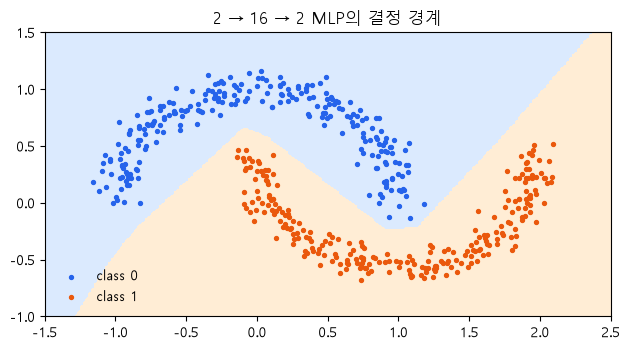

In [28]:
# 결정 경계 그림: 격자 점마다 예측 class (학습 데이터 위에)
import matplotlib.pyplot as plt                # 그래프
plt.rcParams["font.family"] = "Malgun Gothic"  # 한글 글꼴
plt.rcParams["axes.unicode_minus"] = False     # 음수 기호 깨짐 방지
plt.rcParams["font.size"] = 10                 # 본문 10pt

gx, gy = torch.linspace(-1.5, 2.5, 200), torch.linspace(-1.0, 1.5, 150)     # 가로 · 세로 눈금
xs, ys = torch.meshgrid(gx, gy, indexing="xy")                              # 격자 (150, 200)
grid_points = torch.stack([xs.reshape(-1), ys.reshape(-1)], dim=1).to(day02_device)  # (30000, 2)
with torch.no_grad():                                                       # 평가
    grid_class = pipeline_model(grid_points).argmax(dim=1).reshape(xs.shape).cpu()  # 격자마다 class
fig, ax = plt.subplots(figsize=(6.4, 3.6))                                  # 그림 한 장
ax.contourf(xs, ys, grid_class, levels=[-0.5, 0.5, 1.5], colors=["#dbeafe", "#ffedd5"])  # 경계 색
for c, color in [(0, "#2563eb"), (1, "#ea580c")]:                           # class마다 점
    pts = day02_features[day02_targets == c]                                # 그 class의 점
    ax.scatter(pts[:, 0], pts[:, 1], s=8, color=color, label=f"class {c}")  # 그리기
ax.set_title("2 → 16 → 2 MLP의 결정 경계", fontsize=12)                     # 제목
ax.legend(loc="lower left", frameon=False)                                  # 범례
fig.tight_layout()  # 여백 정리 (노트북은 셀 끝에서 그림을 자동 표시)

**결과** · 예측 정답은 500 / 500 (정확도 1.0) · `False`

- `epoch 1 / 10 / 60 loss: [0.644, 0.1124, 0.0031]` — epoch 평균 손실이 줄어듦
- `evaluation correct / total: 500 / 500` — batch마다 맞힌 수를 누적 (마지막 52 포함)
- `evaluation accuracy: 1.0` — 학습에 쓴 점을 다시 채점한 값
- `model.training after eval: False` — 다시 학습하려면 `model.train()`
- **그래프** · 두 반달 사이로 휘어진 경계 → 직선 하나(3-2)로는 못 만드는 모양

**차이 · 언제 쓰나**

<table width="100%" style="width:100%; table-layout:auto">
<thead>
<tr>
<th style="text-align: left;">방법</th>
<th style="text-align: left;">차이</th>
<th style="text-align: left;">언제 쓰나</th>
</tr>
</thead>
<tbody>
<tr>
<td style="text-align: left;">batch 정확도의 평균</td>
<td style="text-align: left;">batch 크기가 달라 틀림 (마지막 52)</td>
<td style="text-align: left;">하지 않음</td>
</tr>
<tr>
<td style="text-align: left;"><code>correct / total</code> 누적</td>
<td style="text-align: left;">분모가 정확히 500</td>
<td style="text-align: left;">평가 (기본)</td>
</tr>
<tr>
<td style="text-align: left;">학습 데이터로 평가 (이 실습)</td>
<td style="text-align: left;">학습이 잘 됐는지만</td>
<td style="text-align: left;">연습</td>
</tr>
<tr>
<td style="text-align: left;">따로 둔 검증 데이터로 평가</td>
<td style="text-align: left;">보지 않은 데이터 성능</td>
<td style="text-align: left;">실제 프로젝트</td>
</tr>
</tbody>
</table>

> ⚠️ **주의**
>
> - 이 정확도 1.0은 학습에 쓴 500개를 다시 채점한 값 → 일반화 성능이 아님 (검증 분할은 머신러닝 정리본)

> ✅ **한 줄 정리**
>
> - Dataset · DataLoader · device · model · loss · backward
> - step으로 학습하고, eval · no_grad · argmax
> - correct/total로 평가한다.

**딥러닝 코드에서는**

- CNN · RNN도 이 pipeline 그대로 · 바뀌는 것은 model 안의 층 (원본 마지막 '다음 질문' 두 개)

---
## 그래서 오늘 무엇을 배웠는가?

<table width="100%" style="width:100%; table-layout:auto">
<thead>
<tr>
<th style="text-align: left;">학습 목표</th>
<th style="text-align: left;">할 수 있게 된 것</th>
<th style="text-align: left;">확인 위치</th>
</tr>
</thead>
<tbody>
<tr>
<td style="text-align: left;">1. Module · Linear</td>
<td style="text-align: left;">note 텐서는 등록 안 됨 · <code>Linear(3, 5).weight</code> <code>(5, 3)</code> · 셀 23 오류 수정</td>
<td style="text-align: left;">2장</td>
</tr>
<tr>
<td style="text-align: left;">2. XOR · MLP</td>
<td style="text-align: left;">한 Linear MSE 0.25 · 두 층 = 한 층 · ReLU MLP <code>[0, 1, 1, 0]</code></td>
<td style="text-align: left;">3장</td>
</tr>
<tr>
<td style="text-align: left;">3. 분류 계약</td>
<td style="text-align: left;">CE 0.343237 · Softmax 먼저면 1.014123 (다름) · parameter 82</td>
<td style="text-align: left;">4장</td>
</tr>
<tr>
<td style="text-align: left;">4. optimizer loop</td>
<td style="text-align: left;">step 뒤 grad 8 그대로 · lr 1.1 발산 · lr .10에서 SGD가 Adam보다 빠름</td>
<td style="text-align: left;">5장</td>
</tr>
<tr>
<td style="text-align: left;">5. pipeline · 평가</td>
<td style="text-align: left;">8 batch · 마지막 52 · eval만으론 기록 안 꺼짐 · 500 / 500</td>
<td style="text-align: left;">6 · 7 · 8장</td>
</tr>
</tbody>
</table>

### 주제별 한 줄 · 반드시 기억할 것

<table width="100%" style="width:100%; table-layout:auto">
<thead>
<tr>
<th style="text-align: left;">등급</th>
<th style="text-align: left;">주제</th>
<th style="text-align: left;">반드시 기억할 것</th>
<th style="text-align: left;">딥러닝 코드에서</th>
</tr>
</thead>
<tbody>
<tr>
<td style="text-align: left;"><code>A</code></td>
<td style="text-align: left;">nn.Module</td>
<td style="text-align: left;">Parameter 등록 + forward · 자동 학습 아님</td>
<td style="text-align: left;"><code>class Net(nn.Module)</code></td>
</tr>
<tr>
<td style="text-align: left;"><code>A</code></td>
<td style="text-align: left;">nn.Linear</td>
<td style="text-align: left;">weight <code>[out, in]</code> · <code>x @ W.T + b</code></td>
<td style="text-align: left;"><code>nn.Linear(in, out)</code></td>
</tr>
<tr>
<td style="text-align: left;"><code>A</code></td>
<td style="text-align: left;">XOR · MLP</td>
<td style="text-align: left;">Linear만 쌓으면 한 층 · ReLU 필요</td>
<td style="text-align: left;"><code>Linear → ReLU → Linear</code></td>
</tr>
<tr>
<td style="text-align: left;"><code>A</code></td>
<td style="text-align: left;">분류 계약</td>
<td style="text-align: left;">raw logits + 정수 정답 · Softmax는 뒤에</td>
<td style="text-align: left;"><code>nn.CrossEntropyLoss()</code></td>
</tr>
<tr>
<td style="text-align: left;"><code>A</code></td>
<td style="text-align: left;">optimizer</td>
<td style="text-align: left;">zero_grad → forward → loss → backward → step</td>
<td style="text-align: left;"><code>torch.optim.Adam</code></td>
</tr>
<tr>
<td style="text-align: left;"><code>A</code></td>
<td style="text-align: left;">DataLoader</td>
<td style="text-align: left;">짝 · 묶음 · 현재 batch target</td>
<td style="text-align: left;"><code>DataLoader(ds, 64, shuffle=True)</code></td>
</tr>
<tr>
<td style="text-align: left;"><code>A</code></td>
<td style="text-align: left;">device</td>
<td style="text-align: left;">model · input · target 같은 곳</td>
<td style="text-align: left;"><code>.to(device)</code></td>
</tr>
<tr>
<td style="text-align: left;"><code>A</code></td>
<td style="text-align: left;">평가</td>
<td style="text-align: left;">eval + no_grad · correct/total</td>
<td style="text-align: left;"><code>model.eval()</code></td>
</tr>
<tr>
<td style="text-align: left;"><code>B</code></td>
<td style="text-align: left;">진단</td>
<td style="text-align: left;">계약 → 관찰 → 불일치 → 최소 수정</td>
<td style="text-align: left;">에러 메시지 읽기</td>
</tr>
<tr>
<td style="text-align: left;"><code>B</code></td>
<td style="text-align: left;">SGD vs Adam</td>
<td style="text-align: left;">조건을 고정해 비교 · 보편적 승자 없음</td>
<td style="text-align: left;"><code>state_dict</code> 복사</td>
</tr>
</tbody>
</table>

---
## 기억 확인 문제

위 내용을 **보지 않고** 답한 뒤, ✅ 한 줄 정리와 비교해 ○ (정확) · △ (일부) · × (모름)를 표시. △ · ×인 섹션만 다시 보기.

### 1. 질문에 답하기

<table width="100%" style="width:100%; table-layout:auto">
<thead>
<tr>
<th style="text-align: left;">섹션</th>
<th style="text-align: left;">🎯 질문</th>
</tr>
</thead>
<tbody>
<tr>
<td style="text-align: left;">1-4</td>
<td style="text-align: left;">업데이트(<code>-=</code>)는 gradient를 지우는가?</td>
</tr>
<tr>
<td style="text-align: left;">2-1</td>
<td style="text-align: left;"><code>nn.Parameter</code>로 등록하면 자동으로 학습되는가?</td>
</tr>
<tr>
<td style="text-align: left;">2-2</td>
<td style="text-align: left;"><code>nn.Linear(3, 5).weight</code>의 shape와 계산식은?</td>
</tr>
<tr>
<td style="text-align: left;">2-3</td>
<td style="text-align: left;">원본 셀 23의 오류 원인은?</td>
</tr>
<tr>
<td style="text-align: left;">3-2</td>
<td style="text-align: left;">XOR을 직선 하나로 못 가르는 이유는?</td>
</tr>
<tr>
<td style="text-align: left;">3-3</td>
<td style="text-align: left;">Linear 두 층은 왜 한 층과 같은가?</td>
</tr>
<tr>
<td style="text-align: left;">4-1</td>
<td style="text-align: left;">CrossEntropyLoss의 입력 · 정답 모양은?</td>
</tr>
<tr>
<td style="text-align: left;">4-2</td>
<td style="text-align: left;">Softmax를 CE 앞에 넣으면?</td>
</tr>
<tr>
<td style="text-align: left;">4-3</td>
<td style="text-align: left;"><code>2 → 16 → 2</code>의 parameter 수는?</td>
</tr>
<tr>
<td style="text-align: left;">5-1</td>
<td style="text-align: left;"><code>step()</code> 뒤 gradient는?</td>
</tr>
<tr>
<td style="text-align: left;">5-4</td>
<td style="text-align: left;">Adam은 항상 SGD보다 나은가?</td>
</tr>
<tr>
<td style="text-align: left;">6-1</td>
<td style="text-align: left;">500개를 64씩 나누면?</td>
</tr>
<tr>
<td style="text-align: left;">7-1</td>
<td style="text-align: left;"><code>eval()</code>과 <code>no_grad()</code>의 차이는?</td>
</tr>
<tr>
<td style="text-align: left;">7-3</td>
<td style="text-align: left;">float64 입력 오류의 최소 수정은?</td>
</tr>
</tbody>
</table>

#### 내 답 · 이 셀을 더블클릭해서 작성

**1-4** · (여기에 답 작성) · ○ △ × 중 하나만 남기기

**2-1** · (여기에 답 작성) · ○ △ × 중 하나만 남기기

**2-2** · (여기에 답 작성) · ○ △ × 중 하나만 남기기

**2-3** · (여기에 답 작성) · ○ △ × 중 하나만 남기기

**3-2** · (여기에 답 작성) · ○ △ × 중 하나만 남기기

**3-3** · (여기에 답 작성) · ○ △ × 중 하나만 남기기

**4-1** · (여기에 답 작성) · ○ △ × 중 하나만 남기기

**4-2** · (여기에 답 작성) · ○ △ × 중 하나만 남기기

**4-3** · (여기에 답 작성) · ○ △ × 중 하나만 남기기

**5-1** · (여기에 답 작성) · ○ △ × 중 하나만 남기기

**5-4** · (여기에 답 작성) · ○ △ × 중 하나만 남기기

**6-1** · (여기에 답 작성) · ○ △ × 중 하나만 남기기

**7-1** · (여기에 답 작성) · ○ △ × 중 하나만 남기기

**7-3** · (여기에 답 작성) · ○ △ × 중 하나만 남기기

### 2. 코드로 답하기

아래 빈 셀에 직접 작성 후 실행.

1. `nn.Linear(4, 3)`의 parameter 수를 `numel()`로 세어 출력
2. logits `[[1.0, 2.0], [3.0, 0.5]]` · 정답 `[1, 0]`의 CrossEntropyLoss와 예측 class 출력
3. `TensorDataset`으로 10개를 만들어 batch 4로 나눈 batch 크기 목록 출력

In [29]:
# 코드 문제 직접 작성

### 3. 변형 문제 · 조건을 바꿔 다시 풀기

1. 4-3의 hidden을 32로 바꾸면(`2 → 32 → 2`) parameter 수는?
2. 6-1에서 `drop_last=True`로 바꾸면 batch 수와 합계는?
3. 3-4 XOR MLP에서 `torch.relu`를 빼고 같은 조건으로 학습하면 final MSE는?

In [30]:
# 변형 문제 직접 작성

### 4. 모범 답안 · 1 ~ 3을 다 푼 뒤에 보기

#### 질문 답

<table width="100%" style="width:100%; table-layout:auto">
<thead>
<tr>
<th style="text-align: left;">섹션</th>
<th style="text-align: left;">답</th>
</tr>
</thead>
<tbody>
<tr>
<td style="text-align: left;">1-4</td>
<td style="text-align: left;">아님 · reset은 따로</td>
</tr>
<tr>
<td style="text-align: left;">2-1</td>
<td style="text-align: left;">아님 · 목록에 오를 뿐 · update는 따로</td>
</tr>
<tr>
<td style="text-align: left;">2-2</td>
<td style="text-align: left;"><code>(5, 3)</code> · <code>x @ W.T + b</code></td>
</tr>
<tr>
<td style="text-align: left;">2-3</td>
<td style="text-align: left;">학습 뒤 모델을 다시 만들어 grad가 None</td>
</tr>
<tr>
<td style="text-align: left;">3-2</td>
<td style="text-align: left;">1 두 점 · 0 두 점이 대각선으로 엇갈림</td>
</tr>
<tr>
<td style="text-align: left;">3-3</td>
<td style="text-align: left;">곱한 weight · bias로 하나로 합쳐짐</td>
</tr>
<tr>
<td style="text-align: left;">4-1</td>
<td style="text-align: left;">logits <code>[N, C]</code> · 정수 <code>[N]</code></td>
</tr>
<tr>
<td style="text-align: left;">4-2</td>
<td style="text-align: left;">실행은 되지만 loss · gradient가 다른 학습</td>
</tr>
<tr>
<td style="text-align: left;">4-3</td>
<td style="text-align: left;">48 + 34 = 82</td>
</tr>
<tr>
<td style="text-align: left;">5-1</td>
<td style="text-align: left;">그대로 · <code>zero_grad</code>가 정리</td>
</tr>
<tr>
<td style="text-align: left;">5-4</td>
<td style="text-align: left;">아님 · 같은 조건에서 비교</td>
</tr>
<tr>
<td style="text-align: left;">6-1</td>
<td style="text-align: left;">8 batch · 마지막 52</td>
</tr>
<tr>
<td style="text-align: left;">7-1</td>
<td style="text-align: left;">행동 모드 vs 기록 · 둘 다 켬</td>
</tr>
<tr>
<td style="text-align: left;">7-3</td>
<td style="text-align: left;">입력을 weight dtype(float32)으로</td>
</tr>
</tbody>
</table>

#### 코드 문제 답

```python
print(sum(p.numel() for p in nn.Linear(4, 3).parameters()))  # 15

logits = torch.tensor([[1.0, 2.0], [3.0, 0.5]])
labels = torch.tensor([1, 0])
print(round(nn.CrossEntropyLoss()(logits, labels).item(), 4))  # 0.1961
print(logits.argmax(dim=1).tolist())  # [1, 0]

ds = TensorDataset(torch.arange(10.0).reshape(10, 1), torch.zeros(10, dtype=torch.int64))
print([len(x) for x, _ in DataLoader(ds, batch_size=4)])  # [4, 4, 2]
```

#### 변형 문제 답

<table width="100%" style="width:100%; table-layout:auto">
<thead>
<tr>
<th style="text-align: left;">문제</th>
<th style="text-align: left;">답</th>
</tr>
</thead>
<tbody>
<tr>
<td style="text-align: left;">1</td>
<td style="text-align: left;">2 × 32 + 32 + 32 × 2 + 2 = 162</td>
</tr>
<tr>
<td style="text-align: left;">2</td>
<td style="text-align: left;">7개 · 448 (마지막 52를 버림)</td>
</tr>
<tr>
<td style="text-align: left;">3</td>
<td style="text-align: left;">0.25 — Linear 두 층 = 한 층이라 3-2의 한 Linear와 같은 한계</td>
</tr>
</tbody>
</table>

---
## 오답 노트

틀린 문제는 정답을 베끼지 말고 **원인**을 적음. 다음 복습 때 이 표의 "재발 방지 질문"부터 스스로에게 물어보기.

<table width="100%" style="width:100%; table-layout:auto">
<thead>
<tr>
<th style="text-align: left;">틀린 내용</th>
<th style="text-align: left;">틀린 이유</th>
<th style="text-align: left;">올바른 원칙</th>
<th style="text-align: left;">재발 방지 질문</th>
</tr>
</thead>
<tbody>
<tr>
<td style="text-align: left;">(예) 평가 때 <code>model.eval()</code>만 하고 끝냄</td>
<td style="text-align: left;">모드와 기록을 같은 스위치로 착각</td>
<td style="text-align: left;"><code>eval()</code> + <code>no_grad()</code> 둘 다</td>
<td style="text-align: left;">기록도 꺼졌나? (<code>requires_grad</code> 확인)</td>
</tr>
<tr>
<td style="text-align: left;"></td>
<td style="text-align: left;"></td>
<td style="text-align: left;"></td>
<td style="text-align: left;"></td>
</tr>
<tr>
<td style="text-align: left;"></td>
<td style="text-align: left;"></td>
<td style="text-align: left;"></td>
<td style="text-align: left;"></td>
</tr>
</tbody>
</table>

---
## 면접 30초 답변

**Q1. nn.Module과 nn.Parameter의 역할은?**
> - nn.Module은 모델의 parameter와 forward 계산을 함께 담는 그릇입니다.
> - 속성에 둔 nn.Parameter와 nn.Linear의 parameter가 자동으로 등록되어 parameters()로 모입니다.
> - 등록됐다고 자동으로 학습되지는 않고, 업데이트는 optimizer.step()이 합니다.

**Q2. XOR 문제와 활성화 함수가 필요한 이유는?**
> - XOR은 두 class가 대각선으로 엇갈려 직선 하나로 나눌 수 없습니다.
> - Linear만 여러 층 쌓으면 하나의 Linear로 합쳐지므로 표현력이 늘지 않고, 층 사이에 ReLU 같은 비선형 활성화를 넣어야 꺾인 경계를 만들어 XOR을 풀 수 있습니다.

**Q3. CrossEntropyLoss에 Softmax 결과를 넣으면 안 되는 이유는?**
> - CrossEntropyLoss는 내부에서 log_softmax를 계산한 뒤 정답 class 값을 읽으므로 raw logits를 받아야 합니다.
> - Softmax를 먼저 적용하면 실행은 되지만 Softmax가 두 번 적용된 셈이라 loss와 gradient가 달라집니다.
> - 확률은 학습 뒤 해석할 때만 softmax로 구합니다.

**Q4. 학습 loop의 순서와 평가 때 할 일은?**
> - 매 batch마다 zero_grad로 이전 기울기를 지우고 forward로 logits를 만듭니다.
> - loss를 계산해 backward로 기울기를 구한 뒤 step으로 parameter를 갱신합니다.
> - 평가에서는 model.eval()로 Dropout 같은 학습 행동을 끄고 torch.no_grad()로 기록을 끕니다.
> - 그다음 맞힌 개수와 전체 개수를 누적해 정확도를 계산합니다.

---
## 최종 요약표

<table width="100%" style="width:100%; table-layout:auto">
<thead>
<tr>
<th style="text-align: left;">함수·문법</th>
<th style="text-align: left;">소속</th>
<th style="text-align: left;">역할</th>
<th style="text-align: left;">코드에서 사용한 위치</th>
</tr>
</thead>
<tbody>
<tr>
<td style="text-align: left;"><code>.long()</code> · <code>.float()</code> · <code>torch.sigmoid()</code></td>
<td style="text-align: left;">텐서 메서드 · torch</td>
<td style="text-align: left;">dtype 변환 · 0 ~ 1</td>
<td style="text-align: left;">1-2 <code>retrieval_decimal.long()</code></td>
</tr>
<tr>
<td style="text-align: left;"><code>nn.MSELoss()</code></td>
<td style="text-align: left;">torch.nn</td>
<td style="text-align: left;">MSE</td>
<td style="text-align: left;">1-2 <code>nn.MSELoss()(retrieval_prediction, retrieval_target)</code></td>
</tr>
<tr>
<td style="text-align: left;"><code>nn.Module</code> · <code>super().__init__()</code></td>
<td style="text-align: left;">torch.nn · Python</td>
<td style="text-align: left;">모델 그릇 · 등록 장부</td>
<td style="text-align: left;">2-1 <code>class ManagedAffine(nn.Module)</code></td>
</tr>
<tr>
<td style="text-align: left;"><code>nn.Parameter</code></td>
<td style="text-align: left;">torch.nn</td>
<td style="text-align: left;">학습 대상 등록</td>
<td style="text-align: left;">2-1 <code>nn.Parameter(torch.tensor([start_w]))</code></td>
</tr>
<tr>
<td style="text-align: left;"><code>named_parameters()</code> · <code>parameters()</code></td>
<td style="text-align: left;">Module 메서드</td>
<td style="text-align: left;">parameter 목록</td>
<td style="text-align: left;">2-3 <code>one_linear_model.parameters()</code></td>
</tr>
<tr>
<td style="text-align: left;"><code>nn.Linear</code></td>
<td style="text-align: left;">torch.nn</td>
<td style="text-align: left;"><code>x @ W.T + b</code></td>
<td style="text-align: left;">2-2 <code>nn.Linear(2, 2)</code></td>
</tr>
<tr>
<td style="text-align: left;"><code>torch.relu()</code> · <code>nn.ReLU()</code></td>
<td style="text-align: left;">torch · torch.nn</td>
<td style="text-align: left;">음수 → 0</td>
<td style="text-align: left;">3-4 <code>torch.relu(self.hidden(value))</code></td>
</tr>
<tr>
<td style="text-align: left;"><code>nn.CrossEntropyLoss()</code></td>
<td style="text-align: left;">torch.nn</td>
<td style="text-align: left;">logits + 정수 정답 → loss</td>
<td style="text-align: left;">4-1 <code>nn.CrossEntropyLoss()(example_logits, example_targets)</code></td>
</tr>
<tr>
<td style="text-align: left;"><code>torch.softmax()</code> · <code>log_softmax()</code></td>
<td style="text-align: left;">torch</td>
<td style="text-align: left;">확률 · CE 내부 계산</td>
<td style="text-align: left;">4-2 <code>torch.softmax(raw_for_softmax, dim=1)</code></td>
</tr>
<tr>
<td style="text-align: left;"><code>argmax(dim=1)</code></td>
<td style="text-align: left;">텐서 메서드</td>
<td style="text-align: left;">예측 class</td>
<td style="text-align: left;">4-1 <code>example_logits.argmax(dim=1)</code></td>
</tr>
<tr>
<td style="text-align: left;"><code>nn.Sequential</code></td>
<td style="text-align: left;">torch.nn</td>
<td style="text-align: left;">층을 순서대로</td>
<td style="text-align: left;">4-3 <code>nn.Sequential(nn.Linear(2, 16), nn.ReLU(), ...)</code></td>
</tr>
<tr>
<td style="text-align: left;"><code>torch.optim.SGD</code> · <code>Adam</code></td>
<td style="text-align: left;">torch.optim</td>
<td style="text-align: left;">update 담당</td>
<td style="text-align: left;">5-2 <code>torch.optim.Adam(loop_model.parameters(), lr=0.03)</code></td>
</tr>
<tr>
<td style="text-align: left;"><code>zero_grad()</code> · <code>step()</code></td>
<td style="text-align: left;">optimizer 메서드</td>
<td style="text-align: left;">정리 · 갱신</td>
<td style="text-align: left;">5-1 <code>grad_optimizer.step()</code></td>
</tr>
<tr>
<td style="text-align: left;"><code>state_dict()</code> · <code>load_state_dict()</code></td>
<td style="text-align: left;">Module 메서드</td>
<td style="text-align: left;">같은 출발점 저장 · 복원</td>
<td style="text-align: left;">5-4 <code>model.load_state_dict(curve_base_state)</code></td>
</tr>
<tr>
<td style="text-align: left;"><code>TensorDataset</code> · <code>DataLoader</code></td>
<td style="text-align: left;">torch.utils.data</td>
<td style="text-align: left;">짝 · 묶음 공급</td>
<td style="text-align: left;">6-1 <code>DataLoader(day02_dataset, batch_size=64, ...)</code></td>
</tr>
<tr>
<td style="text-align: left;"><code>.to(device)</code></td>
<td style="text-align: left;">텐서 · Module 메서드</td>
<td style="text-align: left;">계산 장소</td>
<td style="text-align: left;">6-2 <code>ClassificationMLP().to(day02_device)</code></td>
</tr>
<tr>
<td style="text-align: left;"><code>model.train()</code> · <code>model.eval()</code></td>
<td style="text-align: left;">Module 메서드</td>
<td style="text-align: left;">행동 모드</td>
<td style="text-align: left;">7-1 <code>mode_probe.eval()</code></td>
</tr>
<tr>
<td style="text-align: left;"><code>nn.Dropout</code></td>
<td style="text-align: left;">torch.nn</td>
<td style="text-align: left;">학습 중 일부 가리기</td>
<td style="text-align: left;">7-1 <code>nn.Dropout(p=0.5)</code></td>
</tr>
<tr>
<td style="text-align: left;"><code>warnings.catch_warnings()</code></td>
<td style="text-align: left;">warnings</td>
<td style="text-align: left;">경고 잡기</td>
<td style="text-align: left;">7-2 <code>warnings.catch_warnings(record=True)</code></td>
</tr>
</tbody>
</table>

### 할 것 · 하지 말 것

<table width="100%" style="width:100%; table-layout:auto">
<thead>
<tr>
<th style="text-align: left;">✅ 할 것</th>
<th style="text-align: left;">⚠️ 하지 말 것</th>
</tr>
</thead>
<tbody>
<tr>
<td style="text-align: left;">loss 직전 shape · dtype · device 확인</td>
<td style="text-align: left;">scalar loss면 맞다고 가정</td>
</tr>
<tr>
<td style="text-align: left;">분류는 raw logits + 정수 정답</td>
<td style="text-align: left;">Softmax 후 CrossEntropyLoss</td>
</tr>
<tr>
<td style="text-align: left;">매 batch <code>zero_grad</code> → … → <code>step</code></td>
<td style="text-align: left;"><code>step()</code>이 grad를 지운다고 가정</td>
</tr>
<tr>
<td style="text-align: left;">평가는 <code>eval()</code> + <code>no_grad()</code></td>
<td style="text-align: left;"><code>eval()</code>만</td>
</tr>
<tr>
<td style="text-align: left;">model · input · target 같은 device</td>
<td style="text-align: left;">model만 GPU로</td>
</tr>
<tr>
<td style="text-align: left;">정확도는 correct / total 누적</td>
<td style="text-align: left;">batch 정확도를 단순 평균</td>
</tr>
</tbody>
</table>

### 헷갈리는 짝 한눈에 보기

<table width="100%" style="width:100%; table-layout:auto">
<thead>
<tr>
<th style="text-align: left;">짝</th>
<th style="text-align: left;">차이</th>
<th style="text-align: left;">결론</th>
</tr>
</thead>
<tbody>
<tr>
<td style="text-align: left;"><code>nn.Parameter</code> vs 일반 텐서</td>
<td style="text-align: left;">등록됨 vs 안 됨</td>
<td style="text-align: left;">학습할 값은 Parameter</td>
</tr>
<tr>
<td style="text-align: left;"><code>nn.Sequential</code> vs Module 상속</td>
<td style="text-align: left;">나열 vs forward 직접</td>
<td style="text-align: left;">단순 흐름은 Sequential</td>
</tr>
<tr>
<td style="text-align: left;">Linear 두 층 vs 사이에 ReLU</td>
<td style="text-align: left;">한 층과 같음 vs 꺾인 경계</td>
<td style="text-align: left;">ReLU 필요</td>
</tr>
<tr>
<td style="text-align: left;">logits vs 확률</td>
<td style="text-align: left;">원점수 vs softmax 결과</td>
<td style="text-align: left;">loss에는 logits</td>
</tr>
<tr>
<td style="text-align: left;"><code>CrossEntropyLoss</code> vs <code>MSELoss</code></td>
<td style="text-align: left;">logits + 번호 vs 실수 + 실수</td>
<td style="text-align: left;">분류 vs 회귀</td>
</tr>
<tr>
<td style="text-align: left;">SGD vs Adam</td>
<td style="text-align: left;">lr × grad vs 이동 평균으로 보폭</td>
<td style="text-align: left;">조건 고정 비교</td>
</tr>
<tr>
<td style="text-align: left;"><code>step</code> vs <code>zero_grad</code></td>
<td style="text-align: left;">값 갱신 vs grad 정리</td>
<td style="text-align: left;">둘 다 매 batch</td>
</tr>
<tr>
<td style="text-align: left;"><code>eval()</code> vs <code>no_grad()</code></td>
<td style="text-align: left;">행동 모드 vs 기록</td>
<td style="text-align: left;">평가엔 둘 다</td>
</tr>
</tbody>
</table>

---
## 다음 복습일

<table width="100%" style="width:100%; table-layout:auto">
<thead>
<tr>
<th style="text-align: left;">언제</th>
<th style="text-align: left;">할 일</th>
<th style="text-align: left;">걸리는 시간</th>
</tr>
</thead>
<tbody>
<tr>
<td style="text-align: left;">내일</td>
<td style="text-align: left;">기억 확인 문제 1을 자료 없이 다시 답하고 오답 노트 갱신</td>
<td style="text-align: left;">15분</td>
</tr>
<tr>
<td style="text-align: left;">3일 뒤</td>
<td style="text-align: left;">변형 문제 3개 · 3장 그림을 가리고 XOR이 왜 안 되는지 말하기</td>
<td style="text-align: left;">20분</td>
</tr>
<tr>
<td style="text-align: left;">7일 뒤</td>
<td style="text-align: left;">8장 pipeline을 빈 셀에 직접 다시 짜고 batch 수 · 정확도를 먼저 예측</td>
<td style="text-align: left;">30분</td>
</tr>
<tr>
<td style="text-align: left;">14일 뒤</td>
<td style="text-align: left;">오답 노트에 남은 문제만 · CNN 시작 전 2 · 4 · 5장 ✅ 줄만 읽기</td>
<td style="text-align: left;">15분</td>
</tr>
</tbody>
</table>

---
## 부록

### 이 노트북을 만든 방법

- 원본 · `02_pytorch.ipynb` 97셀을 원본 순서 그대로 7장 24섹션으로
- Practice PC-01 ~ PC-11 안내 셀은 대응표에 적음 (문제는 별도 파일)
- 원본 셀 23의 실제 오류(`AttributeError`)와 셀 10의 실행 안 되는 주석은 고치고 그 이유를 섹션 주의에 적음
- 원본 셀 80 ~ 82 '전체 pipeline'은 8장 종합 실습으로 · 결정 경계 그림을 더함
- 원본 그림(assets/day02/*.svg)은 원본 폴더에 없어 같은 뜻의 그림을 새로 그림 · 형식 v2.1

### 읽는 법

<table width="100%" style="width:100%; table-layout:auto">
<thead>
<tr>
<th style="text-align: left;">표시</th>
<th style="text-align: left;">의미</th>
</tr>
</thead>
<tbody>
<tr>
<td style="text-align: left;"><code>A</code> · <code>B</code></td>
<td style="text-align: left;"><strong>A</strong> 딥러닝 코드에 바로 나오는 필수 · <strong>B</strong> 알아두면 되는 것</td>
</tr>
<tr>
<td style="text-align: left;">🎯</td>
<td style="text-align: left;">이번 섹션에서 답해야 할 질문</td>
</tr>
<tr>
<td style="text-align: left;">💡</td>
<td style="text-align: left;">쉬운 설명 · 비유</td>
</tr>
<tr>
<td style="text-align: left;">⚠️</td>
<td style="text-align: left;">자주 하는 실수</td>
</tr>
<tr>
<td style="text-align: left;">✅</td>
<td style="text-align: left;">기억할 결론 = 🎯 질문의 답</td>
</tr>
</tbody>
</table>

- **섹션 앞부분** · 🎯 질문 → 💡 쉬운 설명 → 실행 흐름 → 먼저 예측 → 코드
- **섹션 뒷부분** · 결과(예측 정답 · 출력 줄) → 차이 · 언제 쓰나 → ⚠️ 주의 → ✅ 한 줄 정리
- **코드 주석** · 코드 위는 이 단계에서 하는 일, 코드 옆은 그 줄이 필요한 이유 (줄마다 · 열 맞춤)

### 원본 → 섹션 대응표

<table width="100%" style="width:100%; table-layout:auto">
<thead>
<tr>
<th style="text-align: left;">원본</th>
<th style="text-align: left;">내용</th>
<th style="text-align: left;">이 노트북</th>
</tr>
</thead>
<tbody>
<tr>
<td style="text-align: left;">셀 0 ~ 5</td>
<td style="text-align: left;">오늘 확인할 것 · 핵심 연산 회수</td>
<td style="text-align: left;">1-1</td>
</tr>
<tr>
<td style="text-align: left;">셀 6 ~ 8</td>
<td style="text-align: left;">짧은 API 확인 (long · sigmoid · MSELoss)</td>
<td style="text-align: left;">1-2</td>
</tr>
<tr>
<td style="text-align: left;">셀 9 ~ 15</td>
<td style="text-align: left;">역할 찾기 · <code>b</code> 붙이기 · 관리 비용 · PC-01</td>
<td style="text-align: left;">1-3 · 1-4</td>
</tr>
<tr>
<td style="text-align: left;">셀 16 ~ 26</td>
<td style="text-align: left;">Module · Parameter · Linear · Linear in model(셀 23 오류) · 빈 셀 24 · PC-02</td>
<td style="text-align: left;">2-1 ~ 2-3</td>
</tr>
<tr>
<td style="text-align: left;">셀 27 ~ 35</td>
<td style="text-align: left;">Linear 경계 · AND · OR · XOR 후보 · 학습 · 한계 · PC-03</td>
<td style="text-align: left;">3-1 · 3-2</td>
</tr>
<tr>
<td style="text-align: left;">셀 36 ~ 46</td>
<td style="text-align: left;">층 쌓기 · 두 층 = 한 층 · ReLU · XOR MLP · PC-04 · 앞부분 연결</td>
<td style="text-align: left;">3-3 · 3-4</td>
</tr>
<tr>
<td style="text-align: left;">셀 47 ~ 57</td>
<td style="text-align: left;">logits · CE · Softmax 함정 · 82 parameter · Sequential · PC-05</td>
<td style="text-align: left;">4-1 ~ 4-3</td>
</tr>
<tr>
<td style="text-align: left;">셀 58 ~ 69</td>
<td style="text-align: left;">step과 gradient · 책임 순서 · two moons · 학습률 · SGD vs Adam · PC-06 · 07</td>
<td style="text-align: left;">5-1 ~ 5-4</td>
</tr>
<tr>
<td style="text-align: left;">셀 70 ~ 76</td>
<td style="text-align: left;">TensorDataset · DataLoader · device · PC-08</td>
<td style="text-align: left;">6-1 · 6-2</td>
</tr>
<tr>
<td style="text-align: left;">셀 77 ~ 79</td>
<td style="text-align: left;">train · eval · no_grad</td>
<td style="text-align: left;">7-1</td>
</tr>
<tr>
<td style="text-align: left;">셀 80 ~ 82</td>
<td style="text-align: left;">전체 pipeline</td>
<td style="text-align: left;">8</td>
</tr>
<tr>
<td style="text-align: left;">셀 83 ~ 91</td>
<td style="text-align: left;">shape guard · PC-09 · 진단 · dtype 오류 · 낯선 함수</td>
<td style="text-align: left;">7-2 ~ 7-4</td>
</tr>
<tr>
<td style="text-align: left;">셀 92 ~ 96</td>
<td style="text-align: left;">다음 질문(CNN · RNN) · 마지막 회수 · PC-10 · 11 · 마무리</td>
<td style="text-align: left;">8장 딥러닝 코드에서는 · 그래서 오늘 무엇을 배웠는가?</td>
</tr>
</tbody>
</table>

### 전체 코드

1 ~ 8장 코드를 장별 셀로 모음. **위에서부터 이 셀들만 실행해도 전체가 동작**하며, 각 블록 머리 주석의 번호가 섹션.

In [31]:
# ---------- 1-1 ----------
# 원본 셀 4: 질문에 맞는 연산을 고르고 결과 shape를 먼저 예측
retrieval_grid = torch.arange(15, dtype=torch.float32).reshape(3, 5)         # 만들기 · 모양
retrieval_row = retrieval_grid[1]                                            # 행 하나
retrieval_slice = retrieval_grid[:2, 1:4]                                    # 구간
retrieval_with_axis = torch.arange(6, dtype=torch.float32).reshape(3, 1, 2)  # 가운데 길이 1
retrieval_squeezed = retrieval_with_axis.squeeze(1)                          # 길이 1 축 제거
retrieval_column = retrieval_squeezed.unsqueeze(-1)                          # 맨 끝에 축 추가

retrieval_left = torch.tensor([[1., 2.], [3., 4.]])                      # (2, 2)
retrieval_right = torch.tensor([[10., 20.], [30., 40.]])                 # (2, 2)
retrieval_cat = torch.cat([retrieval_left, retrieval_right], dim=0)      # 기존 축 잇기
retrieval_stack = torch.stack([retrieval_left, retrieval_right], dim=1)  # 새 축 (가운데)
retrieval_elementwise = retrieval_left * retrieval_right                 # 같은 위치 곱
retrieval_matmul = retrieval_left @ retrieval_right                      # 행렬 곱

print("create / reshape:", tuple(retrieval_grid.shape))                            # (3, 5)
print("index / slice:", tuple(retrieval_row.shape), tuple(retrieval_slice.shape))  # (5,) · (2, 3)
# (3, 2) · (3, 2, 1)
print("shape:", tuple(retrieval_squeezed.shape), tuple(retrieval_column.shape))
# (4, 2) · (2, 2, 2)
print("cat / stack:", tuple(retrieval_cat.shape), tuple(retrieval_stack.shape))
print("* / matmul:", retrieval_elementwise.tolist(), retrieval_matmul.tolist())    # 값이 다름


# ---------- 1-2 ----------
# 원본 셀 7: long · float · sigmoid · MSE
retrieval_decimal = torch.tensor([3.7, -2.4, 0.9])         # 실수
retrieval_long = retrieval_decimal.long()                  # 정수로 → 소수부 버림
retrieval_float = retrieval_long.float()                   # 다시 실수로 (버린 소수는 안 돌아옴)
shown = [round(v, 1) for v in retrieval_decimal.tolist()]  # 보기 좋게
# 세 단계
print("cast values:", shown, "->", retrieval_long.tolist(), "->", retrieval_float.tolist())

retrieval_sigmoid = torch.sigmoid(torch.tensor([-2.0, 0.0, 2.0]))     # 0 ~ 1 사이로
print("sigmoid:", [round(v, 4) for v in retrieval_sigmoid.tolist()])  # 입력 0 → 0.5

retrieval_prediction = torch.tensor([1.0, 3.0, 5.0])                            # 예측
retrieval_target = torch.tensor([2.0, 1.0, 5.0])                                # 정답
retrieval_mse_manual = ((retrieval_prediction - retrieval_target) ** 2).mean()  # 직접 계산
# 기본 reduction = mean
retrieval_mse_builtin = nn.MSELoss()(retrieval_prediction, retrieval_target)
print("MSE manual / nn.MSELoss:", round(retrieval_mse_manual.item(), 6),        # 같음
      round(retrieval_mse_builtin.item(), 6))

create / reshape: (3, 5)
index / slice: (5,) (2, 3)
shape: (3, 2) (3, 2, 1)
cat / stack: (4, 2) (2, 2, 2)
* / matmul: [[10.0, 40.0], [90.0, 160.0]] [[70.0, 100.0], [150.0, 220.0]]
cast values: [3.7, -2.4, 0.9] -> [3, -2, 0] -> [3.0, -2.0, 0.0]
sigmoid: [0.1192, 0.5, 0.8808]
MSE manual / nn.MSELoss: 1.666667 1.666667


In [32]:
# ---------- 1-3 ----------
# 원본 셀 10: 이름이 바뀐 Day1 코드에서 여섯 역할 찾기
feature = torch.tensor([2.0])                     # 1. input
answer = torch.tensor([5.0])                      # 1. target
scale = torch.tensor([1.0], requires_grad=True)   # 2. parameter (w)
offset = torch.tensor([0.0], requires_grad=True)  # 2. parameter (b)

estimate = scale * feature + offset                      # 3. prediction
distance = ((estimate - answer) ** 2).mean()             # 3. loss
distance.backward()                                      # 4. gradient 계산
before = (scale.item(), offset.item(), distance.item())  # 바꾸기 전 기록

with torch.no_grad():             # 5. parameter update
    scale -= 0.05 * scale.grad    # 1 - 0.05 × (-12)
    offset -= 0.05 * offset.grad  # 0 - 0.05 × (-6)
scale.grad.zero_()                # 6. gradient reset
offset.grad.zero_()               # 6. gradient reset

fresh_distance = ((scale * feature + offset - answer) ** 2).mean()  # 바뀐 값으로 새 손실
print("before (scale, offset, loss):", before)                      # (1.0, 0.0, 9.0)
# 줄어든 손실
print("after  (scale, offset, loss):", (round(scale.item(), 4), round(offset.item(), 4),
                                        round(fresh_distance.item(), 4)))
print("reset grads:", scale.grad.item(), offset.grad.item())        # 0 · 0


# ---------- 1-4 ----------
# 원본 셀 12: w와 b를 모두 학습 대상으로
bias_w = torch.tensor([1.0], requires_grad=True)                # 학습할 w
bias_b = torch.tensor([0.0], requires_grad=True)                # 학습할 b
bias_x, bias_target = torch.tensor([2.0]), torch.tensor([5.0])  # 입력 · 정답

bias_loss = ((bias_w * bias_x + bias_b - bias_target) ** 2).mean()  # 예측 → 손실
bias_loss.backward()                                                # 기울기 둘
print("grad 확인 × 2:", bias_w.grad.item(), bias_b.grad.item())     # 따로 확인

with torch.no_grad():                                                   # 업데이트도 둘
    bias_w -= 0.05 * bias_w.grad                                        # w 따로
    bias_b -= 0.05 * bias_b.grad                                        # b 따로
print("update × 2:", round(bias_w.item(), 4), round(bias_b.item(), 4))  # 1.6 · 0.3
# 업데이트가 grad를 지우지 않음
print("update 뒤에도 grad 유지:", bias_w.grad.item(), bias_b.grad.item())

bias_w.grad.zero_()                                          # reset도 따로
bias_b.grad.zero_()                                          # reset도 따로
print("reset × 2:", bias_w.grad.item(), bias_b.grad.item())  # 0 · 0

before (scale, offset, loss): (1.0, 0.0, 9.0)
after  (scale, offset, loss): (1.6, 0.3, 2.25)
reset grads: 0.0 0.0
grad 확인 × 2: -12.0 -6.0
update × 2: 1.6 0.3
update 뒤에도 grad 유지: -12.0 -6.0
reset × 2: 0.0 0.0


In [33]:
# ---------- 2-1 ----------
# 원본 셀 17: parameter를 등록하고 forward로 계산을 묶음
class ManagedAffine(nn.Module):                         # nn.Module을 물려받은 모델
    def __init__(self, start_w=1.6, start_b=0.3):       # 시작값
        super().__init__()                              # 부모 준비 (등록 장부 만들기)
        self.w = nn.Parameter(torch.tensor([start_w]))  # 속성에 두면 학습 대상으로 등록
        self.b = nn.Parameter(torch.tensor([start_b]))  # 등록
        self.note = torch.tensor([9.0])                 # 일반 텐서는 등록 안 됨 (비교용)

    def forward(self, value):           # 현재 input · parameter로 output 계산
        return self.w * value + self.b  # update가 아님


managed_affine = ManagedAffine()                                                # 모델 만들기
for name, parameter in managed_affine.named_parameters():                       # 등록된 것만
    # 이름 · 종류
    print(name, type(parameter).__name__, tuple(parameter.shape), round(parameter.item(), 4))
print("forward result:", round(managed_affine(torch.tensor([2.0])).item(), 4))  # 1.6 × 2 + 0.3
print("등록된 개수:", len(list(managed_affine.parameters())), "| note 등록?",   # note는 빠짐
      "note" in dict(managed_affine.named_parameters()))
print("requires_grad:", managed_affine.w.requires_grad)  # Parameter는 자동으로 True


# ---------- 2-2 ----------
# 원본 셀 21: nn.Linear = X @ weight.T + bias
orientation_x = torch.tensor([[1.0, 2.0], [3.0, 4.0]])        # [batch=2, in=2]
orientation_linear = nn.Linear(2, 2)                          # in 2 → out 2
with torch.no_grad():                                         # 값을 정해 넣기 (기록 안 함)
    orientation_linear.weight.copy_(torch.tensor([[0.5, -1.0], [1.5, 0.25]]))  # [out, in]
    orientation_linear.bias.copy_(torch.tensor([0.1, -0.2]))  # [out]

orientation_from_linear = orientation_linear(orientation_x)                         # 층으로 계산
# 직접 계산
orientation_manual = orientation_x @ orientation_linear.weight.T + orientation_linear.bias
print("stored weight shape [out,in]:", tuple(orientation_linear.weight.shape))      # (2, 2)
# 층 결과
print("nn.Linear output:", [[round(v, 4) for v in row] for row in orientation_from_linear.tolist()])
print("same output:", torch.allclose(orientation_from_linear, orientation_manual))  # 같음


# weight 모양이 [out, in]인지 다른 크기로 확인
print("Linear(3, 5).weight:", tuple(nn.Linear(3, 5).weight.shape))  # (5, 3)


# ---------- 2-3 ----------
# 원본 셀 23: Linear를 모델 안에 넣고 한 단계 학습
class OneLinearModel(nn.Module):       # Linear 하나짜리 모델
    def __init__(self):                # 층 만들기
        super().__init__()             # 부모 준비
        self.linear = nn.Linear(1, 1)  # 속성에 두면 안의 weight · bias가 등록됨

    def forward(self, value):      # 계산
        return self.linear(value)  # Linear 그대로

w Parameter (1,) 1.6
b Parameter (1,) 0.3
forward result: 3.5
등록된 개수: 2 | note 등록? False
requires_grad: True
stored weight shape [out,in]: (2, 2)
nn.Linear output: [[-1.4, 1.8], [-2.4, 5.3]]
same output: True
Linear(3, 5).weight: (5, 3)


In [34]:
one_linear_model = OneLinearModel()                                         # 모델
with torch.no_grad():                                                       # 시작값 지정
    one_linear_model.linear.weight.copy_(torch.tensor([[1.6]]))             # w = 1.6
    one_linear_model.linear.bias.copy_(torch.tensor([0.3]))                 # b = 0.3
linear_input, linear_target = torch.tensor([[2.0]]), torch.tensor([[5.0]])  # (1, 1) 두 개

linear_before = one_linear_model(linear_input)               # 예측
linear_loss = ((linear_before - linear_target) ** 2).mean()  # 손실
linear_loss.backward()                                       # 기울기
with torch.no_grad():                                        # 업데이트 · reset을 parameter 목록으로
    for parameter in one_linear_model.parameters():          # weight · bias 차례로
        parameter -= 0.05 * parameter.grad                   # 업데이트
        parameter.grad.zero_()                               # reset
linear_fresh = one_linear_model(linear_input)                # 바뀐 값으로 새 예측
linear_fresh_loss = ((linear_fresh - linear_target) ** 2).mean()  # 새 손실

names = [name for name, _ in one_linear_model.named_parameters()]  # 등록된 이름
print("registered names:", names)                                  # linear. 이 붙음
# 3.5 · 2.25
print("before prediction / loss:", round(linear_before.item(), 4), round(linear_loss.item(), 4))
# 줄어듦
print("fresh prediction / loss:", round(linear_fresh.item(), 4), round(linear_fresh_loss.item(), 4))
# 같은 모델의 grad
print("reset grads:", [parameter.grad.item() for parameter in one_linear_model.parameters()])

registered names: ['linear.weight', 'linear.bias']
before prediction / loss: 3.5 2.25
fresh prediction / loss: 4.25 0.5625
reset grads: [0.0, 0.0]


In [35]:
# ---------- 3-1 ----------
# 원본 셀 28: 두 입력 하나의 Linear 경계 (score >= 0 → 1)
logic_x = torch.tensor([[0., 0.], [0., 1.], [1., 0.], [1., 1.]])  # 예제 4 × feature 2


def fixed_boundary(weight, bias):                                 # weight · bias가 정해진 경계 하나
    scores = logic_x @ torch.tensor(weight).reshape(2, 1) + bias  # (4, 2) @ (2, 1) → score
    decisions = (scores >= 0).to(torch.int64).squeeze(1)          # 기준 적용 → 0 / 1
    return scores.squeeze(1), decisions                           # score · 결정


and_scores, and_decisions = fixed_boundary([1., 1.], -1.5)                     # AND
or_scores, or_decisions = fixed_boundary([1., 1.], -0.5)                       # OR
print("AND scores / decisions:", and_scores.tolist(), and_decisions.tolist())  # 둘 다 1일 때만
print("OR  scores / decisions:", or_scores.tolist(), or_decisions.tolist())    # 하나라도 1
print("score ≠ label:", and_scores[3].item(), "→", and_decisions[3].item())    # 숫자 0.5 → 결정 1


# ---------- 3-2 ----------
# 원본 셀 30: XOR도 weight · bias만 잘 고르면?
xor_target = torch.tensor([0, 1, 1, 0])                                    # 정확히 하나만 1일 때 1
for label, weight, bias in [("후보 A", [1., 1.], -0.5), ("후보 B", [1., 1.], -1.5),  # 세 후보
                            ("후보 C", [1., -1.], -0.5)]:
    _, decisions = fixed_boundary(weight, bias)                            # 경계 적용
    accuracy = (decisions == xor_target).float().mean().item()             # 맞힌 비율
    print(label, "decisions=", decisions.tolist(), "accuracy=", accuracy)  # 모두 한 점 이상 틀림


# 원본 셀 33: 학습해 봐도 (Linear(2, 1) · MSE · 500 step)
torch.manual_seed(7)                                                         # 원본과 같은 시작값
single_linear = nn.Linear(2, 1)                                              # 경계 하나
xor_float_target = xor_target.to(torch.float32).reshape(4, 1)                # MSE용 실수 (4, 1)
for step in range(500):                                                      # 500번
    single_loss = ((single_linear(logic_x) - xor_float_target) ** 2).mean()  # 손실
    single_loss.backward()                                                   # 기울기
    with torch.no_grad():                                                    # 업데이트 · reset
        for parameter in single_linear.parameters():                         # weight · bias
            parameter -= 0.1 * parameter.grad                                # 업데이트
            parameter.grad.zero_()                                           # reset
with torch.no_grad():                                                        # 평가는 기록 없이
    single_output = single_linear(logic_x)                                   # 마지막 출력
print("final outputs:", [round(v, 4) for v in single_output.squeeze(1).tolist()])  # 모두 0.5 근처
# 0.5 기준 결정
print("final decisions:", (single_output >= 0.5).to(torch.int64).squeeze(1).tolist())
# 0.25에서 멈춤
print("final MSE:", round(((single_output - xor_float_target) ** 2).mean().item(), 4))

AND scores / decisions: [-1.5, -0.5, -0.5, 0.5] [0, 0, 0, 1]
OR  scores / decisions: [-0.5, 0.5, 0.5, 1.5] [0, 1, 1, 1]
score ≠ label: 0.5 → 1
후보 A decisions= [0, 1, 1, 1] accuracy= 0.75
후보 B decisions= [0, 0, 0, 1] accuracy= 0.25
후보 C decisions= [0, 0, 1, 0] accuracy= 0.75
final outputs: [0.5, 0.5, 0.5, 0.5]
final decisions: [1, 1, 1, 0]
final MSE: 0.25


In [36]:
# ---------- 3-3 ----------
# 원본 셀 38: Linear 두 층을 이으면?
torch.manual_seed(11)                         # 원본과 같은 시작값
linear_1 = nn.Linear(2, 4)                    # 2 → 4
linear_2 = nn.Linear(4, 1)                    # 4 → 1
stacked_output = linear_2(linear_1(logic_x))  # 두 층 통과

combined_weight = linear_2.weight @ linear_1.weight              # (1, 4) @ (4, 2) → (1, 2)
combined_bias = linear_2.weight @ linear_1.bias + linear_2.bias  # 하나로 합친 bias
combined_output = logic_x @ combined_weight.T + combined_bias    # 한 층으로 계산
# 같은 모양
print("stacked / combined shape:", tuple(stacked_output.shape), tuple(combined_output.shape))
print("두 층 = 한 층:", torch.allclose(stacked_output, combined_output, atol=1e-6))  # 같은 값


# ---------- 3-4 ----------
# 원본 셀 40: ReLU = 음수는 0, 0과 양수는 그대로
relu_demo = torch.tensor([-2.0, -0.5, 0.0, 0.5, 2.0])  # 다섯 값
print("before ReLU:", relu_demo.tolist())              # 원래 값
print("after  ReLU:", torch.relu(relu_demo).tolist())  # 음수만 0


# 원본 셀 42: XOR MLP = Linear(2, 16) → ReLU → Linear(16, 1)
class XORMLP(nn.Module):                # hidden layer 하나
    def __init__(self):                 # 층 두 개
        super().__init__()              # 부모 준비
        self.hidden = nn.Linear(2, 16)  # 입력 2 → hidden 16
        self.output = nn.Linear(16, 1)  # hidden 16 → 출력 1

    def forward(self, value):                               # 계산 순서
        return self.output(torch.relu(self.hidden(value)))  # 두 Linear 사이에 ReLU


torch.manual_seed(42)                                                           # 원본과 같은 시작값
xor_mlp = XORMLP()                                                              # 모델
for step in range(500):                                                         # 500번 · 학습률 0.1
    xor_loss = ((xor_mlp(logic_x) - xor_float_target) ** 2).mean()              # MSE
    xor_loss.backward()                                                         # 기울기
    with torch.no_grad():                                                       # 업데이트 · reset
        for parameter in xor_mlp.parameters():                                  # 네 parameter
            parameter -= 0.1 * parameter.grad                                   # 업데이트
            parameter.grad.zero_()                                              # reset
with torch.no_grad():                                                           # 평가
    xor_output = xor_mlp(logic_x)                                               # 마지막 출력
print("final outputs:", [round(v, 4) for v in xor_output.squeeze(1).tolist()])  # 0 · 1 · 1 · 0 근처
print("final decisions:", (xor_output >= 0.5).to(torch.int64).squeeze(1).tolist())  # 네 점 모두
print("final MSE:", f"{((xor_output - xor_float_target) ** 2).mean().item():.6f}")  # 거의 0

stacked / combined shape: (4, 1) (4, 1)
두 층 = 한 층: True
before ReLU: [-2.0, -0.5, 0.0, 0.5, 2.0]
after  ReLU: [0.0, 0.0, 0.0, 0.5, 2.0]


final outputs: [0.0, 1.0, 1.0, 0.0]
final decisions: [0, 1, 1, 0]
final MSE: 0.000000


In [37]:
# ---------- 4-1 ----------
# 원본 셀 48: 샘플마다 class별 원점수 두 개 + class 번호 정답
example_logits = torch.tensor([[2.0, 0.5], [-0.2, 1.4], [0.1, 0.0]])            # [N=3, class=2]
example_targets = torch.tensor([0, 1, 0], dtype=torch.int64)                    # [N] · 정수 번호
example_loss = nn.CrossEntropyLoss()(example_logits, example_targets)           # 원점수 그대로
print("logits shape:", tuple(example_logits.shape), "| target shape / dtype:",  # [N, 2] · [N]
      tuple(example_targets.shape), example_targets.dtype)
print("CrossEntropyLoss:", round(example_loss.item(), 6))                       # 숫자 하나
print("predicted classes:", example_logits.argmax(dim=1).tolist())              # 큰 점수의 위치


# logits는 확률이 아님: 행 합이 1이 아니고 음수도 있음
# 2.5 · 1.2 · 0.1
print("logits row sums:", [round(v, 4) for v in example_logits.sum(dim=1).tolist()])


# ---------- 4-2 ----------
# 원본 셀 51: Softmax를 CE 앞에 넣으면 같은 학습일까?
# [N=3, class=3]
raw_for_compare = torch.tensor([[2.0, 0.5, -1.0], [-0.2, 1.4, 0.3], [0.0, 0.0, 0.0]],
                               requires_grad=True)
target_for_compare = torch.tensor([0, 2, 1])                                  # class 번호
direct_ce = nn.functional.cross_entropy(raw_for_compare, target_for_compare)  # 계약대로 raw logits
direct_grad = torch.autograd.grad(direct_ce, raw_for_compare)[0]              # 그 기울기

raw_for_softmax = raw_for_compare.detach().clone().requires_grad_(True)           # 같은 값의 사본
probabilities = torch.softmax(raw_for_softmax, dim=1)                             # 확률로 먼저 바꿈
softmax_then_ce = nn.functional.cross_entropy(probabilities, target_for_compare)  # 그 뒤 CE
softmax_grad = torch.autograd.grad(softmax_then_ce, raw_for_softmax)[0]           # 그 기울기

print("raw logits → CE:", round(direct_ce.item(), 6))                                 # 계약대로
print("Softmax → CE:", round(softmax_then_ce.item(), 6))                              # 실행은 됨
print("loss가 같음:", torch.allclose(direct_ce, softmax_then_ce),                     # 다름
      "| gradient가 같음:", torch.allclose(direct_grad, softmax_grad))
print("Softmax row sums:", [round(v, 4) for v in probabilities.sum(dim=1).tolist()])  # 합 1 = 확률


# CE 내부 = log_softmax 후 정답 위치 값의 음수 평균
# 직접 계산
manual_ce = -torch.log_softmax(raw_for_compare, dim=1)[range(3), target_for_compare].mean()
print("직접 계산 CE:", round(manual_ce.item(), 6))  # raw logits → CE와 같음


# ---------- 4-3 ----------
# 원본 셀 54: 2 → 16 → 2 분류 MLP와 parameter 수
class ClassificationMLP(nn.Module):     # 마지막 출력 = class 2개의 raw logits
    def __init__(self):                 # 층 두 개
        super().__init__()              # 부모 준비
        self.hidden = nn.Linear(2, 16)  # 2 → 16
        self.output = nn.Linear(16, 2)  # 16 → 2

    def forward(self, value):                               # 계산 순서
        return self.output(torch.relu(self.hidden(value)))  # raw logits (Softmax 없음)

logits shape: (3, 2) | target shape / dtype: (3,) torch.int64
CrossEntropyLoss: 0.343237
predicted classes: [0, 1, 0]
logits row sums: [2.5, 1.2, 0.1]
raw logits → CE: 0.956101
Softmax → CE: 1.014123
loss가 같음: False | gradient가 같음: False
Softmax row sums: [1.0, 1.0, 1.0]
직접 계산 CE: 0.956101


In [38]:
classification_model = ClassificationMLP()                                    # 모델
for name, parameter in classification_model.named_parameters():               # 이름 · 모양 · 개수
    print(name, tuple(parameter.shape), parameter.numel())                    # 32 · 16 · 32 · 2
total_parameters = sum(p.numel() for p in classification_model.parameters())  # 합계
assert total_parameters == 82                                                 # 원본 검증식
print("total trainable parameters:", total_parameters)                        # 82


# 원본 셀 56: 같은 구조를 nn.Sequential로
sequential_model = nn.Sequential(nn.Linear(2, 16), nn.ReLU(), nn.Linear(16, 2))  # 순서대로 묶기
print("Sequential parameters:", sum(p.numel() for p in sequential_model.parameters()))  # 같은 82

hidden.weight (16, 2) 32
hidden.bias (16,) 16
output.weight (2, 16) 32
output.bias (2,) 2
total trainable parameters: 82
Sequential parameters: 82


In [39]:
# ---------- 5-1 ----------
# 원본 셀 60: optimizer.step()은 gradient를 지울까?
grad_probe = nn.Linear(1, 1, bias=False)                           # weight 하나
with torch.no_grad():                                              # 시작값
    grad_probe.weight.fill_(1.0)                                   # w = 1
grad_optimizer = torch.optim.SGD(grad_probe.parameters(), lr=0.1)  # 등록된 parameter 목록을 맡김

grad_optimizer.zero_grad(set_to_none=True)                                # 지난 gradient 정리
grad_loss = ((grad_probe(torch.tensor([[2.0]])) - torch.tensor([[0.0]])) ** 2).mean()  # (2w - 0)²
grad_loss.backward()                                                      # gradient = 2 × 2 × 2 = 8
grad_before_step = grad_probe.weight.grad.item()                          # step 전 grad
weight_before_step = grad_probe.weight.item()                             # step 전 w
grad_optimizer.step()                                                     # w -= 0.1 × 8
# 1 → 0.2
print("weight before / after step:", weight_before_step, round(grad_probe.weight.item(), 4))
print("grad before / after step:", grad_before_step, grad_probe.weight.grad.item())  # 그대로 8
grad_optimizer.zero_grad(set_to_none=True)                                # 이제 정리
print("grad after zero_grad(set_to_none=True):", grad_probe.weight.grad)  # None


# ---------- 5-2 ----------
# 원본 셀 63: 휘어진 두 무리의 점 500개 (two moons)
def make_two_moons(n=500, noise=0.08, seed=20260903):                               # 연습용 데이터
    half = n // 2                                                                   # 무리마다 250
    angle = torch.linspace(0, torch.pi, half)                                       # 반원 각도
    first = torch.stack([torch.cos(angle), torch.sin(angle)], dim=1)                # 위쪽 반달
    second = torch.stack([1.0 - torch.cos(angle), 0.45 - torch.sin(angle)], dim=1)  # 아래쪽 반달
    features = torch.cat([first, second], dim=0)                                    # (500, 2)
    targets = torch.cat([torch.zeros(half), torch.ones(n - half)]).to(torch.int64)  # 0 · 1 정답
    generator = torch.Generator().manual_seed(seed)  # 이 데이터 전용 난수
    features = features + noise * torch.randn(features.shape, generator=generator)  # 잡음
    return features.to(torch.float32), targets                                      # 입력 · 정답


day02_features, day02_targets = make_two_moons()  # 데이터
# (500, 2) · (500,)
print("features / targets:", tuple(day02_features.shape), tuple(day02_targets.shape))


# canonical loop: zero_grad → forward → loss → backward → step (전체 500개를 80번)
torch.manual_seed(20260903)                                                # 원본과 같은 시작값
loop_model = ClassificationMLP()                                           # 4-3의 모델
loop_optimizer = torch.optim.Adam(loop_model.parameters(), lr=0.03)        # optimizer
loop_criterion = nn.CrossEntropyLoss()                                     # raw logits + 번호
loop_losses = []                                                           # 기록
for step in range(80):                                                     # 80번
    loop_optimizer.zero_grad()                                             # 1. 지난 gradient 정리
    loop_loss = loop_criterion(loop_model(day02_features), day02_targets)  # 2 · 3. 예측 · 손실
    loop_loss.backward()                                                   # 4. gradient
    loop_optimizer.step()                                                  # 5. 갱신
    if step in (0, 9, 39, 79):                                             # 네 시점만
        loop_losses.append((step + 1, round(loop_loss.item(), 4)))         # 기록
with torch.no_grad():                                                      # 평가
    loop_pred = loop_model(day02_features).argmax(dim=1)                   # 큰 점수의 class
    loop_accuracy = (loop_pred == day02_targets).float().mean().item()     # 정확도
print("loss checkpoints:", loop_losses)                                    # 줄어듦
print("training accuracy:", round(loop_accuracy, 4))                       # 학습 데이터 정확도

weight before / after step: 1.0 0.2
grad before / after step: 8.0 8.0
grad after zero_grad(set_to_none=True): None
features / targets: (500, 2) (500,)
loss checkpoints: [(1, 0.8017), (10, 0.3647), (40, 0.1887), (80, 0.0805)]
training accuracy: 0.984


In [40]:
# ---------- 5-3 ----------
# 원본 셀 65: 값 하나를 3으로 · SGD 학습률 3개 · 12번
lr_probe_summary = {}                                       # 학습률 → (마지막 값, 마지막 손실)
for probe_lr in (0.1, 0.5, 1.1):                            # 작음 · 딱 맞음 · 큼
    probe_value = nn.Parameter(torch.tensor([0.0]))         # 0에서 시작
    probe_optimizer = torch.optim.SGD([probe_value], lr=probe_lr)  # 이 값 하나를 맡김
    for _ in range(12):                                     # 12번
        probe_optimizer.zero_grad()                         # 정리
        probe_loss = ((probe_value - 3.0) ** 2).sum()       # 목표 3
        probe_loss.backward()                               # gradient
        probe_optimizer.step()                              # 갱신
    final_probe_loss = ((probe_value - 3.0) ** 2).item()    # 마지막 손실
    lr_probe_summary[probe_lr] = (round(probe_value.item(), 4), round(final_probe_loss, 4))  # 기록
print("lr → (final value, final loss):", lr_probe_summary)  # 셋 비교
print("가장 큰 lr이 더 나쁨:", lr_probe_summary[1.1][1] > lr_probe_summary[0.1][1])  # True


# ---------- 5-4 ----------
# 원본 셀 67: 같은 데이터 · 같은 시작값 · 200 step에서 SGD vs Adam
comparison_x = torch.linspace(-1, 1, 41).reshape(-1, 1)    # 입력 41개
comparison_y = 2 * comparison_x - 0.5                      # 정답 규칙
curve_base = nn.Linear(1, 1)                               # 시작 모델
with torch.no_grad():                                      # 시작값 고정
    curve_base.weight.fill_(-0.75)                         # w = -0.75
    curve_base.bias.fill_(0.75)                            # b = 0.75
curve_base_state = copy.deepcopy(curve_base.state_dict())  # 같은 출발점 저장

curve_summary = {}                                                     # 조건 → checkpoint 손실
for label, optimizer_class, learning_rate in [("SGD lr=.01", torch.optim.SGD, 0.01),  # 네 조건
                                              ("SGD lr=.10", torch.optim.SGD, 0.10),
                                              ("Adam lr=.01", torch.optim.Adam, 0.01),
                                              ("Adam lr=.10", torch.optim.Adam, 0.10)]:
    model = nn.Linear(1, 1)                                            # 새 모델
    model.load_state_dict(curve_base_state)                            # 같은 출발점
    optimizer = optimizer_class(model.parameters(), lr=learning_rate)  # 조건별 optimizer
    checkpoints = []                                                   # 기록
    for step in range(200):                                            # 200 step
        optimizer.zero_grad()                                          # 정리
        loss = ((model(comparison_x) - comparison_y) ** 2).mean()      # MSE
        loss.backward()                                                # gradient
        optimizer.step()                                               # 갱신
        if step in (0, 9, 49, 99, 199):                                # 다섯 시점
            checkpoints.append(round(loss.item(), 4))                  # 기록
    curve_summary[label] = checkpoints                                 # 저장
for label, checkpoints in curve_summary.items():                       # 조건마다
    print(label, "MSE@1/10/50/100/200=", checkpoints)                  # 경로

lr → (final value, final loss): {0.1: (2.7938, 0.0425), 0.5: (3.0, 0.0), 1.1: (-23.7483, 715.4725)}
가장 큰 lr이 더 나쁨: True


SGD lr=.01 MSE@1/10/50/100/200= [4.2094, 3.4186, 1.5455, 0.6873, 0.1621]
SGD lr=.10 MSE@1/10/50/100/200= [4.2094, 0.745, 0.0022, 0.0, 0.0]
Adam lr=.01 MSE@1/10/50/100/200= [4.2094, 3.8227, 2.4242, 1.3507, 0.431]
Adam lr=.10 MSE@1/10/50/100/200= [4.2094, 1.3621, 0.0207, 0.0001, 0.0]


In [41]:
# ---------- 6-1 ----------
# 원본 셀 71: 같은 위치의 input · target을 한 example로 → 64개씩 batch
day02_dataset = TensorDataset(day02_features, day02_targets)     # 짝 묶기
day02_loader = DataLoader(day02_dataset, batch_size=64, shuffle=False, drop_last=False)  # 묶음 공급
batch_sizes = []                                                 # batch 크기 기록
for current_inputs, current_targets in day02_loader:             # 현재 batch마다
    batch_sizes.append(len(current_inputs))                      # 크기
    assert len(current_inputs) == len(current_targets)           # 짝 개수 같음
print("dataset length:", len(day02_dataset), "| loader length:", len(day02_loader))  # 500 · 8
print("batch sizes:", batch_sizes)                               # 마지막만 작음
print("last batch:", batch_sizes[-1], "sum:", sum(batch_sizes))  # 52 · 500


# dataset[i] = (input, target) 한 쌍
sample_input, sample_target = day02_dataset[0]                         # 0번 example
print("dataset[0]:", tuple(sample_input.shape), sample_target.item())  # (2,) · 0


# ---------- 6-2 ----------
# 원본 셀 74: 가능한 device 고르기 (cuda → mps → cpu)
if torch.cuda.is_available():                                               # GPU
    day02_device = torch.device("cuda")                                     # NVIDIA GPU
elif hasattr(torch.backends, "mps") and torch.backends.mps.is_available():  # Mac GPU
    day02_device = torch.device("mps")                                      # Apple
else:
    day02_device = torch.device("cpu")                                      # 그 밖에는 CPU

device_model = ClassificationMLP().to(day02_device)         # model을 옮김
first_inputs, first_targets = next(iter(day02_loader))      # 첫 batch
first_inputs = first_inputs.to(day02_device)                # input도 같은 곳
first_targets = first_targets.to(day02_device)              # target도 같은 곳
first_logits = device_model(first_inputs)                   # 같은 곳에서 계산
# 셋 비교
same_place = next(device_model.parameters()).device == first_inputs.device == first_targets.device
print("model / inputs / targets 같은 device:", same_place)  # True
# (64, 2) · (64,)
print("logits / target shapes:", tuple(first_logits.shape), tuple(first_targets.shape))

dataset length: 500 | loader length: 8
batch sizes: [64, 64, 64, 64, 64, 64, 64, 52]
last batch: 52 sum: 500
dataset[0]: (2,) 0
model / inputs / targets 같은 device: True
logits / target shapes: (64, 2) (64,)


In [42]:
# ---------- 7-1 ----------
# 원본 셀 78: model.train() · eval()과 torch.no_grad()는 다른 스위치
# Dropout이 있는 작은 모델
mode_probe = nn.Sequential(nn.Linear(2, 2, bias=False), nn.Dropout(p=0.5))
with torch.no_grad():                              # 값 고정
    mode_probe[0].weight.copy_(torch.eye(2))       # 입력을 그대로 통과
mode_input = torch.ones(1, 2, requires_grad=True)  # 입력 [1, 1]

torch.manual_seed(20260904)                       # Dropout 난수 고정
mode_probe.train()                                # 학습 모드
train_output = mode_probe(mode_input)             # 일부를 가리고 나머지는 ×2
train_mode = mode_probe.training                  # 이때의 모드 기록
mode_probe.eval()                                 # 평가 모드
eval_output = mode_probe(mode_input)              # 모두 사용
with torch.no_grad():                             # 기록 끄기
    eval_no_grad_output = mode_probe(mode_input)  # 모드는 그대로 eval

print("(model.training, output requires_grad)")                     # 표 머리
print("train / normal:", (train_mode, train_output.requires_grad))  # 학습 · 기록
# eval만으로 기록은 안 꺼짐
print("eval  / normal:", (mode_probe.training, eval_output.requires_grad))
print("eval  / no_grad:", (mode_probe.training, eval_no_grad_output.requires_grad))  # 기록 꺼짐
print("Dropout train output:", train_output.detach().tolist())      # 가려지거나 2배
print("Dropout eval output:", eval_output.detach().tolist())        # 그대로 [1, 1]


# ---------- 7-2 ----------
# 원본 셀 84: [n, 1] 예측과 [n] 정답 · 경고를 잡아 확인
broadcast_predictions = torch.tensor([[0.1], [0.9], [0.8], [0.2]])             # (4, 1)
flat_targets = torch.tensor([0.0, 1.0, 1.0, 0.0])                              # (4,)
broadcast_difference = broadcast_predictions - flat_targets                    # (4, 4) 조합
correct_targets = flat_targets.reshape(-1, 1)                                  # (4, 1)로 맞춤
with warnings.catch_warnings(record=True) as captured:                         # 경고를 목록으로
    warnings.simplefilter("always")                                            # 매번 기록
    broadcast_loss = nn.functional.mse_loss(broadcast_predictions, flat_targets)  # 잘못된 짝
correct_loss = nn.functional.mse_loss(broadcast_predictions, correct_targets)  # 1:1
print("wrong pairwise shape:", tuple(broadcast_difference.shape),              # 둘 다 scalar
      "scalar loss:", round(broadcast_loss.item(), 6))
print("correct pairwise shape:", tuple(correct_targets.shape),                 # 1:1
      "scalar loss:", round(correct_loss.item(), 6))
print("warning captured:", len(captured) > 0)                                  # MSELoss가 경고만 냄


# ---------- 7-3 ----------
# 원본 셀 88: 실제로 나는 dtype 오류를 잡고 최소 수정
guard_model = nn.Linear(2, 1)                              # weight는 float32
wrong_dtype_input = torch.ones(1, 2, dtype=torch.float64)  # NumPy 기본 실수처럼 float64
try:
    guard_model(wrong_dtype_input)                         # dtype이 다름
except (RuntimeError, TypeError) as error:                 # 실제 오류를 잡음
    print("guarded real failure:", type(error).__name__)   # RuntimeError
    print("message:", str(error).splitlines()[0])          # 메시지 첫 줄

fixed_dtype_input = wrong_dtype_input.to(guard_model.weight.dtype)  # 최소 수정: weight에 맞춤
fixed_output = guard_model(fixed_dtype_input)                       # 다시 실행
print("repaired input / output:", fixed_dtype_input.dtype, tuple(fixed_output.shape))  # 성공

(model.training, output requires_grad)
train / normal: (True, True)
eval  / normal: (False, True)
eval  / no_grad: (False, False)
Dropout train output: [[2.0, 0.0]]
Dropout eval output: [[1.0, 1.0]]
wrong pairwise shape: (4, 4) scalar loss: 0.375
correct pairwise shape: (4, 1) scalar loss: 0.025
warning captured: True
guarded real failure: RuntimeError
message: mat1 and mat2 must have the same dtype, but got Double and Float
repaired input / output: torch.float32 (1, 1)


In [43]:
# ---------- 7-4 ----------
# 원본 셀 91: 낯선 함수에서 역할 찾기
def inspect_one_training_step(model, optimizer, criterion, inputs, targets, device):  # 학습 한 단계
    model.train()                                            # 학습 모드
    inputs, targets = inputs.to(device), targets.to(device)  # current batch를 같은 device로
    optimizer.zero_grad()                                    # gradient clear
    logits = model(inputs)                                   # forward → raw logits
    loss = criterion(logits, targets)                        # loss (logits + 정수 target)
    loss.backward()                                          # backward
    optimizer.step()                                         # update
    return {"input": tuple(inputs.shape), "logits": tuple(logits.shape),  # 세 모양
            "target": tuple(targets.shape)}


torch.manual_seed(0)  # 결과 재현 (원본에는 없음 · Run All 점검 항목)
readiness_model = ClassificationMLP().to(day02_device)                       # 모델
readiness_optimizer = torch.optim.SGD(readiness_model.parameters(), lr=0.1)  # optimizer
readiness_inputs, readiness_targets = next(iter(day02_loader))               # 첫 batch
print(inspect_one_training_step(readiness_model, readiness_optimizer, nn.CrossEntropyLoss(),  # 실행
                                readiness_inputs, readiness_targets, day02_device))

{'input': (64, 2), 'logits': (64, 2), 'target': (64,)}


In [44]:
# ---------- 8. 종합 실습 ----------
import matplotlib.pyplot as plt  # 그래프


# 원본 셀 81: Dataset → DataLoader(shuffle) → device → model → loss → backward → step (60 epoch)
generator = torch.Generator().manual_seed(20260903)    # shuffle 순서 고정
# 학습용 공급
training_loader = DataLoader(day02_dataset, batch_size=64, shuffle=True, generator=generator)
torch.manual_seed(27182)                               # 모델 시작값 고정
pipeline_model = ClassificationMLP().to(day02_device)  # 모델 → device
pipeline_criterion = nn.CrossEntropyLoss()             # raw logits + 정수 target
pipeline_optimizer = torch.optim.Adam(pipeline_model.parameters(), lr=0.02)  # optimizer
epoch_losses = []                                      # epoch별 평균 손실

for epoch in range(60):                                                       # 60 epoch
    pipeline_model.train()                                                    # 학습 모드
    running, seen = 0.0, 0                                                    # 손실 합 · 샘플 수
    for batch_inputs, batch_targets in training_loader:                       # current batch마다
        batch_inputs = batch_inputs.to(day02_device)                          # 같은 device
        batch_targets = batch_targets.to(day02_device)                        # 같은 device
        assert batch_inputs.ndim == 2 and batch_targets.dtype == torch.int64  # 계약 guard
        pipeline_optimizer.zero_grad()                                        # 정리
        batch_loss = pipeline_criterion(pipeline_model(batch_inputs), batch_targets)  # 예측 · 손실
        batch_loss.backward()                                                 # gradient
        pipeline_optimizer.step()                                             # 갱신
        running += batch_loss.item() * len(batch_targets)                     # 샘플 수만큼 가중
        seen += len(batch_targets)                                            # 개수
    epoch_losses.append(running / seen)                                       # epoch 평균
print("epoch 1 / 10 / 60 loss:", [round(epoch_losses[e], 4) for e in (0, 9, 59)])  # 줄어듦


# 평가: eval → no_grad → logits → argmax → correct / total 누적
pipeline_model.eval()                                                   # 평가 모드
correct, total = 0, 0                                                   # 맞힌 개수 · 전체 개수
with torch.no_grad():                                                   # 기록 끄기
    for batch_inputs, batch_targets in day02_loader:                    # 순서 고정 loader
        batch_inputs = batch_inputs.to(day02_device)                    # 같은 device
        batch_targets = batch_targets.to(day02_device)                  # 같은 device
        batch_predictions = pipeline_model(batch_inputs).argmax(dim=1)  # 큰 점수의 class
        correct += (batch_predictions == batch_targets).sum().item()    # 맞힌 개수 누적
        total += len(batch_targets)                                     # 마지막 52까지 정확히 누적
print("evaluation correct / total:", correct, "/", total)               # 개수
print("evaluation accuracy:", round(correct / total, 4))                # 비율
print("model.training after eval:", pipeline_model.training)  # False → 다시 학습하려면 train()

epoch 1 / 10 / 60 loss: [0.644, 0.1124, 0.0031]
evaluation correct / total: 500 / 500
evaluation accuracy: 1.0
model.training after eval: False


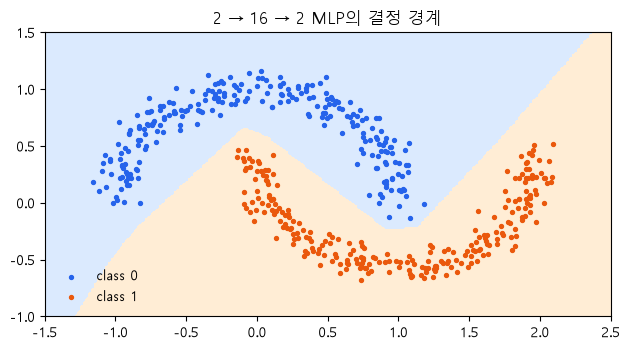

In [45]:
# ---------- 8. 종합 실습 ----------
# 결정 경계 그림: 격자 점마다 예측 class (학습 데이터 위에)
plt.rcParams["font.family"] = "Malgun Gothic"  # 한글 글꼴
plt.rcParams["axes.unicode_minus"] = False     # 음수 기호 깨짐 방지
plt.rcParams["font.size"] = 10                 # 본문 10pt

gx, gy = torch.linspace(-1.5, 2.5, 200), torch.linspace(-1.0, 1.5, 150)     # 가로 · 세로 눈금
xs, ys = torch.meshgrid(gx, gy, indexing="xy")                              # 격자 (150, 200)
grid_points = torch.stack([xs.reshape(-1), ys.reshape(-1)], dim=1).to(day02_device)  # (30000, 2)
with torch.no_grad():                                                       # 평가
    grid_class = pipeline_model(grid_points).argmax(dim=1).reshape(xs.shape).cpu()  # 격자마다 class
fig, ax = plt.subplots(figsize=(6.4, 3.6))                                  # 그림 한 장
ax.contourf(xs, ys, grid_class, levels=[-0.5, 0.5, 1.5], colors=["#dbeafe", "#ffedd5"])  # 경계 색
for c, color in [(0, "#2563eb"), (1, "#ea580c")]:                           # class마다 점
    pts = day02_features[day02_targets == c]                                # 그 class의 점
    ax.scatter(pts[:, 0], pts[:, 1], s=8, color=color, label=f"class {c}")  # 그리기
ax.set_title("2 → 16 → 2 MLP의 결정 경계", fontsize=12)                     # 제목
ax.legend(loc="lower left", frameon=False)                                  # 범례
fig.tight_layout()  # 여백 정리 (노트북은 셀 끝에서 그림을 자동 표시)